# OSM road features for accident prediction: extraction, matching, gap-filling and analysis
**CS5284 Group 01, Initiative 1a (road features from OpenStreetMap). Study states: Delaware (DE) and Maryland (MD).**

## What this notebook does, in one paragraph
The accident benchmark describes each road with little more than its length, direction of travel and road type (traffic volume is available only for a small share of roads). Here we pull richer road attributes from OpenStreetMap
(speed limit, lanes, surface, signals, crossings, nearby schools and shops, road shape, ...), attach them to the benchmark's
road segments, measure honestly how much of the network they cover, fill some of the gaps with validated estimates, and show
how accident rates change with the **value** of each feature. It ends with a model-ready feature table, a data dictionary and
a limitations register for whoever builds the models. **No model is trained here.**

## What you get at the end
| Output | Where | Who uses it |
|---|---|---|
| `{STATE}_osm_edge_features.parquet` + `_osm_meta.json` | Drive `data/` | raw 58 features, one row per directed road, in the dataset's adjacency order |
| `{STATE}_osm_model_features.parquet` + `_meta.json` | Drive `data/` | **model-ready hand-off**: raw features + gap-filled speed limit / lanes / surface with `is_est` flags, feature-group definitions, preprocessing recipe |
| `{STATE}_osm_enriched.npz` | Drive `data/` | **the benchmark with the features attached**: one row per directed road in the benchmark's order. Load it with the loader cell in Section 13.5 (`read_enriched_data`; the team's `utils.read_data` is called unchanged); Section 13.6 is a guide to the data |
| `osm_data_dictionary.csv` | Drive `data/` | every column: group, meaning, unit, missing-value rule, fill rate |
| Figures (PNG) | Drive `figures/` | report and slides; every title states the finding |
| `osm_value_trends_*.csv`, `osm_effects_*.csv`, `osm_gap_filling_validation.csv` | Drive `data/` | the numbers behind Figures 4, 5 and 7 |
| `osm_findings.md`, `osm_limitations.csv` (also printed in Section 14) | Drive `data/` | report text and the limitations register; every number is computed by the run |

## How to read it
1. **Section 1** sets everything up and holds *all* thresholds in one place (the config cell).
2. **Section 2** holds the small helper functions (parsers, plot style, spatial index). Collapse it unless you are curious.
3. **Sections 3 to 7** are the pipeline: extract, load and clean, match, build features, run. Each technique has a *What / Why / Evidence / Alternative* block.
4. **Sections 8 to 12** are the analysis: matching quality, coverage, gap-filling, value-based trends, joint model, and stability across states and time windows.
5. **Section 13** is the hand-off for the modelling code; **Section 14** is the findings, the limitations and the open decisions. **Appendix A** has risk maps and **Appendix B** an optional Delaware reproducibility check.

## Design decisions that shape every result
* **Trends use feature values, not whether a tag exists.** If a road has no speed-limit tag, that is missing information, not a
  property of the road. Missing values are excluded from every trend and reported separately as coverage.
* **Estimates never replace real values.** Gap-filled columns are separate, flagged, and used only in the hand-off, never in the trend analysis.
* **Headline numbers use each state's full usable period** (Delaware 2009-01 to 2022-09, Maryland 2015-01 to 2022-12). The paper's training years are repeated as a robustness check.
* **No feature is selected, dropped or filled using accident counts**, so describing the full period leaks nothing into a later model.
* **Raw values are saved unscaled.** Scaling and encoding are left to the modelling code, with a written recipe.

**Run All works.** Features load from Drive if they were saved; a state is built (slow, memory-heavy) only if its files are missing or `FORCE_REBUILD` is set.

## 1. Setup and configuration
### 1.1 Libraries and folders
Runs on Colab (mounts Drive) or on any machine with the same folder layout (set `CS5284_PROJECT_DIR`).
Needed in the project folder: `data/` with `DE.zip`, `MD.zip` and the Geofabrik files `delaware-*.osm.pbf`, `maryland-*.osm.pbf`
(the `.pbf` files are only needed when a state has to be built), and `scripts/utils.py` (the team's data loader).

In [1]:
import ast, gc, importlib, json, os, re, shutil, subprocess, sys, time, warnings, zipfile
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60, "display.width", 200, "display.max_rows", 120)

def pip_install_if_missing(import_name, spec):
    """Install a package only if it cannot be imported (so re-running is fast)."""
    try:
        importlib.import_module(import_name)
    except ImportError:
        print(f"installing {spec} ...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", spec], check=True)

# osmnx 2.x is what this code was written for. Bounded, not exact, so Colab can pick a build for its Python.
pip_install_if_missing("osmnx", "osmnx>=2.0,<3")
pip_install_if_missing("statsmodels", "statsmodels")
pip_install_if_missing("pyarrow", "pyarrow")
pip_install_if_missing("psutil", "psutil")

try:                                    # Colab
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
    PROJECT_DIR = Path("/content/drive/MyDrive/cs5284_project")
    LOCAL_DATA_DIR = Path("/content/data")
except ImportError:                     # any other machine
    IN_COLAB = False
    PROJECT_DIR = Path(os.environ.get("CS5284_PROJECT_DIR", "./cs5284_project")).resolve()
    LOCAL_DATA_DIR = Path(os.environ.get("CS5284_LOCAL_DIR", str(PROJECT_DIR / "local_cache"))).resolve()

DATA_DIR = PROJECT_DIR / "data"
SCRIPT_DIR = PROJECT_DIR / "scripts"
FIGURE_DIR = PROJECT_DIR / "figures"        # every figure is shown here in the notebook AND saved as a PNG; set to None to skip saving
LOCAL_DATA_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(SCRIPT_DIR.resolve()))
print("project:", PROJECT_DIR, "| colab:", IN_COLAB)

installing osmnx>=2.0,<3 ...
Mounted at /content/drive
project: /content/drive/MyDrive/cs5284_project | colab: True


### 1.2 Configuration: every threshold and switch in one place
Nothing below is hidden inside a function. Each value is a judgement call, and the *Evidence* blocks later show what it does.
The values are saved into the metadata files, so a saved feature table always says which thresholds produced it.

In [2]:
# ---- What to run ---------------------------------------------------------------------------------------------------
STATES = ["DE", "MD"]
FORCE_REBUILD = False          # True: rebuild the features of every state in STATES even if saved (slow). Needed once to add the new diagnostic columns to old files.
RUN_DELAWARE_CHECK = False     # True: appendix check that the memory-saving pipeline still reproduces the saved Delaware features

# ---- Accident data (cleaning decisions; see section 4 for the evidence) ----------------------------------------------
USABLE_MONTHS = {"DE": ("2009-01", "2022-09")}   # DE: only 2022-10 is a partial month and is dropped (2009 runs at a lower but steady level). MD needs no cleaning.
# Temporal split of the benchmark paper (Table 7), kept for the robustness check and for the hand-off to the models.
# Headline trends use each state's FULL usable period. The paper's training years are repeated as a robustness check.
# No feature is selected, dropped or filled using accident counts, so using all years for description does not leak anything into a model.
# Please verify the Delaware row against the paper's Table 7: train 2009-2012, validation 2013-2017, test 2018-2022.
SPLIT = {
    "DE": {"train": ("2009-01", "2012-12"), "val": ("2013-01", "2017-12"), "test": ("2018-01", "2022-09")},
    "MD": {"train": ("2015-01", "2017-12"), "val": ("2018-01", "2019-12"), "test": ("2020-01", "2022-12")},
}
HEADLINE_WINDOW = "full"       # headline trends use all usable months; "train" (the paper's training years) is the robustness check

# ---- Matching thresholds (section 5) ---------------------------------------------------------------------------------
NODE_SNAP_MAX_M = 20           # accept the nearest OSM node only if it is within this distance
NODE_ID_COORD_TOL_M = 25       # an ID match counts only if the two positions are within this distance
ROAD_NEAREST_MAX_M = 30        # nearest-road fallback: accept only if the road midpoint is within this distance
ROAD_LEN_RATIO_RANGE = (0.6, 1.6)  # nearest-road fallback: OSM length / dataset length must be in this range
MIDBLOCK_NODE_MAX_M = 15       # a tagged point removed by simplification is attached to the nearest road only within this distance

# ---- Feature building (section 6) ------------------------------------------------------------------------------------
PLACE_RADII_M = (100, 250, 500, 1000)   # count places within these distances of each road's midpoint
RARE_CATEGORY_MIN_ROADS = 50            # surface categories with fewer roads than this are folded into "other"

# ---- Gap-filling (section 10) ----------------------------------------------------------------------------------------
IMPUTE_FEATURES = {"g1_maxspeed_mph": "speed", "g1_lanes": "lanes", "g1_surface": "surface"}
IMPUTE_FOLDS = 5               # masked cross-validation: hide 1/5 of the known values, fill them, compare, repeat
IMPUTE_MIN_GAIN = 0.05         # a filling method is kept only if its accuracy beats the state-wide typical value by at least this much
IMPUTE_MIN_ACCURACY = 0.60     # ... and is at least this accurate in absolute terms, both in validation and as the expected accuracy on the roads that are really missing
IMPUTE_NEIGHBOUR_EXTRA = 0.01  # neighbour-aware filling must beat the road-type-only method by this much to be used
SPEED_TOLERANCE_MPH = 5        # a speed-limit estimate counts as correct if it is within this many mph

# ---- Analysis (sections 9 to 12) -------------------------------------------------------------------------------------
MIN_ACCIDENTS_FOR_VERDICT = 100   # a level needs at least this many accidents before it is judged
MIN_EFFECT_RATIO = 1.25           # ratios between 1/1.25 (0.8) and 1.25 count as "no meaningful difference"
MISSING_LEVEL_LABELS = ("untagged", "unmatched")   # legacy labels; trend analysis no longer has them (missing values are excluded)
MIN_ROADS_FOR_ROAD_TYPE = 100     # road types with fewer roads are pooled as "rare_type" in models
RANDOM_SEED = 0

### 1.3 Look of the figures and the pipeline overview (Figure 0)
One quiet style for every figure: light background, thin recessive grid, left-aligned titles, and a title that **states the finding**.
Colour follows the entity: blue is always Delaware, orange is always Maryland (a colour-blind-safe pair).
Single-hue blue ramps show magnitude. Text is never coloured by series.

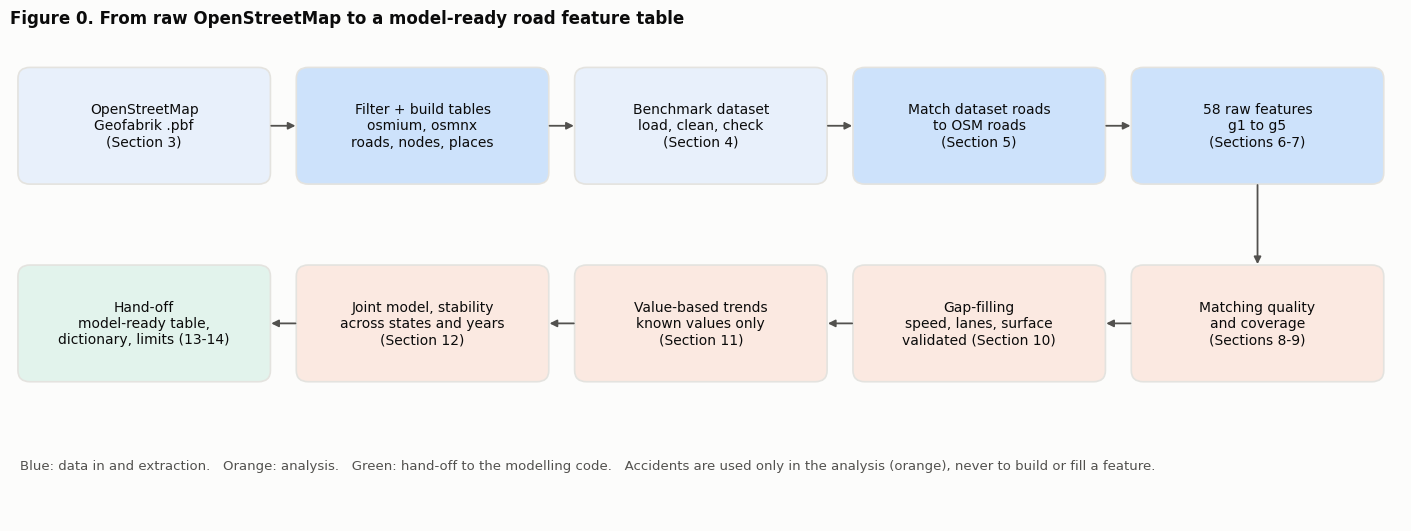

In [3]:
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch

STATE_COLORS = {"DE": "#2a78d6", "MD": "#eb6834"}
SURFACE, INK, INK_SECONDARY, INK_MUTED, GRID_COLOR = "#fcfcfb", "#0b0b0b", "#52514e", "#8a8984", "#e4e3df"
BLUE_RAMP = ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
GROUP_COLORS = {"g1": "#2a78d6", "g2": "#eb6834", "g3": "#1baf7a", "g4": "#6250d6", "g5": "#eda100"}
SEQ_CMAP = LinearSegmentedColormap.from_list("blue_ramp", BLUE_RAMP)

def apply_chart_style():
    """Set the look shared by all figures."""
    plt.rcParams.update({
        "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
        "axes.edgecolor": GRID_COLOR, "axes.labelcolor": INK_SECONDARY, "text.color": INK,
        "xtick.color": INK_SECONDARY, "ytick.color": INK_SECONDARY,
        "axes.spines.top": False, "axes.spines.right": False,
        "grid.color": GRID_COLOR, "grid.linewidth": 0.8,
        "font.size": 10.5, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
        "figure.titlesize": 14, "figure.titleweight": "bold",
        "legend.frameon": False, "axes.axisbelow": True,
    })

def save_figure(fig, name, figure_dir=None):
    """Save a figure as a PNG in `figure_dir` (created if needed); does nothing if `figure_dir` is None."""
    figure_dir = FIGURE_DIR if figure_dir is None else figure_dir
    if figure_dir is None:
        return
    Path(figure_dir).mkdir(parents=True, exist_ok=True)
    fig.savefig(Path(figure_dir) / f"{name}.png", dpi=200, bbox_inches="tight")

def draw_pipeline_overview():
    """Figure 0: the whole pipeline as boxes and arrows (no data needed)."""
    apply_chart_style()
    fig, ax = plt.subplots(figsize=(14, 5.2), layout="constrained")
    ax.set_xlim(0, 14); ax.set_ylim(0, 5.2); ax.axis("off")
    width, step = 2.5, 2.8   # five columns with a clear gap for the arrows
    top = [("OpenStreetMap\nGeofabrik .pbf\n(Section 3)", "src"), ("Filter + build tables\nosmium, osmnx\nroads, nodes, places", "ext"),
           ("Benchmark dataset\nload, clean, check\n(Section 4)", "src"), ("Match dataset roads\nto OSM roads\n(Section 5)", "ext"),
           ("58 raw features\ng1 to g5\n(Sections 6-7)", "ext")]
    bottom = [("Matching quality\nand coverage\n(Sections 8-9)", "ana"), ("Gap-filling\nspeed, lanes, surface\nvalidated (Section 10)", "ana"),
              ("Value-based trends\nknown values only\n(Section 11)", "ana"), ("Joint model, stability\nacross states and years\n(Section 12)", "ana"),
              ("Hand-off\nmodel-ready table,\ndictionary, limits (13-14)", "out")]
    fill = {"src": "#e8f0fb", "ext": "#cde2fb", "ana": "#fbe9e1", "out": "#e2f3ec"}
    arrow = dict(arrowstyle="-|>", color=INK_SECONDARY, lw=1.3, shrinkA=2, shrinkB=2)
    for k in range(5):
        x = 0.1 + k * step
        ax.add_patch(FancyBboxPatch((x, 3.6), width, 1.2, boxstyle="round,pad=0.02,rounding_size=0.12", fc=fill[top[k][1]], ec=GRID_COLOR, lw=1.2))
        ax.text(x + width / 2, 4.2, top[k][0], ha="center", va="center", fontsize=10, color=INK)
        x_b = 0.1 + (4 - k) * step   # second row runs right to left, starting under the last box of the first row
        ax.add_patch(FancyBboxPatch((x_b, 1.5), width, 1.2, boxstyle="round,pad=0.02,rounding_size=0.12", fc=fill[bottom[k][1]], ec=GRID_COLOR, lw=1.2))
        ax.text(x_b + width / 2, 2.1, bottom[k][0], ha="center", va="center", fontsize=10, color=INK)
        if k < 4:
            ax.annotate("", xy=(x + step, 4.2), xytext=(x + width, 4.2), arrowprops=arrow)
            ax.annotate("", xy=(x_b - (step - width), 2.1), xytext=(x_b, 2.1), arrowprops=arrow)
    ax.annotate("", xy=(0.1 + 4 * step + width / 2, 2.7), xytext=(0.1 + 4 * step + width / 2, 3.6), arrowprops=arrow)
    ax.text(0.1, 0.55, "Blue: data in and extraction.   Orange: analysis.   Green: hand-off to the modelling code.   "
                       "Accidents are used only in the analysis (orange), never to build or fill a feature.",
            fontsize=9.5, color=INK_SECONDARY)
    ax.set_title("Figure 0. From raw OpenStreetMap to a model-ready road feature table", loc="left")
    save_figure(fig, "fig0_pipeline_overview")
    plt.show()

draw_pipeline_overview()

### 1.4 Environment record
Versions are printed and saved into the metadata, so a result can be traced to the software that made it.

In [4]:
def environment_record():
    """Versions of the libraries that matter for reproducing the numbers."""
    import statsmodels, scipy, matplotlib as mpl
    record = {"python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__,
              "statsmodels": statsmodels.__version__, "matplotlib": mpl.__version__}
    for name in ("osmnx", "geopandas", "shapely", "pyarrow"):
        try:
            record[name] = importlib.import_module(name).__version__
        except Exception:
            record[name] = "not installed"
    return record

ENVIRONMENT = environment_record()
print(json.dumps(ENVIRONMENT, indent=1))

{
 "python": "3.13.16",
 "numpy": "2.1.3",
 "pandas": "2.2.3",
 "scipy": "1.16.3",
 "statsmodels": "0.15.0",
 "matplotlib": "3.10.0",
 "osmnx": "2.1.1",
 "geopandas": "1.2.0",
 "shapely": "2.2.0",
 "pyarrow": "23.0.1"
}


## 2. Helper functions (one section; collapse it)
Small, general tools used throughout. The *methods* of the study (matching, feature building, gap-filling, trend analysis)
are **not** here: each is defined in the section that explains it.

| Group | Functions |
|---|---|
| OSM tag parsing | `as_text_list`, `parse_maxspeed_mph`, `parse_lanes`, `first_text`, `tag_is_set`, `yes_no_or_untagged`, `road_tag_values`, `node_tag_values` |
| Geometry and lookup | `straight_line_distance_m`, `nearest_osm_node`, `nearest_osm_road` |
| Statistics | `poisson_interval`, `weighted_trend` |
| Display | `md`, `pct`, `grouped_horizontal_bars`, `memory_report` |

In [5]:
import geopandas as gpd
import shapely
from scipy.spatial import cKDTree
from scipy.stats import chi2, norm
from shapely import STRtree
from IPython.display import Markdown, display

# ---------------------------------------------------------------- OSM tag parsing
def as_text_list(value):
    """Turn an OSM tag value into a list of lowercase strings.

    OSM tags can hold one value ("25 mph"), several joined by osmnx into a list (["25 mph", "30 mph"]),
    or a string that looks like a list. Missing values give an empty list.
    """
    if isinstance(value, (list, tuple, set, np.ndarray)):
        return [str(v).strip().lower() for v in value]
    if value is None or pd.isna(value):
        return []
    text = str(value).strip().lower()
    if text.startswith("["):
        try:
            return [str(v).strip().lower() for v in ast.literal_eval(text)]
        except (ValueError, SyntaxError):
            pass
    return [text]


def parse_maxspeed_mph(value):
    """Speed limit in mph. Takes the highest if several; unit-less numbers are mph (US); km/h is converted.
    Words such as "none" or "signals" give NaN."""
    speeds = []
    for item in as_text_list(value):
        match = re.match(r"\s*(\d+(?:\.\d+)?)\s*(mph|km/h|kmh|kph)?", item)
        if match:
            number, unit = float(match.group(1)), match.group(2)
            speeds.append(number / 1.609344 if unit in ("km/h", "kmh", "kph") else number)
    return max(speeds) if speeds else np.nan


def parse_lanes(value):
    """Number of lanes. Takes the highest number if several are listed; missing gives NaN."""
    numbers = [float(n) for item in as_text_list(value) for n in re.findall(r"\d+(?:\.\d+)?", item)]
    return max(numbers) if numbers else np.nan


def first_text(value):
    """First value of a text tag, lowercase; missing gives NaN."""
    items = as_text_list(value)
    return items[0] if items else np.nan


def tag_is_set(value):
    """1.0 if the tag is present and not a "no"-type value (e.g. bridge=yes or bridge=viaduct), else 0.0."""
    items = as_text_list(value)
    return float(any(item not in ("no", "none", "false", "0", "") for item in items))


NO_VALUES = ("no", "none", "false", "0", "")  # tag values that mean "this is not present"


def yes_no_or_untagged(items):
    """From a list of tag values: 1.0 if any says the thing is present, 0.0 if all say no, NaN if untagged."""
    if not items:
        return np.nan
    return float(any(item not in NO_VALUES for item in items))


def road_tag_values(osm_roads, name):
    """One OSM road tag as a column; if no road has the tag at all, an empty column (with a notice)."""
    if name not in osm_roads.columns:
        print(f"notice: no OSM road has the tag '{name}'")
        return pd.Series(np.nan, index=range(len(osm_roads)), dtype=object)
    return osm_roads[name].reset_index(drop=True)


def node_tag_values(osm_nodes, name):
    """One OSM node tag as a column indexed by OSM node id; empty if no node has the tag."""
    if name not in osm_nodes.columns:
        print(f"notice: no OSM node has the tag '{name}'")
        return pd.Series(np.nan, index=osm_nodes.index, dtype=object)
    return osm_nodes[name]


# ---------------------------------------------------------------- geometry and nearest-object lookup
EARTH_RADIUS_M = 6371000.0


def straight_line_distance_m(lat1, lon1, lat2, lon2):
    """Distance in metres along the Earth's surface between two lat/lon points (haversine). Works on numbers or arrays."""
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * EARTH_RADIUS_M * np.arcsin(np.sqrt(a))


_SPATIAL_INDEX = {}  # spatial indexes are built once per table and reused


def nearest_osm_node(osm_nodes, x, y):
    """The OSM node closest to each point, found with a KD-tree on the node positions.

    Does what osmnx's nearest_nodes does, but needs only the node table, not the (very large) graph.
    Takes `osm_nodes` (positions in metres) and the points' x and y in the same metre coordinates.
    Returns (OSM node ids, distances in metres), one per point.
    """
    key = ("nodes", id(osm_nodes), len(osm_nodes))
    if key not in _SPATIAL_INDEX:
        _SPATIAL_INDEX[key] = cKDTree(np.column_stack([osm_nodes.geometry.x.to_numpy(), osm_nodes.geometry.y.to_numpy()]))
    distance, position = _SPATIAL_INDEX[key].query(np.column_stack([x, y]))
    return osm_nodes.index.to_numpy()[position], distance


def nearest_osm_road(osm_roads, x, y):
    """The OSM road closest to each point, found with a spatial index on the road shapes.

    Does what osmnx's nearest_edges does, but needs only the road table. The two directions of a two-way road
    have the same shape, so one of them is returned.
    Returns (position of the closest road in `osm_roads`, distance in metres), one per point.
    """
    key = ("roads", id(osm_roads), len(osm_roads))
    if key not in _SPATIAL_INDEX:
        _SPATIAL_INDEX[key] = STRtree(osm_roads.geometry.to_numpy())
    pairs, distance = _SPATIAL_INDEX[key].query_nearest(shapely.points(x, y), return_distance=True, all_matches=False)
    position = np.full(len(x), -1)
    nearest_distance = np.full(len(x), np.nan)
    position[pairs[0]] = pairs[1]  # row 0: the point, row 1: the closest road
    nearest_distance[pairs[0]] = distance
    return position, nearest_distance


# ---------------------------------------------------------------- statistics
def poisson_interval(k, exposure):
    """Exact 95% Poisson interval for a rate: k events over `exposure` (arrays or numbers). Returns (low, high)."""
    k = np.asarray(k, dtype=float)
    exposure = np.asarray(exposure, dtype=float)
    low = np.where(k > 0, chi2.ppf(0.025, 2 * np.maximum(k, 1)) / 2 / exposure, 0.0)
    high = chi2.ppf(0.975, 2 * k + 2) / 2 / exposure
    return low, high


def weighted_trend(positions, log_ratio, se_log):
    """Straight-line trend of log(rate ratio) against the level's position (0, 1, 2, ...), weighted by 1/se^2.

    Why: to say in words whether the rate rises or falls as a feature's value increases, without reading every bar.
    Returns (slope per step as a ratio, p-value). The slope is exp(b), so 1.2 means +20% per step.
    Needs at least 3 levels with a usable standard error; otherwise returns (nan, nan).
    """
    x = np.asarray(positions, dtype=float)
    y = np.asarray(log_ratio, dtype=float)
    se = np.asarray(se_log, dtype=float)
    ok = np.isfinite(x) & np.isfinite(y) & np.isfinite(se) & (se > 0)
    if ok.sum() < 3:
        return np.nan, np.nan
    x, y, w = x[ok], y[ok], 1 / se[ok] ** 2
    x_bar = np.sum(w * x) / np.sum(w)
    sxx = np.sum(w * (x - x_bar) ** 2)
    if sxx <= 0:
        return np.nan, np.nan
    slope = np.sum(w * (x - x_bar) * (y - np.sum(w * y) / np.sum(w))) / sxx
    # residual-based standard error (does not assume the reported se are exactly right)
    intercept = np.sum(w * y) / np.sum(w) - slope * x_bar
    residual = y - intercept - slope * x
    dof = ok.sum() - 2
    scale = max(np.sum(w * residual ** 2) / dof, 1.0)   # never smaller than the reported precision
    slope_se = np.sqrt(scale / sxx)
    return float(np.exp(slope)), float(2 * (1 - norm.cdf(abs(slope / slope_se))))


# ---------------------------------------------------------------- display
def md(text):
    """Show text as formatted Markdown in the notebook."""
    display(Markdown(text))


def pct(value, digits=1):
    """0.1234 -> '12.3%'. NaN -> 'n/a'."""
    return "n/a" if value is None or not np.isfinite(value) else f"{100 * value:.{digits}f}%"


def memory_report(label):
    """Print how much memory this notebook's process is using right now, to find which stage needs the most."""
    import resource

    import psutil
    now = psutil.Process().memory_info().rss / 1e9
    peak = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e6  # Linux reports kB
    print(f"[memory] {label}: now {now:.1f} GB, highest so far {peak:.1f} GB")


def grouped_horizontal_bars(ax, table, states, xlabel, value_format="{:.1%}"):
    """Horizontal bars, one group per row of `table` and one bar per state, with the value at the end of each bar."""
    positions = np.arange(len(table))
    x_max = max(float(np.nanmax(table[list(states)].to_numpy())) * 1.2, 0.05)
    offsets = (-0.2, 0.2) if len(states) == 2 else (0.0,)
    for offset, state in zip(offsets, states):
        ax.barh(positions + offset, table[state].to_numpy(), height=0.34, color=STATE_COLORS[state], label=state)
        for y, value in zip(positions + offset, table[state].to_numpy()):
            ax.text(value + 0.012 * x_max, y, value_format.format(value), va="center", fontsize=9, color=INK_SECONDARY)
    ax.set_yticks(positions)
    ax.set_yticklabels(table.index)
    ax.invert_yaxis()
    ax.set_xlim(0, x_max)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
    ax.set_xlabel(xlabel)
    ax.xaxis.grid(True)

### Self-test of the tag parsers
The parsers decide what every speed limit and lane count means, so they are checked against hand-written cases before anything runs.
A failing assertion stops the notebook here rather than corrupting the features silently.

In [6]:
assert parse_maxspeed_mph("25 mph") == 25
assert parse_maxspeed_mph("35") == 35                                   # unit-less is mph in the US
assert abs(parse_maxspeed_mph("80 km/h") - 49.7) < 0.1                  # km/h converted
assert parse_maxspeed_mph(["25 mph", "35 mph"]) == 35                   # several values: the highest
assert np.isnan(parse_maxspeed_mph("none")) and np.isnan(parse_maxspeed_mph("signals")) and np.isnan(parse_maxspeed_mph(np.nan))
assert parse_lanes("2") == 2 and parse_lanes(["2", "3"]) == 3 and np.isnan(parse_lanes(np.nan))
assert tag_is_set("yes") == 1.0 and tag_is_set("viaduct") == 1.0 and tag_is_set("no") == 0.0 and tag_is_set(np.nan) == 0.0
assert yes_no_or_untagged(["yes"]) == 1.0 and yes_no_or_untagged(["no"]) == 0.0 and np.isnan(yes_no_or_untagged([]))
assert first_text("Asphalt") == "asphalt" and isinstance(first_text(np.nan), float)
low, high = poisson_interval(10, 1.0)
assert 4.7 < low < 4.9 and 18 < high < 18.6                              # exact interval for 10 events
print("tag parsers and interval helper: all checks passed")

tag parsers and interval helper: all checks passed


In [7]:
def df_to_markdown(table, float_format="{:,.3g}"):
    """A small DataFrame as a Markdown table (so wide text wraps nicely in the notebook)."""
    columns = [str(table.index.name or "")] + [str(c) for c in table.columns]
    lines = ["| " + " | ".join(columns) + " |", "|" + "---|" * len(columns)]
    for index, row in table.iterrows():
        cells = [str(index)]
        for value in row.tolist():
            if isinstance(value, (float, np.floating)):
                cells.append("" if not np.isfinite(value) else float_format.format(value))
            else:
                cells.append(str(value).replace("|", "/").replace("\n", " "))
        lines.append("| " + " | ".join(cells) + " |")
    return "\n".join(lines)

## 3. Extracting OpenStreetMap data

> **What.** For each state we take a dated OpenStreetMap snapshot (a Geofabrik `.pbf` file) and cut it into three things:
> (1) the road ways of the 14 road types the benchmark uses, as `.osm` XML; (2) the places that matter for the "surroundings" features
> (schools, bars, restaurants, bus stops, parking), as GeoJSON; (3) from the road XML, two flat tables with osmnx: OSM *nodes* (junctions) and OSM *roads*
> (one row per directed road piece, with its tags and shape in metres).
>
> **Why.** The public Overpass server was at capacity, and a downloaded snapshot is reproducible: the same file gives the same features.
> osmnx cannot read `.pbf`, and the full file holds far more than roads, so `osmium` filters first. Only the two tables are kept in memory; the graph object
> is dropped, because Maryland's graph needs about 10 GB while it is built and nothing later needs it.
>
> **Evidence.** Section 7 prints the size check (OSM nodes and roads against the dataset's) and the memory use at each stage.
>
> **Alternatives considered.** Overpass API (not reproducible, rate-limited); `pyrosm` (reads `.pbf` directly, but we already needed `osmnx` for simplification and street counts);
> keeping the whole graph (simpler code, but out of memory for Maryland on a standard Colab machine).
>
> **Limit.** The snapshot is newer than the accident years. Roads built, renamed or re-tagged since then differ from what existed when the accidents happened (see the limitations register).

In [8]:
STATE_NAMES = {"DE": "delaware", "MD": "maryland"}  # Geofabrik file names start with these

# The dataset's 14 road types; the road file keeps only ways with one of these `highway` values.
ROAD_HIGHWAY_VALUES = ["motorway", "motorway_link", "trunk", "trunk_link", "primary", "primary_link",
                       "secondary", "secondary_link", "tertiary", "tertiary_link", "unclassified",
                       "residential", "living_street", "road"]

# Places for the g4 "surroundings" group: `amenity` values, and bus stops (a `highway` value).
PLACE_AMENITY_VALUES = ["school", "bar", "pub", "restaurant", "fast_food", "parking"]
PLACE_HIGHWAY_VALUES = ["bus_stop"]


def run_osmium(arguments):
    """Run one osmium command line (installing osmium-tool first if Colab does not have it) and stop on failure."""
    if shutil.which("osmium") is None:
        print("installing osmium-tool ...")
        subprocess.run(["apt-get", "-qq", "install", "-y", "osmium-tool"], check=True)
    print("osmium", " ".join(str(a) for a in arguments))
    subprocess.run(["osmium", *[str(a) for a in arguments]], check=True)


def find_state_pbf(state, data_dir):
    """The Geofabrik .pbf for a state in the Drive data folder (e.g. delaware-261018.osm.pbf).

    If several dated files exist, the latest date is used.
    """
    candidates = sorted(data_dir.glob(f"{STATE_NAMES[state]}-*.osm.pbf"))
    if not candidates:
        raise FileNotFoundError(f"No {STATE_NAMES[state]}-*.osm.pbf in {data_dir}. Download it from Geofabrik first.")
    print("using", candidates[-1].name)
    return candidates[-1]


def prepare_osm_roads_zip(state, data_dir, local_dir, overwrite=False):
    """Make `{state}_osm_roads.zip` in the Drive data folder from the state's Geofabrik .pbf.

    Keeps only the dataset's road types (with the points they use and those points' tags) and writes them as .osm XML,
    which osmnx can read. If the zip already exists and overwrite is False, nothing happens. Returns the zip's path.
    """
    zip_path = data_dir / f"{state}_osm_roads.zip"
    if zip_path.exists() and not overwrite:
        print(f"{zip_path.name} already exists; skipping")
        return zip_path

    pbf = find_state_pbf(state, data_dir)
    filtered = local_dir / f"{state}_roads.osm.pbf"
    xml = local_dir / f"{state}_roads.osm"

    # Keep only ways tagged with one of the road types (osmium keeps the nodes they use by default).
    run_osmium(["tags-filter", pbf, "w/highway=" + ",".join(ROAD_HIGHWAY_VALUES), "-o", filtered, "--overwrite"])
    # Convert to XML, the format osmnx reads.
    run_osmium(["cat", filtered, "-o", xml, "--overwrite"])

    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
        archive.write(xml, arcname=xml.name)
    for path in (filtered, xml, zip_path):
        print(f"{path.name}: {path.stat().st_size / 1e6:.1f} MB")
    return zip_path


def prepare_osm_places_zip(state, data_dir, local_dir, overwrite=False):
    """Make `{state}_osm_places.zip` in the Drive data folder: schools, bars, restaurants, bus stops, parking.

    Places can be points or areas (a school is often an outline), so they are exported as GeoJSON and the centre of
    each is used later. If the zip already exists and overwrite is False, nothing happens. Returns the zip's path.
    """
    zip_path = data_dir / f"{state}_osm_places.zip"
    if zip_path.exists() and not overwrite:
        print(f"{zip_path.name} already exists; skipping")
        return zip_path

    pbf = find_state_pbf(state, data_dir)
    filtered = local_dir / f"{state}_places.osm.pbf"
    geojson = local_dir / f"{state}_places.geojsonseq"

    # Keep nodes, ways and relations (nwr) with any of the place tags.
    run_osmium(["tags-filter", pbf, "nwr/amenity=" + ",".join(PLACE_AMENITY_VALUES),
                "nwr/highway=" + ",".join(PLACE_HIGHWAY_VALUES), "-o", filtered, "--overwrite"])
    # One GeoJSON feature per line; areas become polygons.
    run_osmium(["export", filtered, "-f", "geojsonseq", "-o", geojson, "--overwrite"])

    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
        archive.write(geojson, arcname=geojson.name)
    for path in (filtered, geojson, zip_path):
        print(f"{path.name}: {path.stat().st_size / 1e6:.1f} MB")
    return zip_path


def load_osm_drive_network_from_zip(state, data_dir, local_dir):
    """Build the OSM road network for a state from the zip saved on Drive.

    Returns `osm_graph` (osmnx graph in metres), `osm_nodes` (one row per OSM node with its tags) and
    `osm_roads` (one row per directed OSM road, index = start node, end node, key).
    """
    import osmnx as ox
    print("osmnx version:", ox.__version__)

    # Unpack the XML into local storage, unless it is already there (utils.read_data may have done it).
    xml_path = local_dir / f"{state}_roads.osm"
    if not xml_path.exists():
        with zipfile.ZipFile(data_dir / f"{state}_osm_roads.zip") as archive:
            archive.extractall(local_dir)

    # Ask for the extra tags BEFORE building; osmnx drops tags it was not told to keep.
    # Keep only the tags our features use: fewer tags means a smaller graph in memory.
    ox.settings.useful_tags_way = ["highway", "maxspeed", "lanes", "surface", "bridge", "tunnel", "junction", "oneway",
                                   "lit", "sidewalk", "cycleway", "cycleway:left", "cycleway:right", "cycleway:both"]
    ox.settings.useful_tags_node = ["highway", "crossing", "traffic_calming"]

    # simplify=True merges road bends so a road runs between intersections.
    # retain_all=True keeps disconnected pieces of the network instead of only the largest one.
    osm_graph = ox.graph_from_xml(xml_path, simplify=True, retain_all=True)

    # Convert coordinates to metres so distances and thresholds are in metres.
    osm_graph = ox.project_graph(osm_graph)

    osm_nodes, osm_roads = ox.graph_to_gdfs(osm_graph)
    return osm_graph, osm_nodes, osm_roads


def build_osm_tables(state, data_dir, local_dir):
    """Build the OSM nodes and roads tables in a separate process and save them, so the big graph never stays in memory.

    The work runs in a child process; when it exits, all its memory goes back to the system.
    IMPORTANT: run this BEFORE loading the dataset (utils.read_data), so the child has the memory to itself.
    Saves `{state}_osm_nodes.pkl` and `{state}_osm_roads.pkl` in the local folder (skipped if both already exist).
    """
    import multiprocessing

    nodes_path = local_dir / f"{state}_osm_nodes.pkl"
    roads_path = local_dir / f"{state}_osm_roads.pkl"
    if nodes_path.exists() and roads_path.exists():
        print(f"{state} OSM tables already built; skipping")
        return

    prepare_osm_roads_zip(state, data_dir, local_dir)
    memory_report("before the OSM build starts")

    def build():
        osm_graph, osm_nodes, osm_roads = load_osm_drive_network_from_zip(state, data_dir, local_dir)
        osm_nodes.to_pickle(nodes_path)
        osm_roads.to_pickle(roads_path)

    process = multiprocessing.get_context("fork").Process(target=build)
    process.start()
    process.join()
    if process.exitcode != 0:
        raise RuntimeError(f"OSM build failed (exit code {process.exitcode}). -9 means it ran out of memory.")
    memory_report("after the OSM build")


def load_osm_tables(state, local_dir):
    """Read the OSM nodes and roads tables saved by `build_osm_tables`. Returns (osm_nodes, osm_roads)."""
    return pd.read_pickle(local_dir / f"{state}_osm_nodes.pkl"), pd.read_pickle(local_dir / f"{state}_osm_roads.pkl")


def saved_feature_columns(state, data_dir):
    """Column names of a state's saved feature file, or None if there is no file."""
    path = data_dir / f"{state}_osm_edge_features.parquet"
    if not path.exists():
        return None
    import pyarrow.parquet as pq
    return pq.ParquetFile(path).schema.names

### 3.1 Run: build the OSM tables for any state that needs it
This is deliberately **before** the dataset is loaded (Section 4) so the build has the machine's memory to itself.
A state whose features are already saved is skipped unless `FORCE_REBUILD` is set.

In [9]:
for state in STATES:
    if saved_feature_columns(state, DATA_DIR) is not None and not FORCE_REBUILD:
        print(f"{state}: features already saved; no OSM build needed")
    else:
        build_osm_tables(state, DATA_DIR, LOCAL_DATA_DIR)

DE: features already saved; no OSM build needed
MD: features already saved; no OSM build needed


## 4. The benchmark dataset: loading, cleaning and first exploration

> **What.** The team loader `utils.read_data` unpacks the benchmark for each state. We turn its sparse matrices into two flat tables:
> one row per **node** (intersection) and one row per **directed road**, in the order of the adjacency matrix, because everything downstream
> (matching, the saved feature file, the GNN) relies on that order.
>
> **Why.** OSM matching needs coordinates per node and a length per road. The matrix form cannot be matched against OSM directly.
>
> **Evidence.** The cleaning log below shows, for every cleaning decision, the number that justifies it.
>
> **Alternative.** Matching on the sparse matrices directly (faster, but unreadable and impossible to check by eye).

In [10]:
def load_dataset_node_and_road_tables(info):
    """Turn the dataset's graph into two plain tables, one row per node and one per road.

    Takes `info`, the dict that `utils.read_data` returns for one state (e.g. data["DE"]).
    Returns:
        nodes: one row per intersection (node_id, lat, lon, node_idx).
        roads: one row per directed road, in the same order as `adj`
               (node_1_idx, node_2_idx, length_m, road_u, road_v, has_reverse, u_lt_v).
    The dataset's lat and lon columns are swapped; this function fixes that.
    """
    # The road network as a sparse matrix. coalesce() puts its entries in a fixed order.
    adj = info["adj"].coalesce()

    # Node files exist for every month; positions are the same in all of them, so take the first.
    nodes = pd.read_csv(next((info["filepath"] / "Nodes").glob("node_features_*.csv")))[["node_id", "lat", "lon"]]

    # The release has the two columns swapped: the column named lat holds longitudes and vice versa.
    nodes = nodes.rename(columns={"lat": "lon", "lon": "lat"})

    # Check the swap is fixed. DE and MD both lie between 37-41 N and 74-80 W.
    # A plain +/-90 check would not catch a swap, because -75 is also a valid latitude.
    assert nodes["lat"].between(37, 41).all() and nodes["lon"].between(-80, -74).all()

    # One row per matrix row, otherwise the node numbering cannot be trusted.
    assert len(nodes) == adj.shape[0]

    # The dataset refers to nodes by position (0, 1, 2, ...). Assumes the file rows are in that order.
    nodes["node_idx"] = np.arange(len(nodes))

    # Start and end node of every directed road, in the matrix's order. Keep this order.
    src, dst = adj.indices().numpy()
    roads = pd.DataFrame({"node_1_idx": src, "node_2_idx": dst})

    # Road lengths are stored in their own sparse matrix; turn it into a start / end / length table.
    L = info["edges"]["length"].coalesce()
    li = L.indices().numpy()
    length = pd.DataFrame({"node_1_idx": li[0], "node_2_idx": li[1], "length_m": L.values().numpy()})

    # Attach each road's length. how="left" keeps every road; the assert checks no rows were added or lost.
    n_before = len(roads)
    roads = roads.merge(length, how="left", on=["node_1_idx", "node_2_idx"])
    assert len(roads) == n_before, "length merge changed the number of roads"

    # Undirected road key: 17->18 and 18->17 both become (17, 18).
    roads["road_u"] = np.minimum(roads.node_1_idx, roads.node_2_idx)
    roads["road_v"] = np.maximum(roads.node_1_idx, roads.node_2_idx)

    # True if the opposite direction also exists, i.e. the road is two-way.
    pair = set(zip(roads.node_1_idx, roads.node_2_idx))
    roads["has_reverse"] = [(b, a) in pair for a, b in zip(roads.node_1_idx, roads.node_2_idx)]

    # True if the start node has the lower index. Crashes mostly sit on this direction.
    roads["u_lt_v"] = roads.node_1_idx < roads.node_2_idx
    return nodes, roads


EXPECTED_LENGTH_RATIO = (1.0, 1.3)  # a road is normally 0-30% longer than the straight line between its ends


def check_dataset_road_lengths(nodes, roads, verbose=True):
    """Check that the dataset's node order matches its road lengths.

    Roads refer to nodes by position. If the node file were in a different order, every coordinate we attach to a road
    would be wrong, and so would the OSM matching. A road's recorded length should be close to the straight-line distance
    between its ends. Returns the length / straight-line ratio for every road; raises an error if the median is outside
    EXPECTED_LENGTH_RATIO.
    """
    coverage = roads.length_m.notna().mean()
    assert coverage > 0.99, "too many roads without a length"

    lat, lon = nodes.lat.to_numpy(), nodes.lon.to_numpy()
    start, end = roads.node_1_idx.to_numpy(), roads.node_2_idx.to_numpy()
    straight = straight_line_distance_m(lat[start], lon[start], lat[end], lon[end])
    ratio = roads.length_m.to_numpy() / np.where(straight > 0, straight, np.nan)

    median = np.nanmedian(ratio)
    if verbose:
        print(f"roads with a length: {coverage:.4f}; median length / straight-line: {median:.3f} (expected {EXPECTED_LENGTH_RATIO})")
    if not (EXPECTED_LENGTH_RATIO[0] <= median <= EXPECTED_LENGTH_RATIO[1]):
        raise RuntimeError("Node order looks wrong: STOP and ask before continuing.")
    return ratio


def dataset_highway_class(info, roads):
    """The dataset's own road type for every road, as a text label.

    The dataset stores road type as 14 separate sparse matrices (one per type). We want one label per road so we can
    group results by road type. Returns a Series aligned with `roads` ("motorway", "residential", ...; "none" if no type
    was found). If a road has several types the last one found is used for this label, so the label is only a convenience for
    matching checks and gap-filling; roads with several types are EXCLUDED from the trend analysis (Section 11), which uses `.attrs["multi_type"]`.
    The counts of roads with no type or several types are kept in the Series' `.attrs` (`n_no_type`, `n_several_types`).
    """
    n_nodes = info["adj"].shape[0]
    road_key = roads["node_1_idx"].to_numpy().astype(np.int64) * n_nodes + roads["node_2_idx"].to_numpy()
    order = np.argsort(road_key)
    sorted_keys = road_key[order]

    label = np.full(len(roads), "none", dtype=object)
    n_types = np.zeros(len(roads), dtype=int)
    for name, matrix in info["edges"].items():
        if name in ("oneway", "length"):
            continue  # not road types
        matrix = matrix.coalesce()
        index, value = matrix.indices().numpy(), matrix.values().numpy()
        keys = index[0].astype(np.int64)[value > 0] * n_nodes + index[1][value > 0]

        # Find each key among the roads (a key that is not a road is skipped).
        position = np.minimum(np.searchsorted(sorted_keys, keys), len(roads) - 1)
        found = sorted_keys[position] == keys
        rows = order[position[found]]
        label[rows] = str(name)
        n_types[rows] += 1

    result = pd.Series(label, index=roads.index, name="highway_class")
    result.attrs["n_no_type"] = int((n_types == 0).sum())
    result.attrs["n_several_types"] = int((n_types > 1).sum())
    result.attrs["multi_type"] = (n_types > 1)   # boolean array aligned with `roads`, used to leave these roads out of the trend analysis
    return result


def accident_totals_in_period(info, roads, first_month, last_month):
    """Total accidents on each directed road between two months (inclusive), e.g. "2015-01" to "2017-12".

    Every label-based number goes through this function, so the window is always explicit.
    Returns (an array aligned with `roads`, the length of the period in years).
    """
    accidents = info["accidents"]
    month_start = pd.to_datetime(accidents[["year", "month"]].assign(day=1))
    in_period = (month_start >= pd.Timestamp(first_month + "-01")) & (month_start <= pd.Timestamp(last_month + "-01"))

    totals = accidents[in_period].groupby(["node_1_idx", "node_2_idx"])["acc_count"].sum().rename("acc_total").reset_index()
    merged = roads[["node_1_idx", "node_2_idx"]].merge(totals, how="left", on=["node_1_idx", "node_2_idx"])
    assert len(merged) == len(roads), "accident merge changed the number of roads"

    n_months = (pd.Period(last_month, "M") - pd.Period(first_month, "M")).n + 1
    return merged["acc_total"].fillna(0).to_numpy(), n_months / 12

### 4.1 Cleaning checks that produce evidence
These functions do not change the data. They measure the things that justify the cleaning rules, so the log below can quote a number for each rule.

* **Partial months.** A month whose accident total is less than half the median of the surrounding year was probably only partly recorded.
  The detector is a *check on the configured exclusions*, not a replacement: a genuine drop such as the spring 2020 lockdown can also be flagged, and that is real data we keep.
* **Direction merge.** The dataset puts each accident on *one* direction of a two-way road. We measure how one-sided that is.
* **Coordinate swap and node order.** Measured from the node file and from road lengths against straight-line distances.

In [11]:
def monthly_accident_totals(info):
    """Total accidents per calendar month (index = first day of the month)."""
    accidents = info["accidents"]
    month_start = pd.to_datetime(accidents[["year", "month"]].assign(day=1))
    return accidents.groupby(month_start)["acc_count"].sum().sort_index()


def detect_partial_months(monthly, window_months=12, threshold=0.5):
    """Months whose total is below `threshold` times the median of the other months within `window_months` either side."""
    flagged = []
    for month, value in monthly.items():
        near = monthly.drop(month)
        near = near[(near.index >= month - pd.DateOffset(months=window_months)) & (near.index <= month + pd.DateOffset(months=window_months))]
        if len(near) >= 3 and value < threshold * near.median():
            flagged.append(month)
    return flagged


def configured_excluded_months(monthly, state):
    """Months present in the data but outside USABLE_MONTHS[state] (all months are usable if the state has no entry)."""
    if state not in USABLE_MONTHS:
        return []
    first, last = (pd.Timestamp(m + "-01") for m in USABLE_MONTHS[state])
    return [m for m in monthly.index if m < first or m > last]


def direction_evidence(roads, totals):
    """How one-sided the accident records are on two-way roads.

    Returns a dict with: the share of two-way roads with accidents whose accidents sit on only one of the two directions,
    and the share of two-way-road accidents recorded on the direction going from the lower to the higher node index.
    """
    two_way = roads["has_reverse"].to_numpy()
    frame = pd.DataFrame({"u": roads["road_u"].to_numpy()[two_way], "v": roads["road_v"].to_numpy()[two_way],
                          "acc": totals[two_way], "lower_to_higher": roads["u_lt_v"].to_numpy()[two_way]})
    per_road = frame.groupby(["u", "v"]).agg(total=("acc", "sum"), sides=("acc", lambda s: int((s > 0).sum())))
    with_accidents = per_road[per_road["total"] > 0]
    return {"one_sided_share": float((with_accidents["sides"] == 1).mean()) if len(with_accidents) else np.nan,
            "lower_to_higher_share": float(frame.loc[frame["lower_to_higher"], "acc"].sum() / max(frame["acc"].sum(), 1)),
            "two_way_roads_with_accidents": int(len(with_accidents))}


def coordinate_swap_evidence(info):
    """Share of nodes whose raw `lat` column holds a longitude (-80 to -74) and raw `lon` holds a latitude (37 to 41)."""
    raw = pd.read_csv(next((info["filepath"] / "Nodes").glob("node_features_*.csv")))[["lat", "lon"]]
    return float((raw["lat"].between(-80, -74) & raw["lon"].between(37, 41)).mean())


def build_cleaning_log(state, info, nodes, roads, length_ratio, highway_class, monthly, flagged):
    """One row per cleaning or checking decision: what we did, why, the measured evidence, and its effect."""
    excluded = configured_excluded_months(monthly, state)
    full_first, full_last = USABLE_MONTHS.get(state, (monthly.index.min().strftime("%Y-%m"), monthly.index.max().strftime("%Y-%m")))
    totals_all, _ = accident_totals_in_period(info, roads, monthly.index.min().strftime("%Y-%m"), monthly.index.max().strftime("%Y-%m"))
    direction = direction_evidence(roads, totals_all)
    accidents = info["accidents"]
    bad_counts = int((accidents["acc_count"] <= 0).sum() + accidents["acc_count"].isna().sum())
    fmt = lambda months: ", ".join(m.strftime("%Y-%m") for m in months) if len(months) <= 6 else f"{len(months)} months ({months[0]:%Y-%m} to {months[-1]:%Y-%m})"
    rows = [
        ("Swap latitude and longitude columns", "The release names the columns the wrong way round; positions were unusable otherwise.",
         f"{pct(coordinate_swap_evidence(info))} of nodes have a longitude in the `lat` column. After the swap all nodes fall inside 37-41 N, 74-80 W (asserted).",
         "All coordinates, matching and place counts depend on it."),
        ("Validate node order", "Roads refer to nodes by row position; a shuffled node file would silently ruin every match.",
         f"Median recorded length / straight-line distance = {np.nanmedian(length_ratio):.3f} (expected {EXPECTED_LENGTH_RATIO[0]}-{EXPECTED_LENGTH_RATIO[1]}); "
         f"{pct(roads['length_m'].notna().mean(), 2)} of roads have a length.", "Run stops if the check fails."),
        ("Drop partial accident months", "Months with a fraction of the usual records would look like a real fall in risk.",
         f"Detector flags: {fmt(flagged) if flagged else 'none'}. Configured exclusions: {fmt(excluded) if excluded else 'none'}. "
         f"Usable window {full_first} to {full_last}.", "Compare the two lists; a flagged month inside the window is a real drop (for example spring 2020), not a gap."),
        ("Merge the two directions of a two-way road", "Accidents are recorded on one direction only, so the other direction always shows zero.",
         f"Of {direction['two_way_roads_with_accidents']:,} two-way roads with accidents, {pct(direction['one_sided_share'])} have accidents on only one direction. "
         f"{pct(direction['lower_to_higher_share'])} of two-way-road accidents are on the lower-to-higher-index direction.",
         "Directed roads are merged into physical roads for all analysis; OSM features are the same in both directions."),
        ("Roads with more than one type are left out of the trend analysis", "The dataset stores road type as 14 matrices; some roads appear in more than one, and the trend comparisons need one type per road.",
         f"{highway_class.attrs.get('n_several_types', 0):,} roads have more than one type, {highway_class.attrs.get('n_no_type', 0):,} have none.",
         "Trend comparisons use only roads with a single type (the share of roads and accidents left out is printed in Section 11). The roads stay in the feature table, and the benchmark's own type columns are untouched. Matching checks and gap-filling use the last type found as a convenience label."),
        ("Check accident counts are positive", "Zero, negative or missing counts would corrupt rates.",
         f"{bad_counts:,} rows with count <= 0 or missing out of {len(accidents):,}.", "None expected; any would be dropped."),
        ("Tag parsing rules", "OSM tags are free text: '25 mph', '35', '80 km/h', 'none', or a list.",
         "Unit-less speeds are mph, km/h is converted, the highest value is kept when several are listed, words give missing (self-test in Section 2).",
         "Defines what every speed-limit and lane value means."),
        ("Missing stays missing", "A road without a speed-limit tag is unknown, not 'no speed limit'.",
         "Tag-based features are NaN when the tag is absent or the road is unmatched. 0/1 columns mean 'tag present or not' only where stated in the data dictionary.",
         "Trends use known values only (Section 11)."),
    ]
    return pd.DataFrame(rows, columns=["decision", "why", "evidence", "effect / note"]).set_index("decision")


def physical_roads_basic(roads, highway_class, totals):
    """One row per physical road (both directions merged): length, accidents, road type."""
    frame = pd.DataFrame({"road_u": roads["road_u"].to_numpy(), "road_v": roads["road_v"].to_numpy(),
                          "length_m": roads["length_m"].to_numpy(), "accidents": totals, "road_type": highway_class.to_numpy()})
    return frame.groupby(["road_u", "road_v"]).agg(length_m=("length_m", "mean"), accidents=("accidents", "sum"), road_type=("road_type", "first"))


def concentration_curve(accidents):
    """Share of accidents on the busiest x% of roads. Returns (x shares of roads, y shares of accidents), both increasing from 0 to 1."""
    sorted_counts = np.sort(np.asarray(accidents, dtype=float))[::-1]
    cumulative = np.concatenate([[0], np.cumsum(sorted_counts)]) / max(sorted_counts.sum(), 1)
    return np.linspace(0, 1, len(cumulative)), cumulative

### 4.2 Run: load the dataset (after the OSM tables are built, so memory is free) and write the cleaning log

In [12]:
import utils

data = utils.read_data(DATA_DIR, LOCAL_DATA_DIR)

dataset_tables, cleaning_logs = {}, {}
for state in STATES:
    info = data[state]
    nodes_raw, roads_raw = load_dataset_node_and_road_tables(info)
    length_ratio = check_dataset_road_lengths(nodes_raw, roads_raw)
    classes_raw = dataset_highway_class(info, roads_raw)
    monthly = monthly_accident_totals(info)
    flagged = detect_partial_months(monthly)
    dataset_tables[state] = {"nodes": nodes_raw, "roads": roads_raw, "highway_class": classes_raw, "monthly": monthly, "flagged": flagged,
                             "length_ratio": length_ratio}
    cleaning_logs[state] = build_cleaning_log(state, info, nodes_raw, roads_raw, length_ratio, classes_raw, monthly, flagged)
    print(f"{state}: {len(nodes_raw):,} nodes, {len(roads_raw):,} directed roads, {len(info['accidents']):,} accident rows")

Found 6 zip file(s): ['DE.zip', 'DE_osm_places.zip', 'DE_osm_roads.zip', 'MD.zip', 'MD_osm_places.zip', 'MD_osm_roads.zip']
Extracting DE.zip to /content/data...
Finished extracting DE.zip!
Extracting DE_osm_places.zip to /content/data...
Finished extracting DE_osm_places.zip!
Extracting DE_osm_roads.zip to /content/data...
Finished extracting DE_osm_roads.zip!
Extracting MD.zip to /content/data...
Finished extracting MD.zip!
Extracting MD_osm_places.zip to /content/data...
Finished extracting MD_osm_places.zip!
Extracting MD_osm_roads.zip to /content/data...
Finished extracting MD_osm_roads.zip!


/usr/local/lib/python3.13/dist-packages/torch/_utils.py:358: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:760.)
  result = torch.sparse_coo_tensor(


DE: Symmetric = False
MD: Symmetric = False
roads with a length: 1.0000; median length / straight-line: 1.000 (expected (1.0, 1.3))
DE: 49,023 nodes, 116,196 directed roads, 374,987 accident rows
roads with a length: 1.0000; median length / straight-line: 1.001 (expected (1.0, 1.3))
MD: 250,565 nodes, 580,526 directed roads, 729,148 accident rows


In [13]:
for state in STATES:
    md(f"#### Cleaning log: {state}\n\n" + df_to_markdown(cleaning_logs[state]))

#### Cleaning log: DE

| decision | why | evidence | effect / note |
|---|---|---|---|
| Swap latitude and longitude columns | The release names the columns the wrong way round; positions were unusable otherwise. | 100.0% of nodes have a longitude in the `lat` column. After the swap all nodes fall inside 37-41 N, 74-80 W (asserted). | All coordinates, matching and place counts depend on it. |
| Validate node order | Roads refer to nodes by row position; a shuffled node file would silently ruin every match. | Median recorded length / straight-line distance = 1.000 (expected 1.0-1.3); 100.00% of roads have a length. | Run stops if the check fails. |
| Drop partial accident months | Months with a fraction of the usual records would look like a real fall in risk. | Detector flags: 2022-10. Configured exclusions: 2022-10. Usable window 2009-01 to 2022-09. | Compare the two lists; a flagged month inside the window is a real drop (for example spring 2020), not a gap. |
| Merge the two directions of a two-way road | Accidents are recorded on one direction only, so the other direction always shows zero. | Of 26,093 two-way roads with accidents, 100.0% have accidents on only one direction. 96.4% of two-way-road accidents are on the lower-to-higher-index direction. | Directed roads are merged into physical roads for all analysis; OSM features are the same in both directions. |
| Roads with more than one type are left out of the trend analysis | The dataset stores road type as 14 matrices; some roads appear in more than one, and the trend comparisons need one type per road. | 2,625 roads have more than one type, 0 have none. | Trend comparisons use only roads with a single type (the share of roads and accidents left out is printed in Section 11). The roads stay in the feature table, and the benchmark's own type columns are untouched. Matching checks and gap-filling use the last type found as a convenience label. |
| Check accident counts are positive | Zero, negative or missing counts would corrupt rates. | 0 rows with count <= 0 or missing out of 374,987. | None expected; any would be dropped. |
| Tag parsing rules | OSM tags are free text: '25 mph', '35', '80 km/h', 'none', or a list. | Unit-less speeds are mph, km/h is converted, the highest value is kept when several are listed, words give missing (self-test in Section 2). | Defines what every speed-limit and lane value means. |
| Missing stays missing | A road without a speed-limit tag is unknown, not 'no speed limit'. | Tag-based features are NaN when the tag is absent or the road is unmatched. 0/1 columns mean 'tag present or not' only where stated in the data dictionary. | Trends use known values only (Section 11). |

#### Cleaning log: MD

| decision | why | evidence | effect / note |
|---|---|---|---|
| Swap latitude and longitude columns | The release names the columns the wrong way round; positions were unusable otherwise. | 100.0% of nodes have a longitude in the `lat` column. After the swap all nodes fall inside 37-41 N, 74-80 W (asserted). | All coordinates, matching and place counts depend on it. |
| Validate node order | Roads refer to nodes by row position; a shuffled node file would silently ruin every match. | Median recorded length / straight-line distance = 1.001 (expected 1.0-1.3); 100.00% of roads have a length. | Run stops if the check fails. |
| Drop partial accident months | Months with a fraction of the usual records would look like a real fall in risk. | Detector flags: none. Configured exclusions: none. Usable window 2015-01 to 2022-12. | Compare the two lists; a flagged month inside the window is a real drop (for example spring 2020), not a gap. |
| Merge the two directions of a two-way road | Accidents are recorded on one direction only, so the other direction always shows zero. | Of 96,817 two-way roads with accidents, 100.0% have accidents on only one direction. 97.7% of two-way-road accidents are on the lower-to-higher-index direction. | Directed roads are merged into physical roads for all analysis; OSM features are the same in both directions. |
| Roads with more than one type are left out of the trend analysis | The dataset stores road type as 14 matrices; some roads appear in more than one, and the trend comparisons need one type per road. | 9,407 roads have more than one type, 0 have none. | Trend comparisons use only roads with a single type (the share of roads and accidents left out is printed in Section 11). The roads stay in the feature table, and the benchmark's own type columns are untouched. Matching checks and gap-filling use the last type found as a convenience label. |
| Check accident counts are positive | Zero, negative or missing counts would corrupt rates. | 0 rows with count <= 0 or missing out of 729,148. | None expected; any would be dropped. |
| Tag parsing rules | OSM tags are free text: '25 mph', '35', '80 km/h', 'none', or a list. | Unit-less speeds are mph, km/h is converted, the highest value is kept when several are listed, words give missing (self-test in Section 2). | Defines what every speed-limit and lane value means. |
| Missing stays missing | A road without a speed-limit tag is unknown, not 'no speed limit'. | Tag-based features are NaN when the tag is absent or the road is unmatched. 0/1 columns mean 'tag present or not' only where stated in the data dictionary. | Trends use known values only (Section 11). |

### 4.3 First exploration: when, how many, and how concentrated?
Three views that the rest of the analysis depends on: the monthly series (is the usable window clean?), how unevenly accidents fall on roads
(why counts per road are hard to predict), and the accident rate per kilometre by road type (why road type is always a control).

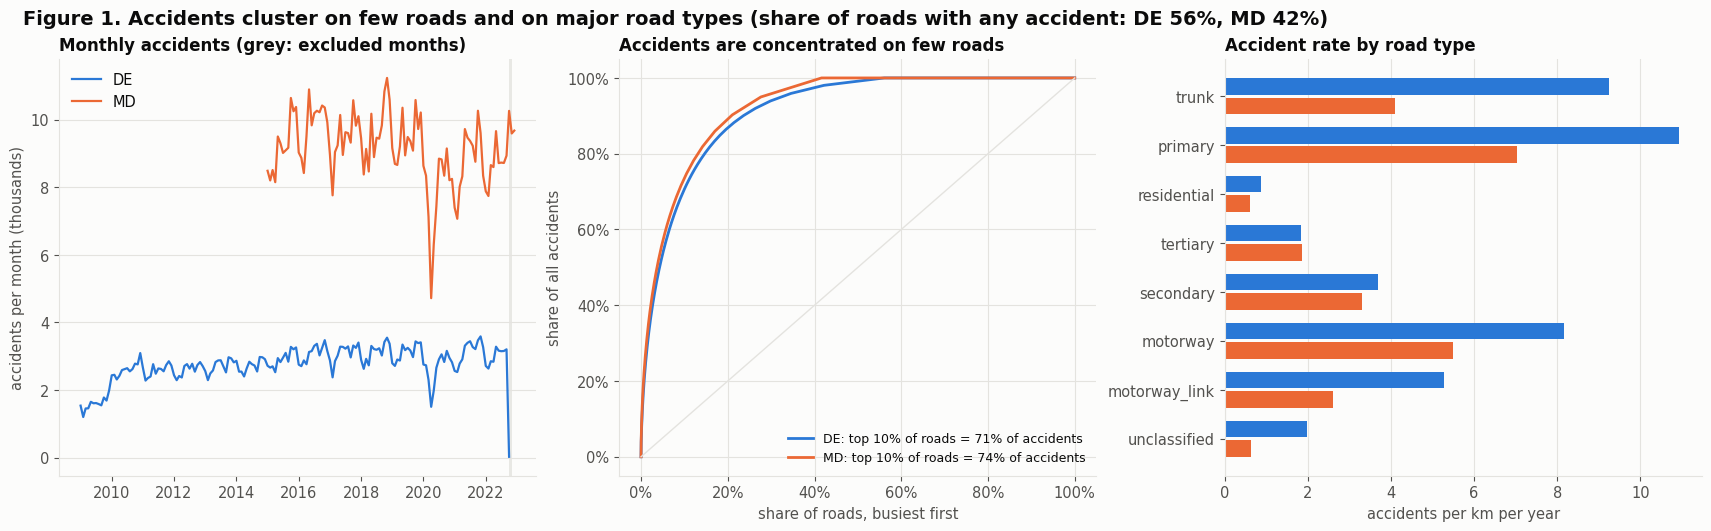

**DE**: top 1% of roads carry 24.0% of accidents, top 10% carry 70.6%; 55.9% of physical roads have any accident in 2009-01 to 2022-09.

**MD**: top 1% of roads carry 26.8% of accidents, top 10% carry 73.6%; 41.5% of physical roads have any accident in 2015-01 to 2022-12.

In [14]:
def dataset_overview_tables(state, info, tables):
    """Numbers behind the exploration figure for one state (usable window only)."""
    first, last = USABLE_MONTHS.get(state, (tables["monthly"].index.min().strftime("%Y-%m"), tables["monthly"].index.max().strftime("%Y-%m")))
    totals, years = accident_totals_in_period(info, tables["roads"], first, last)
    physical = physical_roads_basic(tables["roads"], tables["highway_class"], totals)
    x, y = concentration_curve(physical["accidents"].to_numpy())
    share_top10 = float(np.interp(0.10, x, y))
    share_top1 = float(np.interp(0.01, x, y))
    by_type = physical.groupby("road_type").agg(roads=("accidents", "size"), km=("length_m", lambda s: s.sum() / 1000), accidents=("accidents", "sum"))
    by_type["km_share"] = by_type["km"] / by_type["km"].sum()
    by_type["accident_share"] = by_type["accidents"] / by_type["accidents"].sum()
    by_type["rate_per_km_year"] = by_type["accidents"] / (by_type["km"] * years)
    return {"first": first, "last": last, "years": years, "physical": physical, "curve": (x, y), "share_top10": share_top10,
            "share_top1": share_top1, "share_with_accident": float((physical["accidents"] > 0).mean()), "by_type": by_type.sort_values("accidents", ascending=False)}


def plot_dataset_overview(overview, tables_by_state):
    """Figure 1: monthly series, concentration of accidents, and rate by road type."""
    apply_chart_style()
    states = list(overview)
    fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), layout="constrained")
    ax_time, ax_conc, ax_type = axes
    for state in states:
        monthly = tables_by_state[state]["monthly"]
        ax_time.plot(monthly.index, monthly.to_numpy() / 1000, color=STATE_COLORS[state], lw=1.6, label=state)
        first, last = (pd.Timestamp(m + "-01") for m in (overview[state]["first"], overview[state]["last"]))
        for gap in (monthly.index[monthly.index < first], monthly.index[monthly.index > last]):
            if len(gap):
                ax_time.axvspan(gap.min(), gap.max() + pd.offsets.MonthEnd(0), color=GRID_COLOR, alpha=0.8, lw=0)
    ax_time.set_ylabel("accidents per month (thousands)")
    ax_time.set_title("Monthly accidents (grey: excluded months)")
    ax_time.legend(loc="upper left")
    ax_time.yaxis.grid(True)

    for state in states:
        x, y = overview[state]["curve"]
        ax_conc.plot(x, y, color=STATE_COLORS[state], lw=2, label=f"{state}: top 10% of roads = {overview[state]['share_top10']:.0%} of accidents")
    ax_conc.plot([0, 1], [0, 1], color=GRID_COLOR, lw=1)
    ax_conc.set_xlabel("share of roads, busiest first")
    ax_conc.set_ylabel("share of all accidents")
    ax_conc.set_title("Accidents are concentrated on few roads")
    ax_conc.legend(loc="lower right", fontsize=9)
    ax_conc.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax_conc.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax_conc.grid(True)

    rate = pd.DataFrame({s: overview[s]["by_type"]["rate_per_km_year"] for s in states})
    keep = overview[states[0]]["by_type"]["accidents"].index[:8]
    rate = rate.reindex([t for t in keep if t in rate.index])
    positions = np.arange(len(rate))
    for offset, state in zip((-0.2, 0.2), states):
        ax_type.barh(positions + offset, rate[state].fillna(0).to_numpy(), height=0.34, color=STATE_COLORS[state], label=state)
    ax_type.set_yticks(positions); ax_type.set_yticklabels(rate.index); ax_type.invert_yaxis()
    ax_type.set_xlabel("accidents per km per year")
    ax_type.set_title("Accident rate by road type")
    ax_type.xaxis.grid(True)
    any_accident = ", ".join("{} {:.0%}".format(s, overview[s]["share_with_accident"]) for s in states)
    fig.suptitle("Figure 1. Accidents cluster on few roads and on major road types (share of roads with any accident: " + any_accident + ")",
                 x=0.01, ha="left")
    save_figure(fig, "fig1_dataset_overview")
    plt.show()


overview = {state: dataset_overview_tables(state, data[state], dataset_tables[state]) for state in STATES}
plot_dataset_overview(overview, dataset_tables)
for state in STATES:
    md(f"**{state}**: top 1% of roads carry {pct(overview[state]['share_top1'])} of accidents, top 10% carry {pct(overview[state]['share_top10'])}; "
       f"{pct(overview[state]['share_with_accident'])} of physical roads have any accident in {overview[state]['first']} to {overview[state]['last']}.")

## 5. Matching dataset nodes and roads to OpenStreetMap

> **What.** Two steps. **Nodes:** the dataset stores each intersection's raw OSM id, so we try that first and accept it only if the two positions agree
> within `NODE_ID_COORD_TOL_M`; otherwise we take the nearest OSM node within `NODE_SNAP_MAX_M`. **Roads:** a dataset road keeps the first of three tiers that works:
> *exact* (an OSM road runs between the two matched end nodes in the same direction; for parallel roads the closest in length wins), *reverse* (only the opposite direction exists),
> *nearest* (the OSM road nearest the road's midpoint, if within `ROAD_NEAREST_MAX_M` **and** its length is within `ROAD_LEN_RATIO_RANGE` times the dataset length). Everything else is *unmatched*; the row is kept with empty OSM columns.
>
> **Why.** OSM tags belong to OSM roads. The benchmark was built from an older OSM extract, so some ids are gone and some roads were redrawn; the tiers recover as many as can be trusted without guessing.
> The length-ratio condition on the nearest tier stops a short side street from being matched to the long main road beside it.
>
> **Evidence.** Section 8 reports match shares, the recorded-length / OSM-length ratio per tier, how often the dataset's road type agrees with the OSM `highway` tag per tier,
> and how the match rate would change under stricter or looser thresholds.
>
> **Alternatives considered.** Full map-matching of shapes (the dataset has only end points, not geometry, so there is nothing to match shapes with); a looser nearest tier (adds matches but also wrong ones, see the sensitivity table);
> matching directed pairs only, without the reverse tier (loses one-way/two-way recording differences).
>
> **Honest limit.** A match is a best guess. Tier shares tell how many roads matched, not how many matched *correctly*; the road-type agreement in Section 8 is the closest check we have.

In [15]:
def compare_dataset_and_osm_sizes(nodes, roads, osm_nodes, osm_roads):
    """Compare how many nodes and roads the dataset and OpenStreetMap have (ratios near 1 mean similar networks).

    Returns a dict with the four counts and the OSM / dataset ratios.
    """
    sizes = {"dataset_nodes": len(nodes), "osm_nodes": len(osm_nodes), "dataset_roads": len(roads), "osm_roads": len(osm_roads)}
    sizes["node_ratio"] = sizes["osm_nodes"] / sizes["dataset_nodes"]
    sizes["road_ratio"] = sizes["osm_roads"] / sizes["dataset_roads"]
    return sizes


def match_dataset_nodes_to_osm_nodes(nodes, osm_graph, osm_nodes):
    """Find, for every dataset node, the OSM node it corresponds to.

    Takes dataset `nodes`, `osm_graph` (no longer used; may be None) and `osm_nodes`.
    Returns a copy of `nodes` with extra columns:
        id_in_osm: the dataset's node_id exists in OSM.
        id_dist_m: distance between the dataset position and that OSM node (NaN if not in OSM).
        nearest_osm_id, nearest_dist_m: the closest OSM node by position, and how far it is.
        node_match: "id", "snap" (nearest node) or "none".
        osm_id: the matched OSM node id, or -1 when node_match is "none".
    """
    nodes = nodes.copy()

    # Dataset positions in the same metre-based coordinates as the OSM graph.
    points = gpd.GeoSeries(gpd.points_from_xy(nodes.lon, nodes.lat), crs=4326).to_crs(osm_nodes.crs)
    x, y = points.x.to_numpy(), points.y.to_numpy()

    # Nearest OSM node to every dataset node, by position, and the distance to it in metres.
    nearest_id, nearest_dist = nearest_osm_node(osm_nodes, x, y)
    nodes["nearest_osm_id"] = nearest_id
    nodes["nearest_dist_m"] = nearest_dist

    # Does the dataset's own OSM id exist in the OSM file?
    nodes["id_in_osm"] = nodes["node_id"].isin(osm_nodes.index)

    # For those, how far apart are the dataset position and the OSM node with that id? (NaN for ids not in OSM)
    osm_x = osm_nodes.geometry.x.reindex(nodes["node_id"]).to_numpy()
    osm_y = osm_nodes.geometry.y.reindex(nodes["node_id"]).to_numpy()
    nodes["id_dist_m"] = np.hypot(x - osm_x, y - osm_y)

    # Decision: trust the id if the positions agree, else the nearest node if it is close enough.
    id_ok = nodes["id_in_osm"] & (nodes["id_dist_m"] <= NODE_ID_COORD_TOL_M)
    snap_ok = ~id_ok & (nodes["nearest_dist_m"] <= NODE_SNAP_MAX_M)
    nodes["node_match"] = np.select([id_ok, snap_ok], ["id", "snap"], "none")
    nodes["osm_id"] = np.where(id_ok, nodes["node_id"], np.where(snap_ok, nodes["nearest_osm_id"], -1))
    return nodes


def match_dataset_roads_to_osm_roads(nodes, roads, osm_graph, osm_roads):
    """Find, for every dataset road, the OSM road it corresponds to (tiers: exact, reverse, nearest, unmatched).

    Takes `nodes` (with `osm_id` from `match_dataset_nodes_to_osm_nodes`), dataset `roads`, and `osm_roads`.
    Returns a copy of `roads` (same row order) with extra columns:
        osm_u, osm_v: OSM ids of the road's start and end nodes (-1 if the node had no match).
        match_type: "exact", "reverse", "nearest" or "unmatched".
        match_dist_m: 0 for exact and reverse; distance to the OSM road for nearest.
        osm_row: position of the matched road in `osm_roads` (-1 if unmatched). Use it to copy tags.
        osm_length_m: the matched OSM road's length.   len_ratio: osm_length_m / the dataset's length_m.
        osm_highway: the matched OSM road's own `highway` tag (for checking the match; NaN if unmatched).
        cand_dist_m, cand_len_ratio: for roads that reached the nearest tier, the distance and length ratio of the
            nearest candidate even when it was REJECTED. Lets us ask how many more roads a looser threshold would match.
    """
    roads = roads.copy()
    assert (roads.index == np.arange(len(roads))).all(), "roads must keep a default 0..N-1 index"
    n_roads = len(roads)

    # OSM ids of each road's two end nodes (-1 where the node was not matched).
    osm_id = nodes["osm_id"].to_numpy()
    roads["osm_u"] = osm_id[roads["node_1_idx"].to_numpy()]
    roads["osm_v"] = osm_id[roads["node_2_idx"].to_numpy()]

    # The OSM roads as a flat table, remembering each road's position in `osm_roads`.
    osm_table = pd.DataFrame({
        "u": osm_roads.index.get_level_values("u"),
        "v": osm_roads.index.get_level_values("v"),
        "osm_length_m": osm_roads["length"].to_numpy(),
        "osm_row": np.arange(len(osm_roads)),
    })

    # Results, one entry per dataset road.
    match_type = np.full(n_roads, "unmatched", dtype=object)
    osm_row = np.full(n_roads, -1)
    osm_length = np.full(n_roads, np.nan)
    match_dist = np.full(n_roads, np.nan)
    cand_dist = np.full(n_roads, np.nan)
    cand_ratio = np.full(n_roads, np.nan)

    def match_by_node_pair(todo, start_col, end_col):
        """OSM roads running from `start_col` to `end_col`; for parallel roads keep the closest length."""
        pairs = todo[[start_col, end_col, "length_m"]].reset_index(names="road")
        candidates = pairs.merge(osm_table, left_on=[start_col, end_col], right_on=["u", "v"])
        candidates["length_error"] = (candidates["osm_length_m"] - candidates["length_m"]).abs()
        best = candidates.sort_values("length_error").drop_duplicates("road")
        return best["road"].to_numpy(), best["osm_row"].to_numpy(), best["osm_length_m"].to_numpy()

    # Tier 1, exact: same direction as the dataset road.
    rows, found, lengths = match_by_node_pair(roads, "osm_u", "osm_v")
    match_type[rows], osm_row[rows], osm_length[rows], match_dist[rows] = "exact", found, lengths, 0.0

    # Tier 2, reverse: only for roads not yet matched; look for the OSM road running the other way.
    todo = roads[match_type == "unmatched"]
    rows, found, lengths = match_by_node_pair(todo, "osm_v", "osm_u")
    match_type[rows], osm_row[rows], osm_length[rows], match_dist[rows] = "reverse", found, lengths, 0.0

    # Tier 3, nearest: use the road's midpoint, in the same metre coordinates as the OSM graph.
    points = gpd.GeoSeries(gpd.points_from_xy(nodes.lon, nodes.lat), crs=4326).to_crs(osm_roads.crs)
    x, y = points.x.to_numpy(), points.y.to_numpy()
    start, end = roads["node_1_idx"].to_numpy(), roads["node_2_idx"].to_numpy()
    mid_x, mid_y = (x[start] + x[end]) / 2, (y[start] + y[end]) / 2

    left = np.flatnonzero(match_type == "unmatched")
    found, nearest_dist = nearest_osm_road(osm_roads, mid_x[left], mid_y[left])  # position of the closest road in osm_roads
    found_length = osm_roads["length"].to_numpy()[found]
    ratio = found_length / roads["length_m"].to_numpy()[left]
    cand_dist[left], cand_ratio[left] = nearest_dist, ratio                       # kept even for rejected candidates
    accept = (found >= 0) & (nearest_dist <= ROAD_NEAREST_MAX_M) & \
             (ratio >= ROAD_LEN_RATIO_RANGE[0]) & (ratio <= ROAD_LEN_RATIO_RANGE[1])
    rows = left[accept]
    match_type[rows], osm_row[rows] = "nearest", found[accept]
    osm_length[rows], match_dist[rows] = found_length[accept], nearest_dist[accept]

    roads["match_type"] = match_type
    roads["match_dist_m"] = match_dist
    roads["osm_row"] = osm_row
    roads["osm_length_m"] = osm_length
    roads["len_ratio"] = osm_length / np.where(roads["length_m"] > 0, roads["length_m"], np.nan)
    roads["cand_dist_m"] = cand_dist
    roads["cand_len_ratio"] = cand_ratio

    osm_highway = road_tag_values(osm_roads, "highway").map(first_text).to_numpy(dtype=object)
    roads["osm_highway"] = np.where(osm_row >= 0, osm_highway[np.maximum(osm_row, 0)], None)
    return roads


def matching_diagnostics(nodes, roads, sizes):
    """Everything worth keeping about the matching, as plain numbers (saved in the metadata so it survives reloading)."""
    def quantiles(series):
        q = series.dropna().quantile([0.05, 0.5, 0.95])
        return {"p05": float(q.iloc[0]), "p50": float(q.iloc[1]), "p95": float(q.iloc[2])} if len(series.dropna()) else {}

    by_tier = {}
    for tier, group in roads.groupby("match_type"):
        entry = {"roads": int(len(group))}
        if tier != "unmatched":
            entry.update({"len_ratio": quantiles(group["len_ratio"]),
                          "share_ratio_0.8_1.25": float(group["len_ratio"].between(0.8, 1.25).mean())})
        by_tier[tier] = entry
    return {
        "osm_sizes": {k: (float(v) if isinstance(v, float) else int(v)) for k, v in sizes.items()},
        "node_match_share": nodes["node_match"].value_counts(normalize=True).round(4).to_dict(),
        "dataset_node_id_found_in_osm": float(nodes["id_in_osm"].mean()),
        "id_found_but_position_differs": int((nodes["id_in_osm"] & (nodes["node_match"] != "id")).sum()),
        "nearest_node_distance_m": quantiles(nodes["nearest_dist_m"]),
        "road_match_share": roads["match_type"].value_counts(normalize=True).round(4).to_dict(),
        "road_match_by_tier": by_tier,
    }

## 6. Building the road features (groups g1 to g5)
Each feature group below has the same four-part note. All raw values are saved **unscaled and with missing kept as missing**.

| Group | Columns | What it measures | Needs a matched OSM road? |
|---|---|---|---|
| **g1** road character | maxspeed_mph, lanes, surface, bridge, tunnel | what kind of road it is, from the OSM road's own tags | yes |
| **g2** intersection control | signal / stop / give_way / crossing at each end, roundabout, 5 mid-block counts | what controls traffic at the ends and along the road | yes |
| **g3** cycle, pedestrian, lighting | cycleway, sidewalk, lit | infrastructure tags (three states: yes / no / not tagged) | yes |
| **g4** nearby places | 7 kinds x (counts within 100, 250, 500, 1000 m + distance to nearest) | what surrounds the road: schools, bars, food, parking, bus stops, crossings, signals | no, position only |
| **g5** road shape | sinuosity (curviness) | how much longer the road is than the straight line between its ends | no |

> **g1. What:** parse the OSM road's `maxspeed`, `lanes`, `surface`, `bridge`, `tunnel` once per OSM road and copy to matched dataset roads. **Why:** these describe the road and are not in the dataset.
> **Evidence:** parser self-test (Section 2); fill rates in Section 9. **Alternative:** keeping raw strings (unusable by a model).
>
> **g2. What:** read the signal/stop/give-way/crossing tags at the OSM road's start and end nodes. **Why:** crashes cluster at intersections.
> **Problem found:** osmnx's simplification deletes nodes that are not junctions, and with them their tags, so a signal or crossing in the middle of a block disappears.
> **Fix:** read every tagged point from the XML, and count those that simplification removed on the road they lie on (nearest road within `MIDBLOCK_NODE_MAX_M`).
> **Evidence:** the recovery table in Section 8 shows how many tagged points of each kind were lost and how many were recovered. **Alternative:** `simplify=False` (keeps every node, but multiplies the graph size and breaks the road-to-road correspondence with the dataset).
>
> **g3. What:** each feature has three states: 1 yes, 0 tagged "no", NaN not tagged. **Why:** the plan expects these tags to be rare on a drive network; we measure how rare.
> **Limit:** only the plain `sidewalk` tag was requested, not `sidewalk:left/right`.
>
> **g4. What:** the road's midpoint is the reference; count places inside four radii and find the nearest. **Why:** places mean pedestrians, turning traffic and parking near the road, and every road gets a value.
> **Alternative:** road-to-place network distance (more faithful, far slower).
>
> **g5. What:** curviness: road length divided by the straight-line distance between its ends, from the dataset's own coordinates (no OSM tags). **Why:** bends reduce sight lines, the benchmark does not carry it, and every road gets a value.
> **Left out on purpose:** node degree, neighbour counts, dead ends, road length, orientation and the best road type at the ends. The benchmark's baseline already carries degree, length and road type (and a graph model sees the rest through the network), so they would not be new information from OpenStreetMap.

In [16]:
from shapely.geometry import shape

TAGGED_NODE_KINDS = ["signal", "stop", "give_way", "crossing", "traffic_calming"]


# Which place type each OSM tag value belongs to.
PLACE_TYPE_OF_TAG = {"school": "school", "bar": "bar_pub", "pub": "bar_pub", "restaurant": "food",
                     "fast_food": "food", "parking": "parking", "bus_stop": "bus_stop"}



def build_g1_road_character(roads, osm_roads):
    """g1 features: what kind of road it is, from the OSM road's own tags.

    Why: speed limit, lanes and surface describe the road and are not in the dataset
    (the dataset only has road type, one-way and length).

    How: each tag is parsed once per OSM road, then copied to the dataset roads through `osm_row`.
    Matched roads get the value (NaN if the tag is missing in OSM); unmatched roads get NaN.

    Takes: `roads` (after matching) and `osm_roads`.

    Returns: a DataFrame with the same rows as `roads` and these columns:
        g1_maxspeed_mph: speed limit in mph (highest if OSM lists several).
        g1_lanes: number of lanes (highest if OSM lists several).
        g1_surface: surface type; categories with fewer than RARE_CATEGORY_MIN_ROADS roads become "other".
        g1_bridge, g1_tunnel: 1 if the road is on a bridge / in a tunnel, 0 otherwise.
    """
    matched = (roads["osm_row"] >= 0).to_numpy()
    safe_rows = np.where(matched, roads["osm_row"].to_numpy(), 0)  # row 0 stands in for unmatched roads

    def copy_to_dataset_roads(osm_values):
        return np.where(matched, np.asarray(osm_values, dtype=object)[safe_rows], np.nan)

    features = pd.DataFrame(index=roads.index)
    features["g1_maxspeed_mph"] = copy_to_dataset_roads(road_tag_values(osm_roads, "maxspeed").map(parse_maxspeed_mph))
    features["g1_lanes"] = copy_to_dataset_roads(road_tag_values(osm_roads, "lanes").map(parse_lanes))
    features["g1_surface"] = copy_to_dataset_roads(road_tag_values(osm_roads, "surface").map(first_text))
    features["g1_bridge"] = copy_to_dataset_roads(road_tag_values(osm_roads, "bridge").map(tag_is_set))
    features["g1_tunnel"] = copy_to_dataset_roads(road_tag_values(osm_roads, "tunnel").map(tag_is_set))
    numeric = ["g1_maxspeed_mph", "g1_lanes", "g1_bridge", "g1_tunnel"]
    features[numeric] = features[numeric].astype(float)

    # Fold rare surface types into "other" (keeping missing values as missing).
    counts = features["g1_surface"].value_counts()
    rare = counts[counts < RARE_CATEGORY_MIN_ROADS].index
    features["g1_surface"] = features["g1_surface"].where(~features["g1_surface"].isin(rare), "other")
    return features



def build_g2_intersection_control(nodes, roads, osm_roads, osm_nodes, osm_graph):
    """g2 features: what controls traffic at each end of the road, and how busy the junctions are.

    Why: crashes cluster at intersections, and signals, stop signs and crossings change the risk there.

    How: for every matched road we find the OSM road's two end nodes, work out which one is the
    dataset road's start (the one closer to the dataset start node), and read the node tags there.
    Matched roads get 1 or 0 (tag present or not); unmatched roads get NaN.

    Takes: `nodes`, `roads` (after matching), and `osm_roads`, `osm_nodes`, `osm_graph`.

    Returns: a DataFrame with the same rows as `roads` and these columns:
        g2_{signal,stop,give_way,crossing}_{start,end}: 1 if that node carries the tag.
        g2_roundabout: 1 if the OSM road is part of a roundabout.

    Limitation: osmnx's simplification removes nodes that are not intersections or dead ends, and
    with them their tags. A signal or crossing in the middle of a block is therefore missing here;
    only tags on intersection and dead-end nodes are seen.
    """
    matched = (roads["osm_row"] >= 0).to_numpy()
    safe_rows = np.where(matched, roads["osm_row"].to_numpy(), 0)  # row 0 stands in for unmatched roads

    # The two OSM nodes at the ends of each matched OSM road (-1 where unmatched).
    osm_u = osm_roads.index.get_level_values("u").to_numpy()[safe_rows]
    osm_v = osm_roads.index.get_level_values("v").to_numpy()[safe_rows]
    osm_u, osm_v = np.where(matched, osm_u, -1), np.where(matched, osm_v, -1)

    # Which OSM end is the dataset road's start? The one nearer to the dataset start node.
    points = gpd.GeoSeries(gpd.points_from_xy(nodes.lon, nodes.lat), crs=4326).to_crs(osm_nodes.crs)
    x, y = points.x.to_numpy(), points.y.to_numpy()
    start_node = roads["node_1_idx"].to_numpy()
    osm_x, osm_y = osm_nodes.geometry.x, osm_nodes.geometry.y
    dist_to_u = np.hypot(x[start_node] - osm_x.reindex(osm_u).to_numpy(), y[start_node] - osm_y.reindex(osm_u).to_numpy())
    dist_to_v = np.hypot(x[start_node] - osm_x.reindex(osm_v).to_numpy(), y[start_node] - osm_y.reindex(osm_v).to_numpy())
    u_is_start = dist_to_u <= dist_to_v
    start_osm = np.where(u_is_start, osm_u, osm_v)
    end_osm = np.where(u_is_start, osm_v, osm_u)

    # Node tags. OSM stores the kind of control in the node's `highway` tag.
    node_highway = node_tag_values(osm_nodes, "highway").map(as_text_list)
    node_flags = {
        "signal": node_highway.map(lambda items: "traffic_signals" in items),
        "stop": node_highway.map(lambda items: "stop" in items),
        "give_way": node_highway.map(lambda items: "give_way" in items),
        "crossing": node_highway.map(lambda items: "crossing" in items) | node_tag_values(osm_nodes, "crossing").notna(),
    }

    features = pd.DataFrame(index=roads.index)
    for name, flag in node_flags.items():
        for end, ids in (("start", start_osm), ("end", end_osm)):
            value = flag.astype(float).reindex(ids).to_numpy()  # NaN for id -1
            features[f"g2_{name}_{end}"] = np.where(matched, value, np.nan)

    # Roundabout: a property of the OSM road, parsed once per OSM road then copied across.
    on_roundabout = road_tag_values(osm_roads, "junction").map(
        lambda v: float(any(item in ("roundabout", "circular") for item in as_text_list(v)))).to_numpy()
    features["g2_roundabout"] = np.where(matched, on_roundabout[safe_rows], np.nan)
    return features


def read_tagged_nodes_from_xml(xml_path):
    """List every point in the OSM XML file that carries a traffic-control tag.

    Why: the simplified osmnx network lost most signals, stops and crossings that sit mid-block.
    The XML file still has them, so we read them from there.

    Takes: path to the road XML (e.g. /content/data/DE_roads.osm).
    Returns: a DataFrame with one row per tagged point: osm_id, lat, lon, and one True/False column
    per kind in TAGGED_NODE_KINDS (signal = traffic_signals, stop, give_way, crossing, traffic_calming).
    """
    import xml.etree.ElementTree as ET

    rows = []
    for _, element in ET.iterparse(xml_path, events=("end",)):
        if element.tag == "node":
            tags = {tag.get("k"): tag.get("v") for tag in element.findall("tag")}
            highway = tags.get("highway")
            kinds = {
                "signal": highway == "traffic_signals",
                "stop": highway == "stop",
                "give_way": highway == "give_way",
                "crossing": highway == "crossing" or "crossing" in tags,
                "traffic_calming": "traffic_calming" in tags,
            }
            if any(kinds.values()):
                rows.append({"osm_id": int(element.get("id")), "lat": float(element.get("lat")),
                             "lon": float(element.get("lon")), **kinds})
        if element.tag in ("node", "way"):
            element.clear()  # free memory; the file is large

    tagged_nodes = pd.DataFrame(rows)
    print(f"tagged points in the file: {len(tagged_nodes):,}")
    print(tagged_nodes[TAGGED_NODE_KINDS].sum().to_string())
    return tagged_nodes


def count_lost_tagged_nodes_per_road(tagged_nodes, osm_graph, osm_nodes, osm_roads):
    """For tagged points that simplification removed, count how many sit on each OSM road.

    Why: a removed point lay in the middle of one road, so it belongs to that road.
    Points that survived (at intersections) are already covered by the start/end flags, so skip them.

    How: find the nearest OSM road to each removed point; keep it if within MIDBLOCK_NODE_MAX_M.
    The two directions of a two-way road share a count, so roads are keyed by their (smaller, larger) node ids.

    Takes: `tagged_nodes` from `read_tagged_nodes_from_xml`, `osm_graph`, `osm_nodes`, `osm_roads`.
    Returns: a table indexed by (road_u, road_v) with one count column per kind.
    Prints how many points were removed, how many were attached, and how far they were from a road.
    """
    lost = tagged_nodes[~tagged_nodes["osm_id"].isin(osm_nodes.index)].copy()

    # Nearest OSM road to each removed point, in metre coordinates.
    points = gpd.GeoSeries(gpd.points_from_xy(lost.lon, lost.lat), crs=4326).to_crs(osm_roads.crs)
    position, distance = nearest_osm_road(osm_roads, points.x.to_numpy(), points.y.to_numpy())
    start = osm_roads.index.get_level_values("u").to_numpy()[position]
    end = osm_roads.index.get_level_values("v").to_numpy()[position]
    lost["road_u"], lost["road_v"] = np.minimum(start, end), np.maximum(start, end)
    lost["distance_m"] = distance

    near = lost[lost["distance_m"] <= MIDBLOCK_NODE_MAX_M]
    print(f"tagged points removed by simplification: {len(lost):,}")
    print(f"attached to a road within {MIDBLOCK_NODE_MAX_M} m: {len(near):,}")
    print("distance to the nearest road (m):")
    print(lost["distance_m"].describe(percentiles=[.5, .9, .99]).round(2).to_string())
    print("\nattached, by kind:")
    print(near[TAGGED_NODE_KINDS].sum().to_string())
    return near.groupby(["road_u", "road_v"])[TAGGED_NODE_KINDS].sum()


def build_g2_midblock_counts(roads, osm_roads, midblock_counts):
    """g2 features: how many signals / stops / give-way signs / crossings / traffic-calming points lie mid-block.

    Takes: `roads` (after matching), `osm_roads`, and the table from `count_lost_tagged_nodes_per_road`.
    Returns: a DataFrame with the same rows as `roads` and columns g2_{kind}_midblock (a count; 0 if none,
    NaN for unmatched roads). Both directions of a two-way road get the same count.
    """
    matched = (roads["osm_row"] >= 0).to_numpy()
    safe_rows = np.where(matched, roads["osm_row"].to_numpy(), 0)  # row 0 stands in for unmatched roads

    # The matched OSM road's (smaller, larger) end-node ids, which is the key used in midblock_counts.
    osm_u = osm_roads.index.get_level_values("u").to_numpy()[safe_rows]
    osm_v = osm_roads.index.get_level_values("v").to_numpy()[safe_rows]
    keys = pd.MultiIndex.from_arrays([np.minimum(osm_u, osm_v), np.maximum(osm_u, osm_v)])

    features = pd.DataFrame(index=roads.index)
    for kind in TAGGED_NODE_KINDS:
        counts = midblock_counts[kind].reindex(keys).fillna(0).to_numpy()
        features[f"g2_{kind}_midblock"] = np.where(matched, counts, np.nan)
    return features



def build_g3_road_user_infrastructure(roads, osm_roads):
    """g3 features: infrastructure for cyclists and pedestrians, and street lighting.

    Why: the brief expects these tags to be rare on a drive network; we measure how rare.

    How: like g1, each OSM road is parsed once and the result copied to the dataset roads through
    `osm_row`. Each feature has three states: 1 = tagged and present, 0 = tagged "no",
    NaN = not tagged at all (or the road was unmatched). So the fill rate is the share that is not NaN.

    Takes: `roads` (after matching) and `osm_roads`.

    Returns: a DataFrame with the same rows as `roads` and these columns:
        g3_cycleway_any: any of cycleway, cycleway:left, cycleway:right, cycleway:both says yes.
        g3_sidewalk_any: the `sidewalk` tag says yes (includes "separate", a sidewalk mapped as its own way).
        g3_lit: the `lit` tag says yes.

    Limitation: only the plain `sidewalk` tag was requested from OSM, not sidewalk:left / sidewalk:right.
    """
    matched = (roads["osm_row"] >= 0).to_numpy()
    safe_rows = np.where(matched, roads["osm_row"].to_numpy(), 0)  # row 0 stands in for unmatched roads

    def copy_to_dataset_roads(osm_values):
        return np.where(matched, np.asarray(osm_values, dtype=float)[safe_rows], np.nan)

    def tag_lists(name):
        return road_tag_values(osm_roads, name).map(as_text_list)

    # Cycleway can be tagged under four keys; pool the values of all four for each OSM road.
    cycleway_keys = ["cycleway", "cycleway:left", "cycleway:right", "cycleway:both"]
    pooled = [sum(values, []) for values in zip(*[tag_lists(key) for key in cycleway_keys])]

    features = pd.DataFrame(index=roads.index)
    features["g3_cycleway_any"] = copy_to_dataset_roads([yes_no_or_untagged(items) for items in pooled])
    features["g3_sidewalk_any"] = copy_to_dataset_roads(tag_lists("sidewalk").map(yes_no_or_untagged))
    features["g3_lit"] = copy_to_dataset_roads(tag_lists("lit").map(yes_no_or_untagged))
    return features



def build_g5_curviness(nodes, roads):
    """g5 feature: how curvy each road is. No OSM tags are needed.

    Why: bends reduce sight lines, the benchmark does not carry this, and every road gets a value (unlike most OSM tags).

    Takes: `nodes` and `roads` (from `load_dataset_node_and_road_tables`).

    Returns: a DataFrame with the same rows as `roads` and one column:
        g5_sinuosity: recorded road length / straight-line distance between its ends (1 = straight; NaN if the ends coincide).
    """
    start, end = roads["node_1_idx"].to_numpy(), roads["node_2_idx"].to_numpy()
    lat, lon = nodes["lat"].to_numpy(), nodes["lon"].to_numpy()
    straight = straight_line_distance_m(lat[start], lon[start], lat[end], lon[end])
    features = pd.DataFrame(index=roads.index)
    features["g5_sinuosity"] = roads["length_m"].to_numpy() / np.where(straight > 0, straight, np.nan)
    return features


def read_osm_places(state, data_dir, local_dir):
    """Read the schools, bars, restaurants, bus stops and parking from `{state}_osm_places.zip`.

    Why: these are the raw material for the g4 "surroundings" features.

    Takes: state code, the Drive data folder, the Colab local folder.
    Returns: a DataFrame with one row per place: lat, lon, and place_type (school, bar_pub, food, parking, bus_stop).
    Areas (a school outline, a parking lot) are reduced to their centre. Prints how many of each type.
    """
    geojson = local_dir / f"{state}_places.geojsonseq"
    if not geojson.exists():
        with zipfile.ZipFile(data_dir / f"{state}_osm_places.zip") as archive:
            archive.extractall(local_dir)

    rows = []
    with open(geojson) as file:
        for line in file:
            line = line.strip().lstrip("\x1e")  # GeoJSON sequences may start each record with a separator character
            if not line:
                continue
            feature = json.loads(line)
            tags = feature.get("properties", {})
            place_type = PLACE_TYPE_OF_TAG.get(tags.get("amenity")) or PLACE_TYPE_OF_TAG.get(tags.get("highway"))
            if place_type is None or feature.get("geometry") is None:
                continue
            centre = shape(feature["geometry"]).centroid
            rows.append({"lat": centre.y, "lon": centre.x, "place_type": place_type})

    places = pd.DataFrame(rows)
    print(f"places read: {len(places):,}")
    print(places["place_type"].value_counts().to_string())
    return places


def build_g4_nearby_places(places, tagged_nodes, nodes, roads, metric_crs):
    """g4 features: how many places of each type are near a road, and how far the nearest is.

    Why: schools, bars, bus stops and so on mean pedestrians, traffic and turning cars near the road.
    These need no road tags, and every road gets a value (also unmatched ones), because they use only
    the road's position.

    How: each road is represented by the midpoint of its two end nodes. For each place type we count the
    places within PLACE_RADII_M of that midpoint, and find the distance to the nearest one.
    Crossings and traffic signals come from `tagged_nodes` (the full list, including the ones simplification removed).

    Takes: `places` from `read_osm_places`, `tagged_nodes` from `read_tagged_nodes_from_xml`, `nodes`, `roads`,
    and `metric_crs` (the metre-based coordinate system of the OSM graph, e.g. osm_roads.crs).

    Returns: a DataFrame with the same rows as `roads` and these columns for each place type
    (school, bar_pub, food, parking, bus_stop, crossing, signal):
        g4_{type}_{100,250,500,1000}m: how many within each distance in PLACE_RADII_M.
        g4_{type}_nearest_m: distance to the nearest one in metres (NaN if there are none at all).
    """
    def to_metres(lon, lat):
        points = gpd.GeoSeries(gpd.points_from_xy(lon, lat), crs=4326).to_crs(metric_crs)
        return np.column_stack([points.x.to_numpy(), points.y.to_numpy()])

    # Road midpoints, in metres.
    start, end = roads["node_1_idx"].to_numpy(), roads["node_2_idx"].to_numpy()
    node_xy = to_metres(nodes["lon"].to_numpy(), nodes["lat"].to_numpy())
    midpoints = (node_xy[start] + node_xy[end]) / 2

    # Locations of each kind of place.
    locations = {kind: places.loc[places["place_type"] == kind, ["lon", "lat"]] for kind in places["place_type"].unique()}
    locations["crossing"] = tagged_nodes.loc[tagged_nodes["crossing"], ["lon", "lat"]]
    locations["signal"] = tagged_nodes.loc[tagged_nodes["signal"], ["lon", "lat"]]

    features = pd.DataFrame(index=roads.index)
    for kind, lonlat in locations.items():
        if len(lonlat) == 0:
            continue
        tree = cKDTree(to_metres(lonlat["lon"].to_numpy(), lonlat["lat"].to_numpy()))
        for radius in PLACE_RADII_M:
            features[f"g4_{kind}_{radius}m"] = tree.query_ball_point(midpoints, r=radius, return_length=True)
        features[f"g4_{kind}_nearest_m"] = tree.query(midpoints)[0]
    return features



In [17]:
def midblock_recovery_stats(tagged_nodes, osm_nodes, midblock_counts):
    """How many traffic-control points the simplified OSM network lost, and how many we recovered onto roads.

    Takes the full list of tagged points (`read_tagged_nodes_from_xml`), the OSM node table and the mid-block counts.
    Returns a table with one row per kind: tagged points in the file, still present as nodes (end flags see them),
    removed by simplification, and attached to a road within MIDBLOCK_NODE_MAX_M (summed counts).
    """
    kept = tagged_nodes["osm_id"].isin(osm_nodes.index)
    table = pd.DataFrame({
        "in_file": tagged_nodes[TAGGED_NODE_KINDS].sum(),
        "kept_as_nodes": tagged_nodes.loc[kept, TAGGED_NODE_KINDS].sum(),
        "removed_by_simplification": tagged_nodes.loc[~kept, TAGGED_NODE_KINDS].sum(),
        "recovered_mid_block": midblock_counts[TAGGED_NODE_KINDS].sum(),
    })
    table["share_removed"] = table["removed_by_simplification"] / table["in_file"].replace(0, np.nan)
    table["share_of_removed_recovered"] = table["recovered_mid_block"] / table["removed_by_simplification"].replace(0, np.nan)
    return table

## 7. Run the pipeline: build or load the features for each state
`get_state_features` loads the saved feature table if it exists, otherwise builds it (slow) and saves it.
Along with the 58 raw feature columns, the saved file now carries a few **diagnostic columns** (the OSM road's own `highway` tag, and the distance and length ratio of
*rejected* nearest-road candidates) and the metadata carries the matching and recovery diagnostics, so Sections 8 and 9 work from a saved file alone.
A file saved by the older notebook lacks them: those checks are then skipped with a notice, and `FORCE_REBUILD = True` upgrades the file.

In [18]:
# Columns copied from `roads` to identify each road and say how well it was matched.
ROAD_ID_COLUMNS = ["node_1_idx", "node_2_idx", "road_u", "road_v", "has_reverse", "u_lt_v",
                   "length_m", "match_type", "match_dist_m", "len_ratio"]
DIAGNOSTIC_COLUMNS = ["osm_highway", "cand_dist_m", "cand_len_ratio"]   # added in pipeline 2.0; absent from older files
FEATURE_COLUMN_PATTERN = re.compile(r"g\d_")
# Features removed in pipeline 2.1 because the benchmark's baseline already carries the same information (node degree, road length, road type).
# Older saved files may still hold them; they are ignored when a file is loaded, and a rebuild no longer creates them.
RETIRED_FEATURE_PATTERN = re.compile(r"g2_street_count|g5_(log_length|orientation|out_degree|in_degree|neighbors|dead_end|best_rank)")
PIPELINE_VERSION = "2.2"


def configured_thresholds():
    """The thresholds currently set in the config cell, for the metadata."""
    return {"NODE_SNAP_MAX_M": NODE_SNAP_MAX_M, "NODE_ID_COORD_TOL_M": NODE_ID_COORD_TOL_M,
            "ROAD_NEAREST_MAX_M": ROAD_NEAREST_MAX_M, "ROAD_LEN_RATIO_RANGE": ROAD_LEN_RATIO_RANGE,
            "MIDBLOCK_NODE_MAX_M": MIDBLOCK_NODE_MAX_M, "PLACE_RADII_M": PLACE_RADII_M,
            "RARE_CATEGORY_MIN_ROADS": RARE_CATEGORY_MIN_ROADS}


def save_road_features(state, nodes, roads, road_features, data_dir, diagnostics):
    """Save the feature table and a metadata file to the Drive data folder.

    The table has one row per directed road, in the same order as `adj.coalesce().indices()`, with the road identifiers
    in ROAD_ID_COLUMNS and DIAGNOSTIC_COLUMNS, then every feature column (g1_ ... g5_). Values are raw: missing stays NaN,
    nothing is imputed or scaled. The metadata records the OSM snapshot date, versions, thresholds, matching and recovery
    diagnostics, which columns belong to which group, and the fill rate of every column.
    Returns the paths of the parquet file and the metadata file.
    """
    assert len(road_features) == len(roads) and (road_features.index == roads.index).all(), "features not aligned with roads"
    feature_columns = [c for c in road_features.columns if FEATURE_COLUMN_PATTERN.match(c)]
    table = pd.concat([roads[ROAD_ID_COLUMNS + DIAGNOSTIC_COLUMNS].reset_index(drop=True),
                       road_features[feature_columns].reset_index(drop=True)], axis=1)
    assert not table.columns.duplicated().any(), "duplicate column names"

    parquet_path = data_dir / f"{state}_osm_edge_features.parquet"
    table.to_parquet(parquet_path, index=False)

    # OSM snapshot date from the Geofabrik file name (e.g. delaware-261018.osm.pbf -> 2026-10-18).
    pbf = find_state_pbf(state, data_dir)
    date = re.search(r"-(\d{2})(\d{2})(\d{2})\.osm\.pbf$", pbf.name)
    snapshot = f"20{date.group(1)}-{date.group(2)}-{date.group(3)}" if date else None

    metadata = {
        "state": state, "pipeline_version": PIPELINE_VERSION, "rows": len(table),
        "row_order": "same as adj.coalesce().indices() of the dataset",
        "osm_source_file": pbf.name, "osm_snapshot_date": snapshot,
        "environment": ENVIRONMENT, "thresholds": configured_thresholds(),
        "node_match_share": nodes["node_match"].value_counts(normalize=True).round(4).to_dict(),
        "road_match_share": roads["match_type"].value_counts(normalize=True).round(4).to_dict(),
        "diagnostics": diagnostics,
        "groups": {group: [c for c in feature_columns if c.startswith(group + "_")]
                   for group in sorted({c.split("_")[0] for c in feature_columns})},
        "fill_rate": table[feature_columns].notna().mean().round(4).to_dict(),
        "notes": [
            "Values are raw; missing is NaN. Unmatched roads have NaN for every OSM-tag feature (g1, g2, g3) but not for g4 and g5.",
            "OSM is a snapshot from the date above; accident labels span about 2009-2022.",
            "Both directions of a two-way road share the OSM-derived values.",
        ],
    }
    meta_path = data_dir / f"{state}_osm_meta.json"
    with open(meta_path, "w") as file:
        json.dump(metadata, file, indent=2, default=str)
    print(f"saved {len(table):,} rows x {len(feature_columns)} features (plus identifiers and diagnostics) to {parquet_path.name} and {meta_path.name}")
    return parquet_path, meta_path


def build_state_features(state, data, data_dir, local_dir, save=True):
    """Run the whole feature pipeline for one state and save the result.

    Steps: dataset tables -> length check -> OSM tables -> node matching -> road matching -> features g1, g2 (end flags
    and mid-block counts), g3, g4, g5 -> diagnostics -> save. For a large state, build the OSM tables first (Section 3).
    Returns a dict with `nodes`, `roads` (after matching), `road_features`, `highway_class` and `diagnostics`.
    """
    memory_report(f"{state} start")
    info = data[state]

    print(f"\n===== {state}: dataset tables")
    nodes, roads = load_dataset_node_and_road_tables(info)
    check_dataset_road_lengths(nodes, roads)

    print(f"\n===== {state}: OSM tables")
    prepare_osm_roads_zip(state, data_dir, local_dir)
    prepare_osm_places_zip(state, data_dir, local_dir)
    build_osm_tables(state, data_dir, local_dir)  # skipped if the tables are already built
    osm_nodes, osm_roads = load_osm_tables(state, local_dir)
    osm_graph = None  # not kept: lookups use the tables
    sizes = compare_dataset_and_osm_sizes(nodes, roads, osm_nodes, osm_roads)
    print({k: round(v, 3) if isinstance(v, float) else v for k, v in sizes.items()})

    print(f"\n===== {state}: matching")
    nodes = match_dataset_nodes_to_osm_nodes(nodes, osm_graph, osm_nodes)
    roads = match_dataset_roads_to_osm_roads(nodes, roads, osm_graph, osm_roads)
    highway_class = dataset_highway_class(info, roads)
    diagnostics = matching_diagnostics(nodes, roads, sizes)
    print("node match:", diagnostics["node_match_share"], "| road match:", diagnostics["road_match_share"])
    memory_report("after matching")

    print(f"\n===== {state}: features")
    g1 = build_g1_road_character(roads, osm_roads)
    g2 = build_g2_intersection_control(nodes, roads, osm_roads, osm_nodes, osm_graph)
    tagged_nodes = read_tagged_nodes_from_xml(local_dir / f"{state}_roads.osm")
    midblock_counts = count_lost_tagged_nodes_per_road(tagged_nodes, osm_graph, osm_nodes, osm_roads)
    g2_midblock = build_g2_midblock_counts(roads, osm_roads, midblock_counts)
    diagnostics["midblock_recovery"] = midblock_recovery_stats(tagged_nodes, osm_nodes, midblock_counts).round(4).to_dict(orient="index")
    g3 = build_g3_road_user_infrastructure(roads, osm_roads)

    # The OSM network is the biggest object in memory and nothing below needs it, so free it before the place counts.
    metric_crs = osm_roads.crs
    del osm_nodes, osm_roads
    gc.collect()
    memory_report("after freeing the OSM network")

    g5 = build_g5_curviness(nodes, roads)
    places = read_osm_places(state, data_dir, local_dir)
    g4 = build_g4_nearby_places(places, tagged_nodes, nodes, roads, metric_crs)
    road_features = pd.concat([roads[["node_1_idx", "node_2_idx"]], g1, g2, g2_midblock, g3, g4, g5], axis=1)
    memory_report("after all features")

    if save:
        print(f"\n===== {state}: save")
        save_road_features(state, nodes, roads, road_features, data_dir, diagnostics)
    return {"nodes": nodes, "roads": roads, "road_features": road_features, "highway_class": highway_class,
            "diagnostics": diagnostics, "has_new_diagnostics": True, "built_now": True}


def load_saved_state_features(state, data, data_dir):
    """Read a state's saved feature table back from Drive, instead of rebuilding it.

    Returns a dict like `build_state_features`'s: `roads`, `road_features`, `highway_class`, `diagnostics` (from the
    metadata file, empty if absent) and `has_new_diagnostics` (False for files saved by the older notebook).
    `roads` has the identifier and match columns; `osm_row` is only a placeholder (-1 = unmatched, 0 = matched)
    because the real position in the OSM table is not saved. `nodes` is not included (the analysis does not use it).
    """
    table = pd.read_parquet(data_dir / f"{state}_osm_edge_features.parquet")
    has_new = all(c in table.columns for c in DIAGNOSTIC_COLUMNS)
    keep = ROAD_ID_COLUMNS + [c for c in DIAGNOSTIC_COLUMNS if c in table.columns]
    roads = table[keep].copy()
    for column in DIAGNOSTIC_COLUMNS:
        if column not in roads.columns:
            roads[column] = np.nan
    roads["osm_row"] = np.where(roads["match_type"] == "unmatched", -1, 0)
    feature_columns = [c for c in table.columns if FEATURE_COLUMN_PATTERN.match(c) and not RETIRED_FEATURE_PATTERN.match(c)]
    retired = [c for c in table.columns if RETIRED_FEATURE_PATTERN.match(c)]
    if retired:
        print(f"{state}: ignoring {len(retired)} retired columns in the saved file ({', '.join(retired[:3])}, ...); a rebuild would drop them")
    road_features = table[["node_1_idx", "node_2_idx"] + feature_columns].copy()
    highway_class = dataset_highway_class(data[state], roads)

    diagnostics, meta_path = {}, data_dir / f"{state}_osm_meta.json"
    if meta_path.exists():
        with open(meta_path) as file:
            diagnostics = json.load(file).get("diagnostics", {})
    print(f"loaded {len(table):,} saved rows for {state}" + ("" if has_new else "  (older file: diagnostic columns missing; set FORCE_REBUILD = True to add them)"))
    return {"roads": roads, "road_features": road_features, "highway_class": highway_class,
            "diagnostics": diagnostics, "has_new_diagnostics": has_new, "built_now": False}


def get_state_features(state, data, data_dir, local_dir, force=False):
    """The saved features if they exist on Drive (and `force` is False), otherwise build them (slow) and save them."""
    if (data_dir / f"{state}_osm_edge_features.parquet").exists() and not force:
        return load_saved_state_features(state, data, data_dir)
    return build_state_features(state, data, data_dir, local_dir)

In [19]:
results = {state: get_state_features(state, data, DATA_DIR, LOCAL_DATA_DIR, force=FORCE_REBUILD) for state in STATES}

# The saved row order must equal the dataset's adjacency order, otherwise every feature belongs to the wrong road.
for state in STATES:
    saved, expected = results[state]["roads"], dataset_tables[state]["roads"]
    assert len(saved) == len(expected), f"{state}: saved features have {len(saved):,} rows, dataset has {len(expected):,} roads"
    assert (saved["node_1_idx"].to_numpy() == expected["node_1_idx"].to_numpy()).all() and \
           (saved["node_2_idx"].to_numpy() == expected["node_2_idx"].to_numpy()).all(), f"{state}: saved row order differs from the dataset"
    n_features = sum(bool(FEATURE_COLUMN_PATTERN.match(c)) for c in results[state]["road_features"].columns)
    print(f"{state}: {len(saved):,} directed roads x {n_features} features; row order matches the dataset")

DE: ignoring 13 retired columns in the saved file (g2_street_count_start, g2_street_count_end, g5_log_length, ...); a rebuild would drop them
loaded 116,196 saved rows for DE
MD: ignoring 13 retired columns in the saved file (g2_street_count_start, g2_street_count_end, g5_log_length, ...); a rebuild would drop them
loaded 580,526 saved rows for MD
DE: 116,196 directed roads x 58 features; row order matches the dataset
MD: 580,526 directed roads x 58 features; row order matches the dataset


## 8. How good is the matching? (evidence for Section 5)
Four checks, none of which needs the OSM files, only the saved feature table and its metadata:
1. **Tier shares.** How many roads matched at each tier.
2. **Length agreement.** For a correct match the OSM road length should be close to the dataset road length (ratio near 1), more so for *exact* than for *nearest*.
3. **Road-type agreement.** The dataset's road type (from its own matrices) should agree with the matched OSM road's `highway` tag. This is an *independent* signal: the matcher never looks at it.
4. **Threshold sensitivity.** How the overall match rate would move if the nearest-road thresholds were stricter or looser. A flat curve means the thresholds are not what limits the match rate.

Then the OSM-side facts: how many dataset node ids still exist in OSM, and how many traffic-control points the simplification removed and we recovered.

In [20]:
MATCH_TIERS = ["exact", "reverse", "nearest", "unmatched"]


def road_match_shares(results):
    """Share of dataset roads at each tier, one column per state."""
    return pd.DataFrame({s: results[s]["roads"]["match_type"].value_counts(normalize=True) for s in results}).reindex(MATCH_TIERS).fillna(0)


def length_ratio_by_tier(roads):
    """For each matched tier: number of roads, the 5th/50th/95th percentile of OSM length / dataset length, and the share within 0.8 to 1.25."""
    rows = {}
    for tier in MATCH_TIERS[:3]:
        ratio = roads.loc[roads["match_type"] == tier, "len_ratio"].dropna()
        if len(ratio):
            rows[tier] = {"roads": len(ratio), "p05": ratio.quantile(.05), "median": ratio.median(), "p95": ratio.quantile(.95),
                          "share_0.8_to_1.25": ratio.between(0.8, 1.25).mean()}
    return pd.DataFrame(rows).T


def base_road_type(series):
    """Road type with the '_link' suffix removed (a slip road counts as its parent type)."""
    return series.astype(object).where(series.notna(), None).map(lambda v: v.replace("_link", "") if isinstance(v, str) else v)


def road_type_agreement(result):
    """Per matched tier: how often the dataset's road type equals the matched OSM road's `highway` tag.

    Returns (table by tier, the most common disagreements in the nearest tier) or (None, None) if the saved file has no `osm_highway` column.
    """
    roads = result["roads"]
    if not result.get("has_new_diagnostics", False):
        return None, None
    frame = pd.DataFrame({"tier": roads["match_type"].to_numpy(), "dataset": base_road_type(result["highway_class"]).to_numpy(),
                          "osm": base_road_type(roads["osm_highway"]).to_numpy()})
    frame = frame[frame["tier"].isin(MATCH_TIERS[:3]) & frame["osm"].notna() & (frame["dataset"] != "none")]
    frame["agree"] = frame["dataset"] == frame["osm"]
    by_tier = frame.groupby("tier").agg(roads_checked=("agree", "size"), agree=("agree", "mean")).reindex(MATCH_TIERS[:3])
    wrong = frame[(frame["tier"] == "nearest") & ~frame["agree"]].groupby(["dataset", "osm"]).size().sort_values(ascending=False).head(6)
    return by_tier, wrong.rename("roads").reset_index()


def threshold_sensitivity(roads, distances=(10, 20, 30, 50, 75), ratio_ranges=((0.8, 1.25), (0.7, 1.4), (0.6, 1.6), (0.5, 2.0))):
    """Overall match rate if the nearest-road tier used another distance limit (rows) and length-ratio range (columns).

    Uses the stored nearest candidate of every road that reached the nearest tier, so no OSM files are needed.
    Returns a table of match rates, or None if the saved file lacks the candidate columns.
    """
    if roads["cand_dist_m"].notna().sum() == 0:
        return None
    base = int(roads["match_type"].isin(["exact", "reverse"]).sum())
    reached = roads[roads["match_type"].isin(["nearest", "unmatched"]) & roads["cand_dist_m"].notna()]
    table = pd.DataFrame({f"{lo:g}-{hi:g}": {d: (base + int(((reached["cand_dist_m"] <= d) & reached["cand_len_ratio"].between(lo, hi)).sum())) / len(roads)
                                                for d in distances} for lo, hi in ratio_ranges})
    table.index.name = "max distance (m)"
    table.columns.name = "length ratio range"
    return table


def plot_matching_quality(results, agreement):
    """Figure 2: match tiers, length agreement by tier, and road-type agreement by tier."""
    apply_chart_style()
    states = list(results)
    shares = road_match_shares(results)
    fig, (ax_tier, ax_len, ax_type) = plt.subplots(1, 3, figsize=(17, 4.8), layout="constrained")
    tier_colors = {"exact": BLUE_RAMP[3], "reverse": BLUE_RAMP[2], "nearest": BLUE_RAMP[1], "unmatched": GRID_COLOR}
    for row, state in enumerate(states):
        left = 0.0
        for tier in MATCH_TIERS:
            width = shares.loc[tier, state]
            ax_tier.barh(row, width, left=left, color=tier_colors[tier], height=0.55, edgecolor=SURFACE, linewidth=2)
            if width > 0.05:
                ax_tier.text(left + width / 2, row, f"{width:.0%}", ha="center", va="center", fontsize=9.5, color=SURFACE if tier in ("exact", "reverse") else INK)
            left += width
    ax_tier.set_yticks(range(len(states))); ax_tier.set_yticklabels(states); ax_tier.invert_yaxis()
    ax_tier.set_xlim(0, 1); ax_tier.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax_tier.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=tier_colors[t]) for t in MATCH_TIERS], labels=MATCH_TIERS, ncol=4,
                   loc="upper center", bbox_to_anchor=(0.5, -0.12), fontsize=9)
    ax_tier.set_title("Share of dataset roads by match tier")

    for offset, state in zip((-0.15, 0.15), states):
        table = length_ratio_by_tier(results[state]["roads"])
        for position, tier in enumerate(MATCH_TIERS[:3]):
            if tier in table.index:
                ax_len.plot([table.loc[tier, "p05"], table.loc[tier, "p95"]], [position + offset] * 2, color=STATE_COLORS[state], lw=2)
                ax_len.plot(table.loc[tier, "median"], position + offset, "o", color=STATE_COLORS[state], ms=7, mec=SURFACE, mew=1.5,
                            label=state if position == 0 else None)
    ax_len.axvline(1, color=INK_SECONDARY, lw=1)
    ax_len.set_yticks(range(3)); ax_len.set_yticklabels(MATCH_TIERS[:3]); ax_len.invert_yaxis()
    ax_len.set_xlabel("OSM length / dataset length (dot = median, line = 5th to 95th percentile)")
    ax_len.set_title("Matched lengths agree, most tightly for exact")
    ax_len.xaxis.grid(True)
    fig.legend(handles=[Line2D([], [], color=STATE_COLORS[s], marker="o", ms=7, lw=2, label=s) for s in states], loc="outside lower right", ncol=2, fontsize=9.5)

    if agreement and all(a is not None for a in agreement.values()):
        for offset, state in zip((-0.2, 0.2), states):
            values = agreement[state]["agree"].fillna(0).to_numpy()
            ax_type.barh(np.arange(3) + offset, values, height=0.34, color=STATE_COLORS[state], label=state)
            for y, v in zip(np.arange(3) + offset, values):
                ax_type.text(v + 0.01, y, f"{v:.0%}", va="center", fontsize=9, color=INK_SECONDARY)
        ax_type.set_yticks(range(3)); ax_type.set_yticklabels(MATCH_TIERS[:3]); ax_type.invert_yaxis()
        ax_type.set_xlim(0, 1.1); ax_type.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
        ax_type.set_xlabel("dataset road type = OSM highway tag"); ax_type.xaxis.grid(True)
        ax_type.set_title("Road type agrees with the matched OSM road")
    else:
        ax_type.axis("off")
        ax_type.text(0, 0.6, "Road-type agreement needs the new diagnostic columns.\nSet FORCE_REBUILD = True once to add them.", color=INK_SECONDARY)
    matched = ", ".join("{} {:.0%}".format(s, 1 - shares.loc["unmatched", s]) for s in states)
    fig.suptitle("Figure 2. Roads matched to OpenStreetMap (" + matched + "); exact matches are the most reliable", x=0.01, ha="left")
    save_figure(fig, "fig2_matching_quality")
    plt.show()

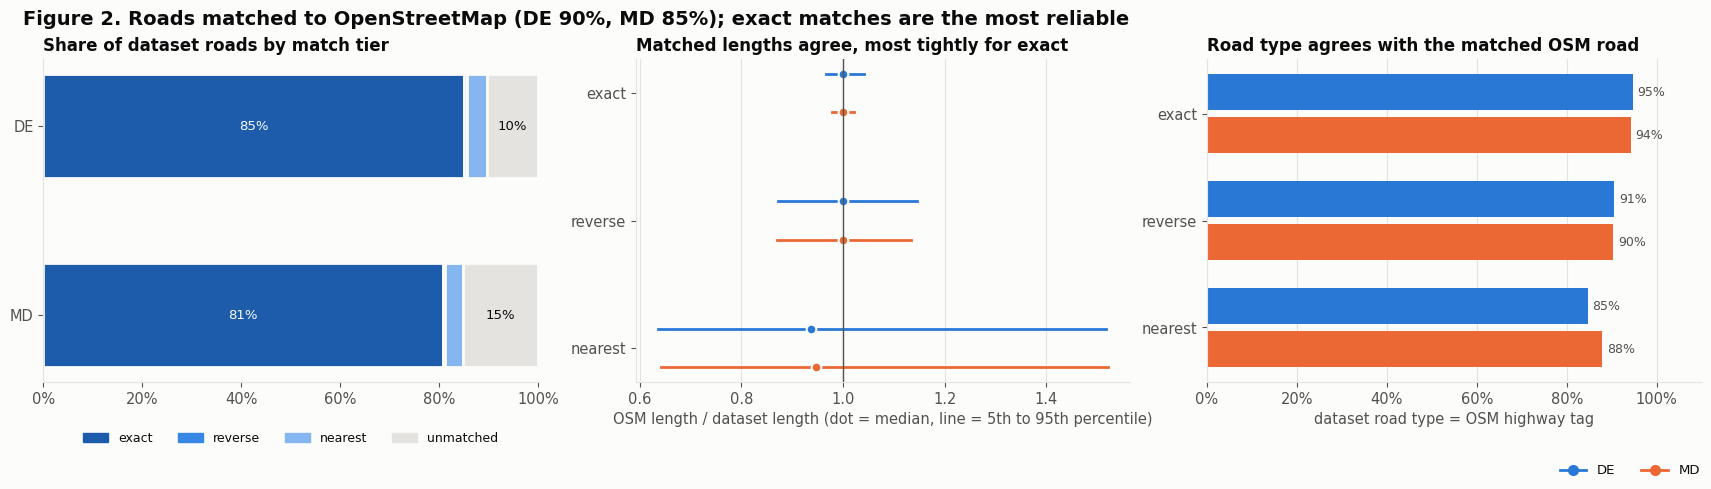

#### DE

Road match: exact 85.1%, reverse 0.5%, nearest 4.0%, unmatched 10.4%.

Node match: id 87.9%, none 9.0%, snap 3.1%; 88.8% of the dataset's node ids still exist in OSM (the OSM file is newer than the dataset); median distance to the nearest OSM node 0.0 m.

Network size: OSM has 53,248 nodes and 128,286 directed roads against the dataset's 49,023 and 116,196 (ratios 1.09 and 1.10).

Road type agrees with the matched OSM road for exact 94.6%, reverse 90.6%, nearest 84.6%.

Length ratio (OSM / dataset) by tier:

|  | roads | p05 | median | p95 | share_0.8_to_1.25 |
|---|---|---|---|---|---|
| exact | 9.89e+04 | 0.966 | 1 | 1.04 | 0.987 |
| reverse | 584 | 0.872 | 1 | 1.15 | 0.932 |
| nearest | 4.64e+03 | 0.637 | 0.937 | 1.52 | 0.489 |

Overall match rate if the nearest-road thresholds changed (current setting = 30 m and ratio 0.6-1.6; the loosest setting adds 5.1% at most)

| max distance (m) | 0.8-1.25 | 0.7-1.4 | 0.6-1.6 | 0.5-2 |
|---|---|---|---|---|
| 10 | 87.0% | 87.8% | 88.6% | 89.7% |
| 20 | 87.3% | 88.2% | 89.1% | 90.4% |
| 30 | 87.5% | 88.6% | 89.6% | 91.0% |
| 50 | 87.8% | 89.0% | 90.1% | 91.7% |
| 75 | 88.0% | 89.3% | 90.4% | 92.1% |

Most common road-type disagreements in the nearest tier (dataset type, OSM type, roads):

| dataset | osm | roads |
|---|---|---|
| primary | trunk | 145 |
| residential | tertiary | 110 |
| trunk | primary | 87 |
| secondary | primary | 62 |
| tertiary | secondary | 54 |
| unclassified | tertiary | 36 |

#### MD

Road match: exact 80.7%, reverse 0.4%, nearest 3.7%, unmatched 15.3%.

Node match: id 83.1%, none 14.3%, snap 2.6%; 83.9% of the dataset's node ids still exist in OSM (the OSM file is newer than the dataset); median distance to the nearest OSM node 0.0 m.

Network size: OSM has 242,957 nodes and 576,157 directed roads against the dataset's 250,565 and 580,526 (ratios 0.97 and 0.99).

Road type agrees with the matched OSM road for exact 94.3%, reverse 90.3%, nearest 87.9%.

Length ratio (OSM / dataset) by tier:

|  | roads | p05 | median | p95 | share_0.8_to_1.25 |
|---|---|---|---|---|---|
| exact | 4.69e+05 | 0.979 | 1 | 1.02 | 0.991 |
| reverse | 2.05e+03 | 0.871 | 1 | 1.13 | 0.939 |
| nearest | 2.13e+04 | 0.642 | 0.947 | 1.52 | 0.489 |

Overall match rate if the nearest-road thresholds changed (current setting = 30 m and ratio 0.6-1.6; the loosest setting adds 5.0% at most)

| max distance (m) | 0.8-1.25 | 0.7-1.4 | 0.6-1.6 | 0.5-2 |
|---|---|---|---|---|
| 10 | 82.3% | 82.9% | 83.6% | 84.6% |
| 20 | 82.6% | 83.4% | 84.3% | 85.4% |
| 30 | 82.9% | 83.8% | 84.7% | 86.0% |
| 50 | 83.2% | 84.2% | 85.3% | 86.7% |
| 75 | 83.4% | 84.5% | 85.7% | 87.2% |

Most common road-type disagreements in the nearest tier (dataset type, OSM type, roads):

| dataset | osm | roads |
|---|---|---|
| residential | tertiary | 643 |
| tertiary | secondary | 320 |
| secondary | primary | 269 |
| residential | unclassified | 177 |
| tertiary | residential | 145 |
| primary | trunk | 139 |

In [21]:
agreement, wrong_pairs = {}, {}
for state in STATES:
    agreement[state], wrong_pairs[state] = road_type_agreement(results[state])
plot_matching_quality(results, agreement)

for state in STATES:
    diag, roads = results[state]["diagnostics"], results[state]["roads"]
    lines = [f"#### {state}"]
    lines.append("Road match: " + ", ".join(f"{tier} {pct(roads['match_type'].eq(tier).mean())}" for tier in MATCH_TIERS) + ".")
    if diag:
        lines.append(f"Node match: " + ", ".join(f"{k} {pct(v)}" for k, v in diag["node_match_share"].items()) +
                     f"; {pct(diag['dataset_node_id_found_in_osm'])} of the dataset's node ids still exist in OSM "
                     f"(the OSM file is newer than the dataset); median distance to the nearest OSM node {diag['nearest_node_distance_m'].get('p50', float('nan')):.1f} m.")
        sizes = diag["osm_sizes"]
        lines.append(f"Network size: OSM has {sizes['osm_nodes']:,} nodes and {sizes['osm_roads']:,} directed roads against the dataset's {sizes['dataset_nodes']:,} and {sizes['dataset_roads']:,} "
                     f"(ratios {sizes['node_ratio']:.2f} and {sizes['road_ratio']:.2f}).")
    if agreement[state] is not None:
        lines.append("Road type agrees with the matched OSM road for " + ", ".join(f"{tier} {pct(agreement[state].loc[tier, 'agree'])}" for tier in MATCH_TIERS[:3]
                     if tier in agreement[state].index and pd.notna(agreement[state].loc[tier, 'agree'])) + ".")
    md("\n\n".join(lines))
    md("Length ratio (OSM / dataset) by tier:\n\n" + df_to_markdown(length_ratio_by_tier(roads).round(3)))
    sensitivity = threshold_sensitivity(roads)
    if sensitivity is not None:
        current = sensitivity.loc[ROAD_NEAREST_MAX_M, f"{ROAD_LEN_RATIO_RANGE[0]:g}-{ROAD_LEN_RATIO_RANGE[1]:g}"] if (ROAD_NEAREST_MAX_M in sensitivity.index and f"{ROAD_LEN_RATIO_RANGE[0]:g}-{ROAD_LEN_RATIO_RANGE[1]:g}" in sensitivity.columns) else np.nan
        observed = 1 - roads["match_type"].eq("unmatched").mean()
        note = "" if not np.isfinite(current) or abs(current - observed) < 1e-9 else "  **Warning:** the current config differs from the thresholds this file was built with."
        md(f"Overall match rate if the nearest-road thresholds changed (current setting = {ROAD_NEAREST_MAX_M} m and ratio {ROAD_LEN_RATIO_RANGE[0]:g}-{ROAD_LEN_RATIO_RANGE[1]:g}; "
           f"the loosest setting adds {pct(sensitivity.to_numpy().max() - sensitivity.to_numpy().min())} at most){note}\n\n" + df_to_markdown(sensitivity.apply(lambda column: column.map(lambda v: f"{v:.1%}"))))
    else:
        md("Threshold sensitivity needs the new diagnostic columns (set `FORCE_REBUILD = True` once).")
    if wrong_pairs[state] is not None and len(wrong_pairs[state]):
        md("Most common road-type disagreements in the nearest tier (dataset type, OSM type, roads):\n\n" + df_to_markdown(wrong_pairs[state].set_index("dataset")))

### 8.1 Traffic-control points lost by OSM simplification, and how many we recovered
Simplification removes nodes that are not junctions, taking their tags with them. This table is the evidence for the mid-block recovery in Section 6.

In [22]:
for state in STATES:
    diag = results[state]["diagnostics"]
    if diag and "midblock_recovery" in diag:
        table = pd.DataFrame(diag["midblock_recovery"]).T
        md(f"**{state}**\n\n" + df_to_markdown(table.round(3)))
    else:
        md(f"**{state}**: recovery statistics are not in the saved metadata (older file).")

**DE**

|  | in_file | kept_as_nodes | removed_by_simplification | recovered_mid_block | share_removed | share_of_removed_recovered |
|---|---|---|---|---|---|---|
| signal | 2.1e+03 | 1.27e+03 | 827 | 827 | 0.394 | 1 |
| stop | 2.18e+03 | 351 | 1.83e+03 | 1.83e+03 | 0.839 | 1 |
| give_way | 196 | 0 | 196 | 196 | 1 | 1 |
| crossing | 6.84e+03 | 31 | 6.81e+03 | 6.81e+03 | 0.996 | 1 |
| traffic_calming | 860 | 6 | 854 | 854 | 0.993 | 1 |

**MD**

|  | in_file | kept_as_nodes | removed_by_simplification | recovered_mid_block | share_removed | share_of_removed_recovered |
|---|---|---|---|---|---|---|
| signal | 1.05e+04 | 8.18e+03 | 2.34e+03 | 2.34e+03 | 0.222 | 1 |
| stop | 1.04e+04 | 1.61e+03 | 8.84e+03 | 8.84e+03 | 0.846 | 1 |
| give_way | 604 | 2 | 602 | 602 | 0.997 | 1 |
| crossing | 4.28e+04 | 174 | 4.26e+04 | 4.26e+04 | 0.996 | 1 |
| traffic_calming | 6.28e+03 | 43 | 6.24e+03 | 6.24e+03 | 0.993 | 1 |

## 9. Coverage diagnosis: how much of each state do the features actually describe?

Low fill is the main weakness of OSM-derived features, so before fixing it we measure *where* it comes from.
There are two possible causes: roads that did not **match** (the tag exists in OSM but we could not reach it) and roads that matched but whose OSM road **has no tag** (the information does not exist).
They need different remedies, so we separate them.

> **What.** Fill rate by road type; fill weighted by accidents (what share of accidents happen on roads where we know the value); a profile of unmatched roads; and a *ceiling* on what better matching could add:
> if every unmatched road were matched and had the same tag rate as matched roads of its own type, how many points of fill would we gain?
>
> **Why.** Fill averaged over all roads is dominated by residential streets, which have few tags and few accidents. A feature known on 15% of roads may be known on 60% of the roads that matter.
> And if the ceiling is small, spending effort on smarter matching is wasted.
>
> **Evidence.** The tables and Figure 3 below.   **Alternative.** Treat every missing value as "no" (rejected: it turns absence of mapping into a road property).

In [23]:
COVERAGE_TAGS = {"speed limit": "g1_maxspeed_mph", "lanes": "g1_lanes", "surface": "g1_surface",
                 "cycleway": "g3_cycleway_any", "sidewalk": "g3_sidewalk_any", "lit": "g3_lit"}
MAJOR_ROAD_TYPES = ["motorway", "motorway_link", "trunk", "trunk_link", "primary", "primary_link", "secondary", "secondary_link"]


def full_window(state, info):
    """First and last usable month of a state as 'YYYY-MM' (the configured window, or every month in the accident file)."""
    if state in USABLE_MONTHS:
        return USABLE_MONTHS[state]
    months = pd.to_datetime(info["accidents"][["year", "month"]].assign(day=1))
    return months.min().strftime("%Y-%m"), months.max().strftime("%Y-%m")


def get_window(state, name, info):
    """('YYYY-MM', 'YYYY-MM') for the analysis window `name`: 'train' (SPLIT), 'test' (SPLIT) or 'full' (all usable months)."""
    return full_window(state, info) if name == "full" else SPLIT[state][name]


def coverage_frame(result, totals):
    """One row per directed road: road type, matched flag, accidents, and True/False for 'has a value' for each tag."""
    features, roads = result["road_features"], result["roads"]
    frame = pd.DataFrame({"road_type": result["highway_class"].to_numpy(), "matched": (roads["match_type"] != "unmatched").to_numpy(),
                          "accidents": totals, "length_m": roads["length_m"].to_numpy()})
    for label, column in COVERAGE_TAGS.items():
        frame[label] = features[column].notna().to_numpy()
    return frame


def overall_coverage(frame):
    """Per tag: share of all roads with a value, share of matched roads, share of accidents on roads with a value, share of major roads."""
    major = frame["road_type"].isin(MAJOR_ROAD_TYPES)
    rows = {}
    for label in COVERAGE_TAGS:
        rows[label] = {"all roads": frame[label].mean(), "matched roads": frame.loc[frame["matched"], label].mean(),
                       "weighted by accidents": (frame[label] * frame["accidents"]).sum() / frame["accidents"].sum(),
                       "major roads": frame.loc[major, label].mean()}
    return pd.DataFrame(rows).T


def coverage_by_class(frame, top=8):
    """For the `top` road types by accidents: share of roads, share of accidents, match rate, and fill of each tag (share of ALL roads of that type)."""
    grouped = frame.groupby("road_type")
    table = pd.DataFrame({"share_of_roads": grouped.size() / len(frame),
                          "share_of_accidents": grouped["accidents"].sum() / frame["accidents"].sum(),
                          "match_rate": grouped["matched"].mean()})
    for label in COVERAGE_TAGS:
        table[label] = grouped[label].mean()
    return table.sort_values("share_of_accidents", ascending=False).head(top)


def unmatched_profile(frame):
    """What the unmatched roads are, and the ceiling on what matching them could add to each tag's fill.

    Returns (summary dict, by-type table, ceiling table). The ceiling assumes every unmatched road could be matched AND would then have the
    same tag rate as matched roads of its own type: an optimistic upper bound.
    """
    unmatched = ~frame["matched"]
    summary = {"share_of_roads": float(unmatched.mean()), "share_of_km": float(frame.loc[unmatched, "length_m"].sum() / frame["length_m"].sum()),
               "share_of_accidents": float(frame.loc[unmatched, "accidents"].sum() / frame["accidents"].sum()),
               "median_length_m_unmatched": float(frame.loc[unmatched, "length_m"].median()), "median_length_m_matched": float(frame.loc[~unmatched, "length_m"].median())}
    grouped = frame.groupby("road_type")
    by_type = pd.DataFrame({"roads": grouped.size(), "unmatched_share": 1 - grouped["matched"].mean(),
                            "accidents_per_road_unmatched": frame[unmatched].groupby("road_type")["accidents"].mean(),
                            "accidents_per_road_matched": frame[~unmatched].groupby("road_type")["accidents"].mean()})
    by_type = by_type.sort_values("roads", ascending=False).head(8)
    ceiling = {}
    for label in COVERAGE_TAGS:
        matched_fill = frame[frame["matched"]].groupby("road_type")[label].mean()
        n_unmatched = frame[unmatched].groupby("road_type").size()
        acc_unmatched = frame[unmatched].groupby("road_type")["accidents"].sum()
        gain_roads = (n_unmatched * matched_fill.reindex(n_unmatched.index).fillna(0)).sum() / len(frame)
        gain_accidents = (acc_unmatched * matched_fill.reindex(acc_unmatched.index).fillna(0)).sum() / frame["accidents"].sum()
        ceiling[label] = {"fill now (roads)": frame[label].mean(), "most extra from matching (points of roads)": gain_roads,
                          "fill now (accidents)": (frame[label] * frame["accidents"]).sum() / frame["accidents"].sum(),
                          "most extra from matching (points of accidents)": gain_accidents}
    return summary, by_type, pd.DataFrame(ceiling).T


def fill_by_group(result):
    """For each feature group: number of columns and the lowest / median / highest fill among ALL roads."""
    features = result["road_features"].drop(columns=["node_1_idx", "node_2_idx"])
    fill = features.notna().mean()
    rows = {}
    for group in sorted({c.split("_")[0] for c in features.columns}):
        values = fill[[c for c in features.columns if c.startswith(group + "_")]]
        rows[group] = {"columns": len(values), "lowest": values.min(), "median": values.median(), "highest": values.max()}
    table = pd.DataFrame(rows).T
    table.insert(0, "what", [FEATURE_GROUP_NAMES[g] for g in table.index])
    return table


FEATURE_GROUP_NAMES = {"g1": "road character (OSM tags)", "g2": "intersection control", "g3": "cycle, pedestrian and lighting tags",
                       "g4": "nearby places", "g5": "road shape (curviness)"}


def plot_coverage(frames, by_class, overall):
    """Figure 3: tag fill by road type (one heatmap per state) and fill by roads vs by accidents."""
    apply_chart_style()
    states = list(frames)
    fig = plt.figure(figsize=(17, 6.4), layout="constrained")
    grid = fig.add_gridspec(1, 3, width_ratios=[1, 1, 0.85])
    labels = list(COVERAGE_TAGS)
    shared = [t for t in by_class[states[0]].index if all(t in by_class[s].index for s in states)]   # road types shown in every state, most accidents first
    common_order = shared if shared else list(by_class[states[0]].index)   # same row order in every heatmap
    for column, state in enumerate(states):
        ax = fig.add_subplot(grid[0, column])
        table = by_class[state][labels].reindex(common_order).fillna(0)
        shown = pd.concat([table, pd.DataFrame([[frames[state][label].mean() for label in labels]], index=["all roads"], columns=labels)])
        ax.imshow(shown.to_numpy(), cmap=SEQ_CMAP, vmin=0, vmax=1, aspect="auto")
        for i in range(shown.shape[0]):
            for j in range(shown.shape[1]):
                value = shown.iloc[i, j]
                ax.text(j, i, f"{value:.0%}", ha="center", va="center", fontsize=9.5, color=SURFACE if value > 0.5 else INK)
        ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=30, ha="right")
        ax.set_yticks(range(shown.shape[0])); ax.set_yticklabels(shown.index)
        ax.spines[:].set_visible(False); ax.tick_params(length=0)
        ax.set_title(f"{state}: share of roads with a value, by road type")
    ax = fig.add_subplot(grid[0, 2])
    positions = np.arange(len(labels))
    for offset, state in zip((-0.2, 0.2), states):
        ax.barh(positions + offset, overall[state]["all roads"].reindex(labels), height=0.34, color=STATE_COLORS[state], alpha=0.45, label=f"{state}: roads")
        ax.barh(positions + offset, overall[state]["weighted by accidents"].reindex(labels), height=0.14, color=STATE_COLORS[state], label=f"{state}: accidents")
    ax.set_yticks(positions); ax.set_yticklabels(labels); ax.invert_yaxis()
    ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); ax.xaxis.grid(True)
    ax.set_title("Known on roads (wide) vs on accidents (thin)")
    ax.legend(fontsize=8.5, loc="lower right", ncol=1)
    headline = " | ".join("{}: speed limit on {:.0%} of roads but {:.0%} of accidents".format(s, overall[s].loc["speed limit", "all roads"],
                                                                                         overall[s].loc["speed limit", "weighted by accidents"]) for s in states)
    fig.suptitle("Figure 3. Tag coverage is low and uneven, but better where accidents are\n" + headline, x=0.01, ha="left", fontsize=12.5)
    save_figure(fig, "fig3_coverage")
    plt.show()

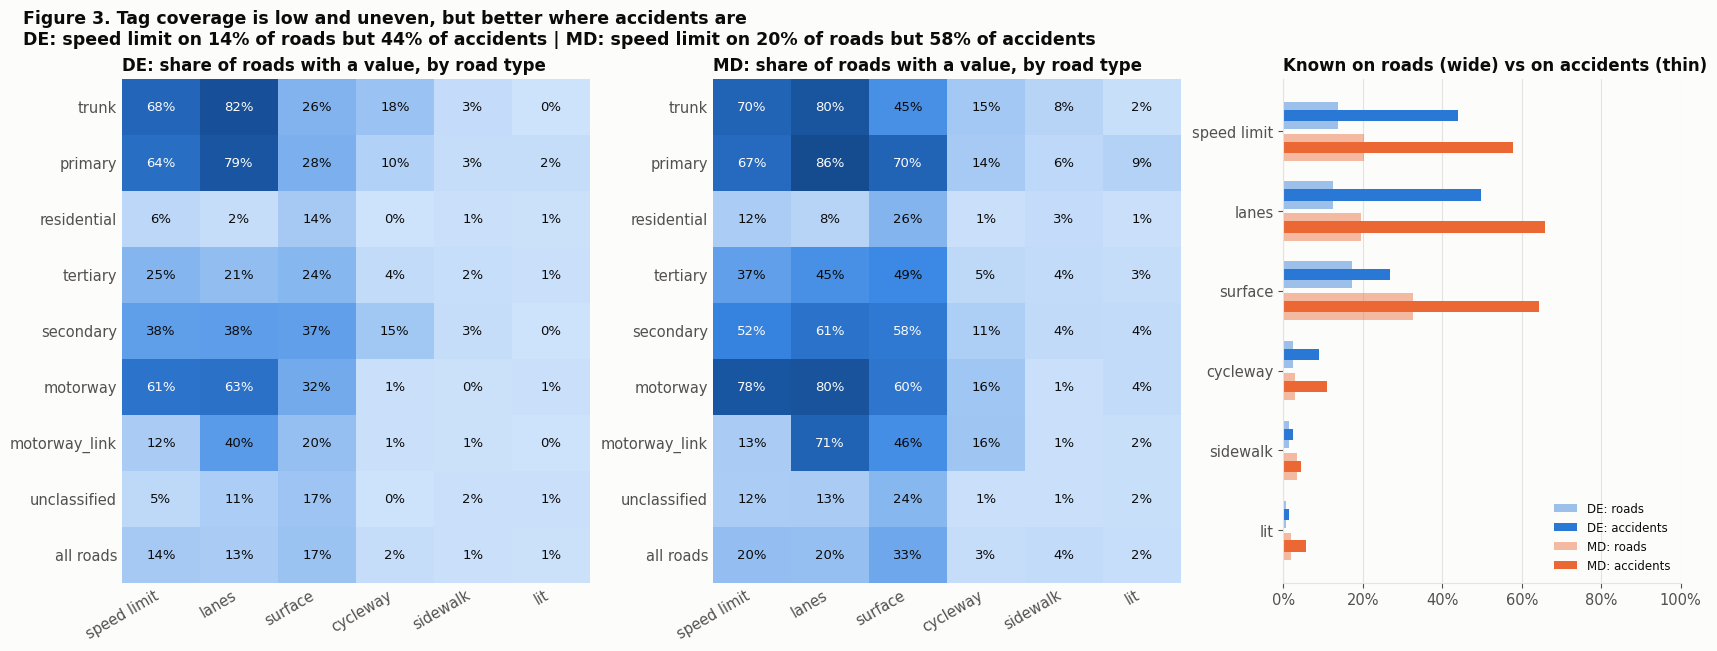

In [24]:
coverage = {}
for state in STATES:
    first, last = full_window(state, data[state])
    totals, years = accident_totals_in_period(data[state], results[state]["roads"], first, last)
    frame = coverage_frame(results[state], totals)
    summary, unmatched_by_type, ceiling = unmatched_profile(frame)
    coverage[state] = {"frame": frame, "overall": overall_coverage(frame), "by_class": coverage_by_class(frame),
                       "unmatched_summary": summary, "unmatched_by_type": unmatched_by_type, "ceiling": ceiling, "groups": fill_by_group(results[state])}

plot_coverage({s: coverage[s]["frame"] for s in STATES}, {s: coverage[s]["by_class"] for s in STATES}, {s: coverage[s]["overall"] for s in STATES})

### 9.1 Numbers behind Figure 3

In [25]:
for state in STATES:
    c = coverage[state]
    md(f"#### {state}\n\n**Share with a value, by definition of 'share'** (unmatched roads count as missing)\n\n" + df_to_markdown(c["overall"].round(3)))
    md("**By feature group** (fill among all roads; g2 flags are limited by the match rate because unmatched roads have no node tags)\n\n" + df_to_markdown(c["groups"].round(3)))

#### DE

**Share with a value, by definition of 'share'** (unmatched roads count as missing)

|  | all roads | matched roads | weighted by accidents | major roads |
|---|---|---|---|---|
| speed limit | 0.139 | 0.155 | 0.438 | 0.472 |
| lanes | 0.126 | 0.141 | 0.498 | 0.578 |
| surface | 0.173 | 0.194 | 0.268 | 0.298 |
| cycleway | 0.024 | 0.027 | 0.09 | 0.122 |
| sidewalk | 0.015 | 0.016 | 0.023 | 0.026 |
| lit | 0.006 | 0.007 | 0.014 | 0.009 |

**By feature group** (fill among all roads; g2 flags are limited by the match rate because unmatched roads have no node tags)

|  | what | columns | lowest | median | highest |
|---|---|---|---|---|---|
| g1 | road character (OSM tags) | 5 | 0.126 | 0.173 | 0.896 |
| g2 | intersection control | 14 | 0.896 | 0.896 | 0.896 |
| g3 | cycle, pedestrian and lighting tags | 3 | 0.006 | 0.015 | 0.024 |
| g4 | nearby places | 35 | 1 | 1 | 1 |
| g5 | road shape (curviness) | 1 | 0.994 | 0.994 | 0.994 |

#### MD

**Share with a value, by definition of 'share'** (unmatched roads count as missing)

|  | all roads | matched roads | weighted by accidents | major roads |
|---|---|---|---|---|
| speed limit | 0.203 | 0.24 | 0.577 | 0.542 |
| lanes | 0.196 | 0.231 | 0.658 | 0.701 |
| surface | 0.327 | 0.385 | 0.645 | 0.594 |
| cycleway | 0.03 | 0.035 | 0.11 | 0.121 |
| sidewalk | 0.036 | 0.042 | 0.045 | 0.046 |
| lit | 0.021 | 0.024 | 0.057 | 0.05 |

**By feature group** (fill among all roads; g2 flags are limited by the match rate because unmatched roads have no node tags)

|  | what | columns | lowest | median | highest |
|---|---|---|---|---|---|
| g1 | road character (OSM tags) | 5 | 0.196 | 0.327 | 0.847 |
| g2 | intersection control | 14 | 0.847 | 0.847 | 0.847 |
| g3 | cycle, pedestrian and lighting tags | 3 | 0.021 | 0.03 | 0.036 |
| g4 | nearby places | 35 | 1 | 1 | 1 |
| g5 | road shape (curviness) | 1 | 0.991 | 0.991 | 0.991 |

### 9.2 Is it worth matching more roads? The ceiling
If the ceiling is a few points, unmatched roads are not why fill is low. The remaining gap is tags that were never mapped, and only estimation or another data source can fill it.

In [26]:
for state in STATES:
    c = coverage[state]
    s = c["unmatched_summary"]
    md(f"#### {state}: unmatched roads\n\n"
       f"{pct(s['share_of_roads'])} of directed roads are unmatched, covering {pct(s['share_of_km'])} of road length and carrying {pct(s['share_of_accidents'])} of accidents. "
       f"Their median length is {s['median_length_m_unmatched']:.0f} m against {s['median_length_m_matched']:.0f} m for matched roads.\n\n"
       "By road type (top 8 by roads):\n\n" + df_to_markdown(c["unmatched_by_type"].round(3)) +
       "\n\n**Ceiling on what better matching could add** (optimistic: assumes every unmatched road could be matched, with tag rates like matched roads of its own type):\n\n" +
       df_to_markdown(c["ceiling"].round(3)))
ceiling_speed = {s: coverage[s]["ceiling"].loc["speed limit", "most extra from matching (points of roads)"] for s in STATES}
md("**Reading.** " + "; ".join("{}: matching every unmatched road could add at most {:.1f} points to speed-limit fill".format(s, 100 * ceiling_speed[s]) for s in STATES) +
   ". We therefore did **not** pursue geometry-based re-matching. Two honest exceptions: a re-match would also help g2 (node flags), whose fill is capped by the match rate, "
   "and the nearest-road thresholds in Section 8 show how much a looser rule would add (and risk).")

#### DE: unmatched roads

10.4% of directed roads are unmatched, covering 14.1% of road length and carrying 15.7% of accidents. Their median length is 122 m against 112 m for matched roads.

By road type (top 8 by roads):

| road_type | roads | unmatched_share | accidents_per_road_unmatched | accidents_per_road_matched |
|---|---|---|---|---|
| residential | 8.38e+04 | 0.088 | 1.05 | 1.05 |
| tertiary | 1.27e+04 | 0.126 | 6.09 | 5.49 |
| secondary | 6.39e+03 | 0.142 | 7.78 | 9.5 |
| primary | 4.57e+03 | 0.098 | 20 | 19.7 |
| trunk | 3.21e+03 | 0.174 | 33.1 | 27.6 |
| unclassified | 2.81e+03 | 0.273 | 2.78 | 3.2 |
| trunk_link | 953 | 0.169 | 3.53 | 4.13 |
| primary_link | 472 | 0.114 | 3.83 | 2.88 |

**Ceiling on what better matching could add** (optimistic: assumes every unmatched road could be matched, with tag rates like matched roads of its own type):

|  | fill now (roads) | most extra from matching (points of roads) | fill now (accidents) | most extra from matching (points of accidents) |
|---|---|---|---|---|
| speed limit | 0.139 | 0.02 | 0.438 | 0.091 |
| lanes | 0.126 | 0.02 | 0.498 | 0.104 |
| surface | 0.173 | 0.022 | 0.268 | 0.052 |
| cycleway | 0.024 | 0.004 | 0.09 | 0.015 |
| sidewalk | 0.015 | 0.002 | 0.023 | 0.004 |
| lit | 0.006 | 0.001 | 0.014 | 0.001 |

#### MD: unmatched roads

15.3% of directed roads are unmatched, covering 15.8% of road length and carrying 10.8% of accidents. Their median length is 101 m against 119 m for matched roads.

By road type (top 8 by roads):

| road_type | roads | unmatched_share | accidents_per_road_unmatched | accidents_per_road_matched |
|---|---|---|---|---|
| residential | 4.29e+05 | 0.157 | 0.21 | 0.501 |
| tertiary | 5.6e+04 | 0.124 | 1.58 | 2.31 |
| secondary | 3.74e+04 | 0.13 | 2.6 | 4.11 |
| primary | 2.26e+04 | 0.125 | 5.33 | 8.69 |
| unclassified | 1.83e+04 | 0.187 | 1.02 | 1.11 |
| trunk | 5.93e+03 | 0.199 | 8.87 | 11.5 |
| motorway_link | 4e+03 | 0.133 | 7.79 | 6.37 |
| motorway | 2.26e+03 | 0.189 | 52.4 | 44.1 |

**Ceiling on what better matching could add** (optimistic: assumes every unmatched road could be matched, with tag rates like matched roads of its own type):

|  | fill now (roads) | most extra from matching (points of roads) | fill now (accidents) | most extra from matching (points of accidents) |
|---|---|---|---|---|
| speed limit | 0.203 | 0.035 | 0.577 | 0.066 |
| lanes | 0.196 | 0.032 | 0.658 | 0.077 |
| surface | 0.327 | 0.057 | 0.645 | 0.065 |
| cycleway | 0.03 | 0.005 | 0.11 | 0.014 |
| sidewalk | 0.036 | 0.006 | 0.045 | 0.005 |
| lit | 0.021 | 0.003 | 0.057 | 0.005 |

**Reading.** DE: matching every unmatched road could add at most 2.0 points to speed-limit fill; MD: matching every unmatched road could add at most 3.5 points to speed-limit fill. We therefore did **not** pursue geometry-based re-matching. Two honest exceptions: a re-match would also help g2 (node flags), whose fill is capped by the match rate, and the nearest-road thresholds in Section 8 show how much a looser rule would add (and risk).

## 10. Filling gaps in speed limit, lanes and surface (validated estimates)

> **What.** For roads whose OSM road has no tag for speed limit, lanes or surface (or that did not match), we estimate the missing value from two things that need **no accident data**:
> (1) **neighbours**: the typical known value on roads of the *same road type that touch this road* (one hop, then two hops through already-estimated roads);
> (2) **road type**: the typical known value for that road type in the state. If neither exists, the state-wide typical value.
> Speed limits are snapped to the nearest 5 mph and lanes to whole numbers. Every estimate is marked: the original column is never overwritten, and a separate `*_filled` column and an `*_is_est` flag are added.
>
> **Why.** Speed limit, lanes and surface are known on only a minority of roads, but they plausibly matter. A road's speed limit is usually the same as the road it continues from, and a residential street is almost always 25 mph,
> so a simple, explainable rule can recover much of what is missing. It is also a data-cleaning step in its own right.
>
> **Evidence (the part that decides whether to keep it).** *Masked cross-validation*: hide a fifth of the **known** values (stratified by road type), fill them using only the rest, and compare with the truth; repeat so every known value is hidden once.
> Three methods are scored on the hidden values: the state-wide typical value (the baseline to beat), road type only, and neighbours + road type.
> A method is **kept** only if it beats the state-wide value by at least `IMPUTE_MIN_GAIN` and reaches `IMPUTE_MIN_ACCURACY` (a speed estimate counts as correct within `SPEED_TOLERANCE_MPH`).
> It must also reach `IMPUTE_MIN_ACCURACY` as an **expected accuracy on the roads that are really missing**: the accuracy of each fill source (neighbours, road type, ...) weighted by how many missing roads use that source. Tagged roads are mostly major roads, so the validation accuracy can flatter the method; this second test uses the mix of the roads we would actually fill. Otherwise that feature is left missing.
>
> **Alternatives considered.** A learned model on geometry and place counts (more complex, harder to explain, and risks using accident-correlated signals); using accident counts to fill (leaks the label, rejected outright);
> other data sources such as state DOT speed-zone files or street imagery (not tried here; see the limitations register); not filling at all (the safe default, and what happens to any feature that fails the gate).
>
> **Limits, stated up front.** (a) Validation can only use roads that **have** a tag, and those are mostly major roads, so accuracy on the typical missing residential street is less certain (we show accuracy by road type and the share of missing roads in road types with few validation cases).
> (b) Hiding values at random makes neighbours easier to find than in reality, where untagged roads come in clusters. (c) An estimate is a guess about the road *as OSM describes it today*, not as it was when the accidents happened.
> **Estimates are never used in the trend analysis (Section 11)**; they exist for the model hand-off.

In [27]:
from scipy import sparse

SPEED_STEP_MPH = 5


def physical_attribute_table(roads, road_features, highway_class):
    """One row per PHYSICAL road (both directions merged) with the road type and the raw values of the features to fill."""
    frame = pd.DataFrame({"road_u": roads["road_u"].to_numpy(), "road_v": roads["road_v"].to_numpy(),
                          "road_type": base_road_type(highway_class).to_numpy()})
    for column in IMPUTE_FEATURES:
        frame[column] = road_features[column].to_numpy()
    return frame.groupby(["road_u", "road_v"]).first()   # first() skips missing values: if either direction has a value, it is used


def neighbour_matrix(road_u, road_v, class_codes):
    """Sparse matrix W: W[i, j] > 0 when physical roads i and j share a node AND have the same road type (diagonal removed)."""
    n = len(road_u)
    n_classes = int(class_codes.max()) + 1
    columns = np.concatenate([road_u.astype(np.int64) * n_classes + class_codes, road_v.astype(np.int64) * n_classes + class_codes])
    codes, _ = pd.factorize(columns)
    rows = np.concatenate([np.arange(n), np.arange(n)])
    incidence = sparse.csr_matrix((np.ones(len(rows)), (rows, codes)), shape=(n, codes.max() + 1))
    W = (incidence @ incidence.T).tocsr()
    W.setdiag(0)
    W.eliminate_zeros()
    return W


def snap_estimate(kind, values):
    """Round an estimate to what the tag can look like: speed to the nearest 5 mph, lanes to a whole number >= 1."""
    if kind == "speed":
        return np.clip(np.round(values / SPEED_STEP_MPH) * SPEED_STEP_MPH, SPEED_STEP_MPH, 85)
    if kind == "lanes":
        return np.clip(np.round(values), 1, 12)
    return values


def neighbour_estimate(kind, values, known, W, n_categories=0):
    """For every road: the typical value among its same-type touching neighbours that have a known value (NaN if none).

    Numbers: the mean of the neighbours' values, snapped. Surface: the most common neighbour category.
    `values` are floats (category codes for surface), `known` says which entries may be used as sources.
    """
    if kind == "surface":
        counts = np.column_stack([W @ ((values == c) & known).astype(float) for c in range(n_categories)])
        best = counts.argmax(axis=1).astype(float)
        best[counts.sum(axis=1) == 0] = np.nan
        return best
    total = W @ np.where(known, values, 0.0)
    weight = W @ known.astype(float)
    with np.errstate(invalid="ignore", divide="ignore"):
        estimate = np.where(weight > 0, total / weight, np.nan)
    return snap_estimate(kind, estimate)


def typical_value(kind, values, known, class_codes, n_categories=0):
    """The state-wide typical value and the typical value of each road type (NaN-free: types with no known value get the state-wide one).

    Returns (state_value, array with one typical value per road).
    """
    if kind == "surface":
        state_value = float(np.bincount(values[known].astype(int), minlength=n_categories).argmax())
        table = pd.crosstab(class_codes[known], values[known].astype(int))
        per_class = pd.Series(table.columns[table.to_numpy().argmax(axis=1)].to_numpy().astype(float), index=table.index) if len(table) else pd.Series(dtype=float)
    else:
        state_value = float(snap_estimate(kind, np.median(values[known])))
        per_class = pd.Series(values[known]).groupby(class_codes[known]).median()
        per_class = pd.Series(snap_estimate(kind, per_class.to_numpy()), index=per_class.index)
    return state_value, per_class.reindex(class_codes).fillna(state_value).to_numpy()


def fill_strategies(kind, values, known, class_codes, W, n_categories=0):
    """All three filling methods at once, using only entries marked `known` as information.

    Returns a dict with arrays over all roads: `state` (state-wide value), `type` (road type value), `full` (neighbours then road type),
    and `source` for `full`: 1 = one-hop neighbours, 2 = two-hop, 3 = road type, 4 = state-wide value.
    """
    state_value, type_values = typical_value(kind, values, known, class_codes, n_categories)
    first = neighbour_estimate(kind, values, known, W, n_categories)
    got_first = np.isfinite(first) & ~known
    values_2 = np.where(known, values, np.where(got_first, first, np.nan))
    second = neighbour_estimate(kind, np.nan_to_num(values_2, nan=-1.0), np.isfinite(values_2), W, n_categories)
    got_second = np.isfinite(second) & ~known & ~got_first

    full = type_values.copy()
    source = np.where(np.isin(class_codes, class_codes[known]), 3, 4)
    full[got_second], source[got_second] = second[got_second], 2
    full[got_first], source[got_first] = first[got_first], 1
    return {"state": np.full(len(values), state_value), "type": type_values, "full": full, "source": source}


def encode_feature(series, kind):
    """(values as floats with NaN for missing, category names or None). Surface text becomes category codes 0, 1, 2, ..."""
    if kind == "surface":
        categories = sorted(series.dropna().unique())
        lookup = {name: code for code, name in enumerate(categories)}
        return series.map(lookup).astype(float).to_numpy(), categories
    return series.astype(float).to_numpy(), None


def is_correct(kind, predicted, truth):
    """True where an estimate counts as right: speed within SPEED_TOLERANCE_MPH, lanes and surface exactly."""
    if kind == "speed":
        return np.abs(predicted - truth) <= SPEED_TOLERANCE_MPH
    return predicted == truth


def masked_cross_validation(kind, values, class_codes, W, n_categories, folds, seed):
    """Hide each known value once (stratified by road type), fill it without that value, and keep both for scoring.

    Returns a DataFrame with one row per known road: road type code, the truth, the three estimates and the source of the `full` one.
    """
    known = np.isfinite(values)
    known_index = np.flatnonzero(known)
    rng = np.random.default_rng(seed)
    order = rng.permutation(known_index)
    rank_in_type = pd.Series(np.arange(len(order))).groupby(class_codes[order]).cumcount().to_numpy()
    fold = np.full(len(values), -1)
    fold[order] = rank_in_type % folds
    parts = []
    for k in range(folds):
        hidden = fold == k
        visible = known & ~hidden
        result = fill_strategies(kind, np.where(visible, values, np.nan), visible, class_codes, W, n_categories)
        parts.append(pd.DataFrame({"type_code": class_codes[hidden], "truth": values[hidden], "state": result["state"][hidden],
                                   "type": result["type"][hidden], "full": result["full"][hidden], "source": result["source"][hidden]}))
    return pd.concat(parts, ignore_index=True)


METHOD_LABELS = {"state": "state-wide typical value", "type": "road type", "full": "neighbours + road type"}


def score_validation(kind, records):
    """Accuracy (and mean absolute error for numbers) of each method on the hidden values; accuracy of `full` by where its estimate came from."""
    scores = {}
    for method in METHOD_LABELS:
        correct = is_correct(kind, records[method].to_numpy(), records["truth"].to_numpy())
        scores[method] = {"accuracy": float(correct.mean())}
        if kind != "surface":
            scores[method]["mean_abs_error"] = float(np.abs(records[method] - records["truth"]).mean())
    by_source = records.assign(correct=is_correct(kind, records["full"].to_numpy(), records["truth"].to_numpy())).groupby("source").agg(
        hidden=("correct", "size"), accuracy=("correct", "mean"))
    return pd.DataFrame(scores).T, by_source


def decide_method(scores):
    """The gate. Returns (method to use: 'full', 'type' or 'none', plain-language reason)."""
    baseline = scores.loc["state", "accuracy"]
    passing = {m: scores.loc[m, "accuracy"] for m in ("type", "full")
               if scores.loc[m, "accuracy"] - baseline >= IMPUTE_MIN_GAIN and scores.loc[m, "accuracy"] >= IMPUTE_MIN_ACCURACY}
    if not passing:
        best = max(scores.loc[m, "accuracy"] for m in ("type", "full"))
        return "none", f"best method reaches {best:.0%}; needs +{IMPUTE_MIN_GAIN:.0%} over the state-wide value ({baseline:.0%}) and at least {IMPUTE_MIN_ACCURACY:.0%}"
    if "full" in passing and passing["full"] >= passing.get("type", 0) + IMPUTE_NEIGHBOUR_EXTRA:
        return "full", f"neighbours + road type reaches {passing['full']:.0%} against {baseline:.0%} for the state-wide value"
    method = max(passing, key=passing.get)
    return method, f"{METHOD_LABELS[method]} reaches {passing[method]:.0%} against {baseline:.0%} for the state-wide value"


def validation_by_road_type(kind, records, type_names):
    """Hidden-value accuracy of each method, by road type, with the number of hidden values."""
    table = records.assign(**{m: is_correct(kind, records[m].to_numpy(), records["truth"].to_numpy()) for m in METHOD_LABELS})
    out = table.groupby("type_code").agg(hidden=("truth", "size"), state=("state", "mean"), type=("type", "mean"), full=("full", "mean"))
    out.index = [type_names[int(c)] for c in out.index]
    return out.sort_values("hidden", ascending=False)


def fill_state(state, result, folds=IMPUTE_FOLDS, seed=RANDOM_SEED):
    """Validate and apply the gap-filling for one state.

    Returns a dict with `validation` (per feature: scores, by_source, by_type, decision, reason), `filled` (a DataFrame aligned with the
    directed roads: `<feature>_filled`, `<feature>_is_est`, `<feature>_est_source`), and `physical` (the physical-road table).
    """
    roads, features, classes = result["roads"], result["road_features"], result["highway_class"]
    physical = physical_attribute_table(roads, features, classes)
    type_names = sorted(physical["road_type"].dropna().unique())
    class_codes = physical["road_type"].map({name: code for code, name in enumerate(type_names)}).fillna(len(type_names)).astype(int).to_numpy()
    type_names = type_names + ["unknown"]
    W = neighbour_matrix(physical.index.get_level_values("road_u").to_numpy(), physical.index.get_level_values("road_v").to_numpy(), class_codes)

    directed_key = pd.MultiIndex.from_arrays([roads["road_u"].to_numpy(), roads["road_v"].to_numpy()])
    validation, filled = {}, pd.DataFrame(index=roads.index)
    for column, kind in IMPUTE_FEATURES.items():
        values, categories = encode_feature(physical[column], kind)
        n_categories = len(categories) if categories else 0
        known = np.isfinite(values)
        if known.sum() < 50 * IMPUTE_FOLDS:
            validation[column] = {"decision": "none", "reason": f"only {int(known.sum())} known values; too few to validate"}
            decision = "none"
            estimate = np.full(len(values), np.nan); source = np.zeros(len(values), dtype=int)
        else:
            records = masked_cross_validation(kind, values, class_codes, W, n_categories, folds, seed)
            scores, by_source = score_validation(kind, records)
            decision, reason = decide_method(scores)
            validation[column] = {"scores": scores, "by_source": by_source, "by_type": validation_by_road_type(kind, records, type_names),
                                  "decision": decision, "reason": reason, "kind": kind, "n_known": int(known.sum())}
            applied = fill_strategies(kind, values, known, class_codes, W, n_categories)
            estimate, source = applied["full" if decision == "full" else "type"], applied["source"]
            if decision == "type":
                source = np.where(known, 0, np.where(np.isin(class_codes, class_codes[known]), 3, 4))
            # mix of where the real estimates come from (decides how much to trust the overall accuracy)
            missing = ~known
            if decision != "none":
                mix = pd.Series(source[missing]).value_counts(normalize=True).sort_index()
                validation[column]["real_source_mix"] = mix
                if decision == "full":
                    accuracy_by_source = by_source["accuracy"]
                    validation[column]["expected_accuracy_on_missing"] = float(sum(mix.get(s, 0) * accuracy_by_source.get(s, np.nan) for s in mix.index if s in accuracy_by_source.index))
                else:
                    validation[column]["expected_accuracy_on_missing"] = float(scores.loc["type", "accuracy"])
                few = validation[column]["by_type"]
                small_types = set(few.index[few["hidden"] < 30])
                share_in_small = float(np.isin(class_codes[missing], [i for i, name in enumerate(type_names) if name in small_types]).mean())
                validation[column]["missing_share_in_types_with_few_validation_cases"] = share_in_small
                # Second gate: the accuracy that matters is the one on the roads that are really missing (mostly minor roads),
                # not the accuracy on the tagged roads used for validation.
                expected = validation[column]["expected_accuracy_on_missing"]
                if not expected >= IMPUTE_MIN_ACCURACY:
                    decision = "none"
                    validation[column]["decision"] = "none"
                    validation[column]["reason"] = (f"{reason}; but the expected accuracy on the roads that are really missing is {expected:.0%}, "
                                                    f"below the required {IMPUTE_MIN_ACCURACY:.0%}, so it is not filled")
        if decision == "none":
            filled_values = values.copy()
            is_est = np.zeros(len(values), dtype=bool)
            source_name = np.where(np.isfinite(values), "known", "none")
        else:
            filled_values = np.where(np.isfinite(values), values, estimate)
            is_est = ~np.isfinite(values) & np.isfinite(filled_values)
            names = np.array(["known", "neighbour", "neighbour2", "road_type", "state_value"], dtype=object)
            source_name = np.where(is_est, names[np.clip(source, 0, 4)], np.where(np.isfinite(values), "known", "none"))
        if categories:
            decoded = np.where(np.isfinite(filled_values), np.array(categories + [None], dtype=object)[np.where(np.isfinite(filled_values), filled_values, len(categories)).astype(int)], None)
            filled_values = decoded
        physical_out = pd.DataFrame({f"{column}_filled": filled_values, f"{column}_is_est": is_est.astype(float), f"{column}_est_source": source_name},
                                    index=physical.index)
        mapped = physical_out.reindex(directed_key)
        mapped.index = roads.index
        filled = pd.concat([filled, mapped], axis=1)
    return {"validation": validation, "filled": filled, "physical": physical}


def coverage_after_filling(state_fill, result, totals):
    """For each filled feature: share of directed roads (and of accidents) that are known, estimated and still missing."""
    rows = {}
    for column in IMPUTE_FEATURES:
        known = result["road_features"][column].notna().to_numpy()
        estimated = state_fill["filled"][f"{column}_is_est"].to_numpy() == 1
        for basis, weights in (("roads", np.ones(len(known))), ("accidents", totals)):
            total = weights.sum()
            rows[(column, basis)] = {"known": (weights * known).sum() / total, "estimated": (weights * estimated).sum() / total,
                                     "still missing": (weights * ~(known | estimated)).sum() / total}
    table = pd.DataFrame(rows).T
    table.index.names = ["feature", "share of"]
    return table

In [28]:
fills, fill_coverage = {}, {}
for state in STATES:
    started = time.time()
    fills[state] = fill_state(state, results[state])
    first, last = full_window(state, data[state])
    totals, _ = accident_totals_in_period(data[state], results[state]["roads"], first, last)
    fill_coverage[state] = coverage_after_filling(fills[state], results[state], totals)
    print(f"{state}: gap-filling validated and applied in {time.time() - started:.0f} s")

DE: gap-filling validated and applied in 1 s
MD: gap-filling validated and applied in 4 s


### 10.1 Did the methods pass the gate?
Accuracy on the hidden values (higher is better). The state-wide typical value is the baseline: a method that cannot beat it adds nothing.

In [29]:
FEATURE_LABELS = {"g1_maxspeed_mph": "speed limit", "g1_lanes": "lanes", "g1_surface": "surface"}


def validation_table(fills):
    """One row per state and feature: accuracy of each method on hidden values, and the gate decision."""
    rows = []
    for state, fill in fills.items():
        for column, entry in fill["validation"].items():
            row = {"state": state, "feature": FEATURE_LABELS[column], "decision": {"full": "neighbours + road type", "type": "road type only", "none": "not filled"}[entry["decision"]],
                   "reason": entry["reason"]}
            if "scores" in entry:
                row.update({"known values": entry["n_known"]})
                for method in METHOD_LABELS:
                    row[METHOD_LABELS[method]] = entry["scores"].loc[method, "accuracy"]
                if "expected_accuracy_on_missing" in entry:
                    row["expected accuracy on the missing roads"] = entry["expected_accuracy_on_missing"]
            rows.append(row)
    return pd.DataFrame(rows).set_index(["state", "feature"])


gate_table = validation_table(fills)
md("Accuracy on hidden values (speed limit: within " + str(SPEED_TOLERANCE_MPH) + " mph; lanes and surface: exact).\n\n" + df_to_markdown(gate_table.round(3)))

Accuracy on hidden values (speed limit: within 5 mph; lanes and surface: exact).

|  | decision | reason | known values | state-wide typical value | road type | neighbours + road type | expected accuracy on the missing roads |
|---|---|---|---|---|---|---|---|
| ('DE', 'speed limit') | neighbours + road type | neighbours + road type reaches 96% against 29% for the state-wide value | 10482 | 0.291 | 0.644 | 0.963 | 0.635 |
| ('DE', 'lanes') | not filled | neighbours + road type reaches 73% against 64% for the state-wide value; but the expected accuracy on the roads that are really missing is 55%, below the required 60%, so it is not filled | 10526 | 0.638 | 0.638 | 0.732 | 0.55 |
| ('DE', 'surface') | not filled | best method reaches 97%; needs +5% over the state-wide value (95%) and at least 60% | 11775 | 0.95 | 0.95 | 0.973 |  |
| ('MD', 'speed limit') | neighbours + road type | neighbours + road type reaches 97% against 66% for the state-wide value | 70583 | 0.662 | 0.825 | 0.972 | 0.815 |
| ('MD', 'lanes') | neighbours + road type | neighbours + road type reaches 73% against 63% for the state-wide value | 71629 | 0.63 | 0.597 | 0.734 | 0.672 |
| ('MD', 'surface') | not filled | best method reaches 98%; needs +5% over the state-wide value (97%) and at least 60% | 109327 | 0.966 | 0.966 | 0.976 |  |

### 10.2 Figure 4: coverage before and after, and how the methods compare

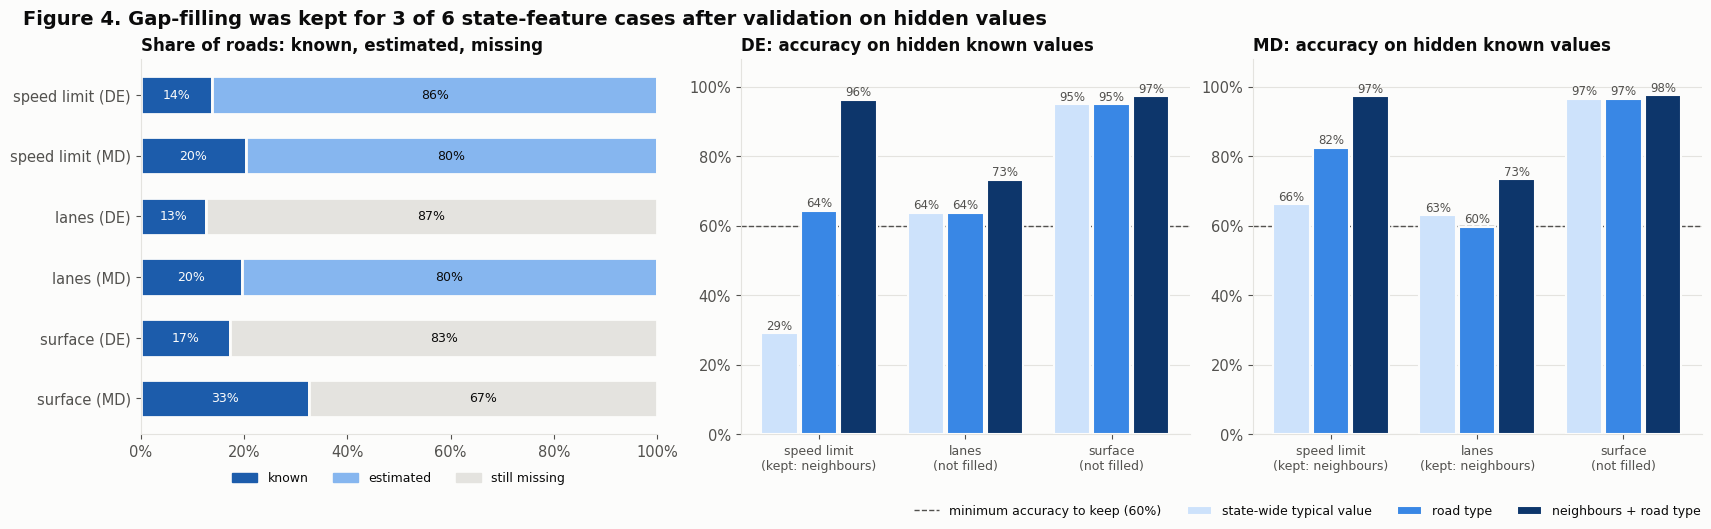

In [30]:
def plot_gap_filling(fills, fill_coverage):
    """Figure 4: known / estimated / missing shares before and after, and the accuracy of each method on hidden values."""
    apply_chart_style()
    states = list(fills)
    columns = list(IMPUTE_FEATURES)
    fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), gridspec_kw={"width_ratios": [1.15, 1, 1]}, layout="constrained")
    ax = axes[0]
    labels, row = [], 0
    colors = {"known": BLUE_RAMP[3], "estimated": BLUE_RAMP[1], "still missing": GRID_COLOR}
    for column in columns:
        for state in states:
            table = fill_coverage[state].loc[(column, "roads")]
            left = 0.0
            for part in ("known", "estimated", "still missing"):
                ax.barh(row, table[part], left=left, color=colors[part], height=0.62, edgecolor=SURFACE, linewidth=2)
                if table[part] > 0.06:
                    ax.text(left + table[part] / 2, row, f"{table[part]:.0%}", ha="center", va="center", fontsize=9, color=SURFACE if part == "known" else INK)
                left += table[part]
            labels.append(f"{FEATURE_LABELS[column]} ({state})")
            row += 1
    ax.set_yticks(range(row)); ax.set_yticklabels(labels); ax.invert_yaxis()
    ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=colors[p]) for p in colors], labels=list(colors), ncol=3, loc="upper center",
              bbox_to_anchor=(0.5, -0.07), fontsize=9)
    ax.set_title("Share of roads: known, estimated, missing")

    method_colors = {"state": BLUE_RAMP[0], "type": BLUE_RAMP[2], "full": BLUE_RAMP[4]}
    for ax, state in zip(axes[1:], states):
        positions = np.arange(len(columns))
        for offset, method in zip((-0.27, 0, 0.27), METHOD_LABELS):
            values = [fills[state]["validation"][c]["scores"].loc[method, "accuracy"] if "scores" in fills[state]["validation"][c] else np.nan for c in columns]
            ax.bar(positions + offset, values, width=0.25, color=method_colors[method], edgecolor=SURFACE, linewidth=1.5,
                   label=METHOD_LABELS[method], zorder=3)
            for x, v in zip(positions + offset, values):
                if np.isfinite(v):
                    ax.text(x, v + 0.012, f"{v:.0%}", ha="center", fontsize=8.5, color=INK_SECONDARY)
        ax.axhline(IMPUTE_MIN_ACCURACY, color=INK_SECONDARY, lw=1, ls="--", label="minimum accuracy to keep ({:.0%})".format(IMPUTE_MIN_ACCURACY))
        decisions = [{"full": "kept: neighbours", "type": "kept: road type", "none": "not filled"}[fills[state]["validation"][c]["decision"]] for c in columns]
        ax.set_xticks(positions); ax.set_xticklabels([f"{FEATURE_LABELS[c]}\n({d})" for c, d in zip(columns, decisions)], fontsize=9)
        ax.set_ylim(0, 1.08); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); ax.yaxis.grid(True)
        ax.set_title(f"{state}: accuracy on hidden known values")
    handles, labels_ = axes[1].get_legend_handles_labels()
    fig.legend(handles, labels_, loc="outside lower right", ncol=4, fontsize=9)
    kept = sum(1 for s in states for c in columns if fills[s]["validation"][c]["decision"] != "none")
    fig.suptitle(f"Figure 4. Gap-filling was kept for {kept} of {len(states) * len(columns)} state-feature cases after validation on hidden values", x=0.01, ha="left")
    save_figure(fig, "fig4_gap_filling")
    plt.show()


plot_gap_filling(fills, fill_coverage)

### 10.3 Where the estimates come from, and how far to trust them
*Source* says how an estimate was made: one-hop or two-hop neighbours, road type, or the state-wide value. Neighbour estimates are usually the most reliable;
the state-wide value is a last resort. The last column warns about missing roads whose road type has too few validation cases (under 30) to know how accurate the estimate is.

In [31]:
for state in STATES:
    parts = []
    for column in IMPUTE_FEATURES:
        entry = fills[state]["validation"][column]
        if "real_source_mix" in entry and entry["decision"] != "none":
            names = {1: "neighbour", 2: "neighbour (2 hops)", 3: "road type", 4: "state-wide value"}
            mix = ", ".join(f"{names[int(s)]} {pct(v)}" for s, v in entry["real_source_mix"].items())
            accuracy_by_source = entry["by_source"]["accuracy"] if entry["decision"] == "full" else None
            detail = "" if accuracy_by_source is None else " Accuracy on hidden values by source: " + ", ".join(f"{names[int(s)]} {pct(a)}" for s, a in accuracy_by_source.items()) + "."
            parts.append(f"* **{FEATURE_LABELS[column]}**: estimates come from {mix}.{detail} "
                         f"{pct(entry['missing_share_in_types_with_few_validation_cases'])} of the missing roads are in road types with fewer than 30 validation cases.")
        else:
            parts.append(f"* **{FEATURE_LABELS[column]}**: not filled ({entry['reason']}).")
    md(f"#### {state}\n\n" + "\n".join(parts))
    for column in IMPUTE_FEATURES:
        entry = fills[state]["validation"][column]
        if "by_type" in entry and entry["decision"] != "none":
            md(f"Accuracy on hidden {FEATURE_LABELS[column]} values by road type ({state}):\n\n" + df_to_markdown(entry["by_type"].head(8).round(3)))

#### DE

* **speed limit**: estimates come from neighbour 7.7%, neighbour (2 hops) 3.6%, road type 88.6%, state-wide value 0.0%. Accuracy on hidden values by source: neighbour 97.7%, neighbour (2 hops) 94.9%, road type 59.2%. 0.0% of the missing roads are in road types with fewer than 30 validation cases.
* **lanes**: not filled (neighbours + road type reaches 73% against 64% for the state-wide value; but the expected accuracy on the roads that are really missing is 55%, below the required 60%, so it is not filled).
* **surface**: not filled (best method reaches 97%; needs +5% over the state-wide value (95%) and at least 60%).

Accuracy on hidden speed limit values by road type (DE):

|  | hidden | state | type | full |
|---|---|---|---|---|
| residential | 2.76e+03 | 0.017 | 0.755 | 0.969 |
| primary | 2.28e+03 | 0.537 | 0.537 | 0.973 |
| trunk | 2.14e+03 | 0.316 | 0.804 | 0.975 |
| tertiary | 1.71e+03 | 0.35 | 0.596 | 0.951 |
| secondary | 1.32e+03 | 0.374 | 0.374 | 0.951 |
| motorway | 205 | 0.034 | 0.766 | 0.873 |
| unclassified | 84 | 0.06 | 0.702 | 0.821 |

#### MD

* **speed limit**: estimates come from neighbour 8.9%, neighbour (2 hops) 5.1%, road type 85.9%, state-wide value 0.1%. Accuracy on hidden values by source: neighbour 98.0%, neighbour (2 hops) 95.7%, road type 78.9%, state-wide value 100.0%. 0.0% of the missing roads are in road types with fewer than 30 validation cases.
* **lanes**: estimates come from neighbour 9.2%, neighbour (2 hops) 5.0%, road type 85.6%, state-wide value 0.1%. Accuracy on hidden values by source: neighbour 73.9%, neighbour (2 hops) 69.1%, road type 66.4%, state-wide value 0.0%. 0.0% of the missing roads are in road types with fewer than 30 validation cases.
* **surface**: not filled (best method reaches 98%; needs +5% over the state-wide value (97%) and at least 60%).

Accuracy on hidden speed limit values by road type (MD):

|  | hidden | state | type | full |
|---|---|---|---|---|
| residential | 2.93e+04 | 0.946 | 0.946 | 0.987 |
| secondary | 1.17e+04 | 0.465 | 0.667 | 0.968 |
| tertiary | 1.13e+04 | 0.752 | 0.891 | 0.988 |
| primary | 1.09e+04 | 0.354 | 0.644 | 0.967 |
| trunk | 4.03e+03 | 0.031 | 0.857 | 0.97 |
| motorway | 2.26e+03 | 0.111 | 0.584 | 0.781 |
| unclassified | 1.21e+03 | 0.767 | 0.767 | 0.941 |
| living_street | 2 | 0 | 1 | 1 |

Accuracy on hidden lanes values by road type (MD):

|  | hidden | state | type | full |
|---|---|---|---|---|
| residential | 1.79e+04 | 0.789 | 0.789 | 0.865 |
| primary | 1.44e+04 | 0.421 | 0.259 | 0.625 |
| tertiary | 1.42e+04 | 0.778 | 0.778 | 0.845 |
| secondary | 1.41e+04 | 0.631 | 0.631 | 0.718 |
| trunk | 5.06e+03 | 0.565 | 0.565 | 0.616 |
| motorway | 4.66e+03 | 0.266 | 0.266 | 0.4 |
| unclassified | 1.35e+03 | 0.693 | 0.693 | 0.745 |
| living_street | 1 | 0 | 0 | 0 |

**How the estimates are used.** The raw columns stay exactly as OSM gave them. The model-ready table (Section 13) adds `*_filled` columns and `*_is_est` flags, so a model can use the filled values,
learn that estimated values are less certain (by using the flag), or ignore them and use only real values. **The trend analysis in Section 11 uses real values only.**

## 11. Do accident rates change with the *value* of a feature? (known values only)

> **What.** For every feature, we compare accident rates **between its values**, using only roads where the value is known.
> Roads with no tag, and roads that did not match, are *excluded* from the comparison and reported as coverage (how much of the state, and how many of the accidents, the finding speaks for).
> The comparison is a **controlled ratio**: observed accidents divided by what roads of the same length band and road type usually have, so that a feature does not look dangerous just because the roads that have it are long or major.
> A ratio of 1 means "as many accidents per km as comparable roads"; 1.5 means 50% more.
>
> **Why this replaces the earlier approach.** Previously "untagged" was a level of its own, so a finding like "3+ lanes are riskier than an untagged road" mixed the effect of the *value* (lanes) with the effect of *being mapped* (which depends on road type, mapping effort and neighbourhood).
> Comparing values among roads that all have a value removes that confounding.
>
> **Evidence in this section.** Per-level ratios with robust 95% intervals; a verdict for each variable; a trend direction for ordered variables (a weighted straight-line fit of log-ratio on the level's position); and Figure 5 (small multiples) and Figure 6 (the same inside the main road types).
>
> **Rules.** A level is judged only with at least `MIN_ACCIDENTS_FOR_VERDICT` accidents; it **differs** only if the robust interval excludes 1 *and* the ratio is outside 0.8 to 1.25. The interval uses variation between roads
> (`se(log ratio) = sqrt(sum (observed - ratio x expected)^2) / observed`), because accidents cluster on few roads and a plain Poisson interval would be far too narrow.
>
> **Window.** The headline uses each state's **full usable period**; the paper's training years are repeated as a robustness check in Section 12. No feature was selected, dropped or filled using accident counts, so describing the full period leaks nothing into a later model.
>
> **Limits.** These are associations, not causes: signals, food places and parking mark busy built-up areas, and traffic volume (available for only a small share of roads) is not used. Intervals treat roads as independent although neighbours are correlated. For the sparse tags, the finding describes only the roads where the tag exists, usually the better-mapped ones.

In [32]:
def expected_accidents(levels, strata_columns, n_years):
    """How many accidents each road would have if only its stratum mattered.

    Why: a feature can look risky just because the roads that have it are long, or are major roads. To control for
    that, roads are grouped into strata (for example length band x road type). Within a stratum every road is given
    the same rate per km-year, so a road's expected accidents = stratum rate x its own km-years.

    Takes: the table from `add_analysis_levels`, the stratum columns, and the period length in years.
    Returns: an array aligned with `levels`.
    """
    km_years = levels["length_m"] / 1000 * n_years
    stratum_accidents = levels.groupby(strata_columns, observed=True, dropna=False)["accidents"].transform("sum")
    stratum_exposure = km_years.groupby([levels[c] for c in strata_columns], observed=True, dropna=False).transform("sum")
    return (stratum_accidents / stratum_exposure * km_years).to_numpy()


def rate_by_level(levels, variable, n_years):
    """Accident rate per km-year for each level of one variable, with a 95% confidence interval.

    Why: raw counts mislead because long roads collect more accidents. A rate per kilometre of road per year
    puts roads of different length on one scale.

    How: for each level, rate = accidents / (total km x years). The interval is the exact Poisson interval:
    lower = chi2.ppf(0.025, 2k) / 2 / E and upper = chi2.ppf(0.975, 2k + 2) / 2 / E, with k accidents and E km-years.

    Takes: the table from `add_analysis_levels`, the variable name, and the length of the period in years.
    Returns: one row per level: roads, accidents, km, rate, interval, and the share of roads with any accident.
    """
    grouped = levels.groupby(variable, observed=True)
    result = pd.DataFrame({
        "roads": grouped.size(),
        "accidents": grouped["accidents"].sum(),
        "km": grouped["length_m"].sum() / 1000,
        "share_roads_with_accident": grouped["accidents"].apply(lambda s: (s > 0).mean()),
    })
    exposure = result["km"] * n_years
    k = result["accidents"]
    result["rate"] = k / exposure
    result["ci_low"] = np.where(k > 0, chi2.ppf(0.025, 2 * k) / 2 / exposure, 0.0)
    result["ci_high"] = chi2.ppf(0.975, 2 * k + 2) / 2 / exposure
    return result


def build_physical_road_table(roads, road_features, highway_class, accident_total):
    """One row per PHYSICAL road: the two directions of a two-way road are merged.

    Why: the dataset stores each accident on only one direction of a two-way road (brief section 1b), so the
    other direction always shows zero. Summing both directions removes that artefact.

    How: accidents are added over both directions; length is the mean; for the features, the larger value of
    the two directions is used (OSM features are the same in both; "at the start / end" features are combined
    into "at either end").

    Takes: `roads` (after matching), `road_features`, `highway_class`, and the accident totals per directed road.
    Returns: a DataFrame indexed by (road_u, road_v) with the columns used by `add_analysis_levels`.
    """
    f = road_features
    directed = pd.DataFrame({
        "road_u": roads["road_u"].to_numpy(), "road_v": roads["road_v"].to_numpy(),
        "length_m": roads["length_m"].to_numpy(), "accidents": accident_total,
        "highway_class": highway_class.to_numpy(), "matched": (roads["osm_row"] >= 0).to_numpy(),
        # g1
        "speed_mph": f["g1_maxspeed_mph"].to_numpy(), "lanes": f["g1_lanes"].to_numpy(),
        "surface": f["g1_surface"].to_numpy(), "bridge": f["g1_bridge"].to_numpy(),
        # g2: at either end of the road, and mid-block
        "signal_at_end": np.fmax(f["g2_signal_start"], f["g2_signal_end"]),
        "stop_at_end": np.fmax(f["g2_stop_start"], f["g2_stop_end"]),
        "crossing_at_end": np.fmax(f["g2_crossing_start"], f["g2_crossing_end"]),
        "signal_midblock": f["g2_signal_midblock"].to_numpy(), "stop_midblock": f["g2_stop_midblock"].to_numpy(),
        "crossing_midblock": f["g2_crossing_midblock"].to_numpy(), "calming_midblock": f["g2_traffic_calming_midblock"].to_numpy(),
        "roundabout": f["g2_roundabout"].to_numpy(),
        # g3
        "cycleway": f["g3_cycleway_any"].to_numpy(), "sidewalk": f["g3_sidewalk_any"].to_numpy(), "lit": f["g3_lit"].to_numpy(),
        # g4
        "crossings_250m": f["g4_crossing_250m"].to_numpy(), "parking_250m": f["g4_parking_250m"].to_numpy(),
        "food_250m": f["g4_food_250m"].to_numpy(), "signals_250m": f["g4_signal_250m"].to_numpy(),
        "school_nearest_m": f["g4_school_nearest_m"].to_numpy(),
        # g5
        "sinuosity": f["g5_sinuosity"].to_numpy(),
    })
    how = {column: "max" for column in directed.columns if column not in ("road_u", "road_v")}
    how.update({"length_m": "mean", "accidents": "sum", "highway_class": "first", "surface": "first"})
    return directed.groupby(["road_u", "road_v"]).agg(how)

In [33]:
# The order of levels, used for ordered variables and for plotting. Binary variables run from "no" to "yes".
LEVEL_ORDER = {
    "length": ["<50 m", "50-100 m", "100-200 m", "200-500 m", "0.5-1 km", ">1 km"],
    "speed_limit": ["<=20", "25", "30", "35", "40", "45", "50", "55+"],
    "lanes": ["1", "2", "3", "4+"],
    "signal_midblock": ["0", "1", "2+"], "stop_midblock": ["0", "1", "2+"], "crossing_midblock": ["0", "1", "2+"], "calming_midblock": ["0", "1", "2+"],
    "crossings_within_250m": ["0", "1-2", "3-5", "6+"], "parking_within_250m": ["0", "1-2", "3-5", "6+"],
    "food_within_250m": ["0", "1-2", "3-5", "6+"], "signals_within_250m": ["0", "1-2", "3-5", "6+"],
    "nearest_school": ["<250 m", "250-500 m", "0.5-1 km", ">1 km"],
    "sinuosity": ["straight", "<5% longer", "5-20% longer", ">20% longer"],
}
BINARY_VARIABLES = ["bridge", "signal_at_end", "stop_at_end", "crossing_at_end", "roundabout", "cycleway", "sidewalk", "lit"]
for _name in BINARY_VARIABLES:
    LEVEL_ORDER[_name] = ["no", "yes"]

VARIABLE_LABELS = {
    "speed_limit": "speed limit (mph)", "lanes": "lanes", "surface": "surface", "bridge": "on a bridge",
    "signal_at_end": "signal at a road end", "stop_at_end": "stop sign at a road end", "crossing_at_end": "crossing at a road end", "roundabout": "roundabout",
    "signal_midblock": "signals mid-block", "stop_midblock": "stop signs mid-block", "crossing_midblock": "crossings mid-block", "calming_midblock": "traffic calming mid-block",
    "cycleway": "cycleway tagged", "sidewalk": "sidewalk tagged", "lit": "street lighting",
    "crossings_within_250m": "crossings within 250 m", "parking_within_250m": "parking within 250 m", "food_within_250m": "food places within 250 m",
    "signals_within_250m": "signals within 250 m", "nearest_school": "distance to nearest school", "sinuosity": "curviness (length vs straight line)",
    "road_type": "road type",
}

# Which feature group each analysis variable belongs to, for the summaries.
FEATURE_GROUP_OF_VARIABLE = {
    "speed_limit": "g1", "lanes": "g1", "surface": "g1", "bridge": "g1",
    "signal_at_end": "g2", "stop_at_end": "g2", "crossing_at_end": "g2", "roundabout": "g2",
    "signal_midblock": "g2", "stop_midblock": "g2", "crossing_midblock": "g2", "calming_midblock": "g2",
    "cycleway": "g3", "sidewalk": "g3", "lit": "g3",
    "crossings_within_250m": "g4", "parking_within_250m": "g4", "food_within_250m": "g4",
    "signals_within_250m": "g4", "nearest_school": "g4",
    "sinuosity": "g5",
}


def add_analysis_levels(table):
    """Group each feature into a few labelled levels so rates can be compared (for example speed limit "25", "30", "35").

    Takes the table from `build_physical_road_table`. Returns a DataFrame with the same rows plus `accidents` and `length_m`, and one column per
    analysis variable. **A value that is missing (no tag, or the road did not match OSM) stays missing (NaN)**; it is never turned into a level.
    Dense variables (nearby places, shape) have a value on every road; flags from OSM nodes exist on matched roads only; tag variables exist where the tag exists.
    """
    def binned(values, edges, labels):
        return pd.cut(values, edges, labels=labels).astype(object)

    def yes_no(values):
        return pd.Series(np.where(values > 0, "yes", "no"), index=values.index).where(values.notna())

    def count_bins(values):
        return binned(values, [-1, 0, 2, 5, np.inf], LEVEL_ORDER["crossings_within_250m"])

    def at_most_two(values):
        return binned(values, [-1, 0, 1, np.inf], LEVEL_ORDER["signal_midblock"])

    surface_top = table["surface"].value_counts().index[:4]
    levels = pd.DataFrame(index=table.index)
    levels["length_m"], levels["accidents"] = table["length_m"], table["accidents"]

    levels["length"] = binned(table["length_m"], [0, 50, 100, 200, 500, 1000, np.inf], LEVEL_ORDER["length"])
    levels["road_type"] = table["highway_class"]
    levels["speed_limit"] = binned(table["speed_mph"], [0, 20, 25, 30, 35, 40, 45, 50, 200], LEVEL_ORDER["speed_limit"])
    levels["lanes"] = binned(table["lanes"], [0, 1, 2, 3, 100], LEVEL_ORDER["lanes"])
    levels["surface"] = table["surface"].where(table["surface"].isin(surface_top), "other").where(table["surface"].notna())
    levels["bridge"] = yes_no(table["bridge"])
    for name in ("signal_at_end", "stop_at_end", "crossing_at_end", "roundabout"):
        levels[name] = yes_no(table[name])
    for name in ("signal_midblock", "stop_midblock", "crossing_midblock", "calming_midblock"):
        levels[name] = at_most_two(table[name])
    for name in ("cycleway", "sidewalk", "lit"):
        levels[name] = yes_no(table[name])

    levels["crossings_within_250m"] = count_bins(table["crossings_250m"])
    levels["parking_within_250m"] = count_bins(table["parking_250m"])
    levels["food_within_250m"] = count_bins(table["food_250m"])
    levels["signals_within_250m"] = count_bins(table["signals_250m"])
    levels["nearest_school"] = binned(table["school_nearest_m"], [-1, 250, 500, 1000, np.inf], LEVEL_ORDER["nearest_school"])
    levels["sinuosity"] = binned(table["sinuosity"], [0, 1.001, 1.05, 1.2, np.inf], LEVEL_ORDER["sinuosity"])
    return levels


def controlled_ratio_by_level(levels, variable, n_years, strata_columns):
    """Observed / expected accidents for each level of one variable, controlling for the strata.

    A ratio of 1 means the level has as many accidents as roads of the same strata (length band, and road type) usually do; 1.5 means 50% more.
    Only rows where `variable` has a value are used, so the expected rate comes from comparable roads that also have a value.

    Two 95% intervals are returned:
      ci_low / ci_high: robust (use this one). Accidents cluster on a few roads, so counts are far more spread out than Poisson.
        se(log ratio) = sqrt(sum over roads of (observed - ratio x expected)^2) / observed.   `se_log` is returned too.
      poisson_low / poisson_high: the plain exact Poisson interval, kept to show how much too narrow it is.
    Returns one row per level: observed, expected, ratio, se_log and the intervals.
    """
    levels = levels[levels[variable].notna()]
    frame = pd.DataFrame({"level": levels[variable].to_numpy(), "observed": levels["accidents"].to_numpy(),
                          "expected": expected_accidents(levels, strata_columns, n_years)})
    sums = frame.groupby("level", observed=True)[["observed", "expected"]].sum()
    ratio = sums["observed"] / sums["expected"]

    frame["residual_sq"] = (frame["observed"] - frame["level"].map(ratio) * frame["expected"]) ** 2
    se_log = np.sqrt(frame.groupby("level", observed=True)["residual_sq"].sum()) / sums["observed"].replace(0, np.nan)

    result = sums.assign(ratio=ratio, se_log=se_log, ci_low=ratio * np.exp(-1.96 * se_log), ci_high=ratio * np.exp(1.96 * se_log))
    k = sums["observed"]
    result["poisson_low"] = np.where(k > 0, chi2.ppf(0.025, 2 * np.maximum(k, 1)) / 2 / sums["expected"], 0.0)
    result["poisson_high"] = chi2.ppf(0.975, 2 * k + 2) / 2 / sums["expected"]
    return result


def controlled_ratios_for_all_variables(levels, n_years):
    """Controlled ratios for every variable, on known values only, with two controls side by side.

    `_len`: controls for road length only. `_len_type`: controls for length and road type together, which answers "does this feature add
    anything beyond road type and length?". `road_type` itself is only controlled for length.
    `known_share` and `known_accident_share`: how many of all roads, and of all accidents, have a value for the variable, i.e. how much
    of the state the finding speaks for.
    `differs` is True only when ALL hold: at least MIN_ACCIDENTS_FOR_VERDICT accidents; the robust interval excludes 1; the ratio is
    outside 1/MIN_EFFECT_RATIO .. MIN_EFFECT_RATIO.
    """
    variables = [c for c in levels.columns if c not in ("length_m", "accidents", "length")]
    parts = []
    for variable in variables:
        known = levels[variable].notna()
        if levels.loc[known, variable].nunique() < 2:
            continue
        subset = levels[known]
        by_length = controlled_ratio_by_level(levels, variable, n_years, ["length"])
        part = pd.DataFrame({"variable": variable, "roads": subset.groupby(variable, observed=True).size(), "accidents": by_length["observed"],
                             "ratio_len": by_length["ratio"], "low_len": by_length["ci_low"], "high_len": by_length["ci_high"]})
        if variable != "road_type":
            by_both = controlled_ratio_by_level(levels, variable, n_years, ["length", "road_type"])
            part["ratio_len_type"], part["low_len_type"], part["high_len_type"] = by_both["ratio"], by_both["ci_low"], by_both["ci_high"]
            part["se_len_type"] = by_both["se_log"]
            part["poisson_low"], part["poisson_high"] = by_both["poisson_low"], by_both["poisson_high"]
        else:
            part["ratio_len_type"] = part["low_len_type"] = part["high_len_type"] = part["se_len_type"] = np.nan
            part["poisson_low"], part["poisson_high"] = by_length["poisson_low"], by_length["poisson_high"]
        part["se_len"] = by_length["se_log"]
        part["known_share"] = known.mean()
        part["known_accident_share"] = subset["accidents"].sum() / max(levels["accidents"].sum(), 1)
        part.index.name = "level"
        parts.append(part.reset_index())
    table = pd.concat(parts, ignore_index=True)

    ratio = table["ratio_len_type"].fillna(table["ratio_len"])
    low = table["low_len_type"].fillna(table["low_len"])
    high = table["high_len_type"].fillna(table["high_len"])
    table["differs"] = ((table["accidents"] >= MIN_ACCIDENTS_FOR_VERDICT) & ((low > 1) | (high < 1))
                        & ((ratio > MIN_EFFECT_RATIO) | (ratio < 1 / MIN_EFFECT_RATIO)))
    table["ratio_used"], table["low_used"], table["high_used"] = ratio, low, high
    table["se_used"] = table["se_len_type"].fillna(table["se_len"])
    return table


def describe_trend(rows, order):
    """Direction of a variable's rate across its ordered levels, from the judged levels only.

    'rises' / 'falls': the rate changes by at least the minimum effect from the lowest to the highest judged level AND the weighted straight-line trend
    is clear (p < 0.05; for a two-level variable, the levels clearly differ). 'mixed': some level clearly differs but there is no steady direction.
    'flat': no level clearly differs. 'too few levels': fewer than two levels with enough accidents.
    """
    judged = rows[rows["accidents"] >= MIN_ACCIDENTS_FOR_VERDICT].copy()
    judged["position"] = judged["level"].map({level: i for i, level in enumerate(order)})
    judged = judged.dropna(subset=["position"]).sort_values("position")
    if len(judged) < 2:
        return {"direction": "too few levels", "first_level": None, "last_level": None, "first_ratio": np.nan, "last_ratio": np.nan, "slope": np.nan, "p_value": np.nan}
    first, last = judged.iloc[0], judged.iloc[-1]
    end_to_end = last["ratio_used"] / first["ratio_used"]
    slope, p_value = (np.nan, np.nan)
    if len(judged) >= 3:
        slope, p_value = weighted_trend(judged["position"], np.log(judged["ratio_used"]), judged["se_used"])
        steady = np.isfinite(p_value) and p_value < 0.05
    else:
        steady = bool(rows["differs"].any())
    if steady and end_to_end >= MIN_EFFECT_RATIO:
        direction = "rises"
    elif steady and end_to_end <= 1 / MIN_EFFECT_RATIO:
        direction = "falls"
    elif rows["differs"].any():
        direction = "mixed"
    else:
        direction = "flat"
    return {"direction": direction, "first_level": first["level"], "last_level": last["level"], "first_ratio": first["ratio_used"],
            "last_ratio": last["ratio_used"], "slope": slope, "p_value": p_value}


UNORDERED_VARIABLES = ("surface", "road_type")   # categories with no natural order: no 'rises / falls', only 'differs'


def verdict_by_variable(controlled):
    """One line per variable: coverage, the trend direction, and the strongest level.

    Returns a table with: how many roads / accidents have a known value, the number of levels judged and that differ, the strongest level
    with its ratio and interval, the trend direction (ordered variables) and a verdict.
    """
    judged = controlled[(controlled["accidents"] >= MIN_ACCIDENTS_FOR_VERDICT)].copy()
    judged["distance"] = np.abs(np.log(judged["ratio_used"]))
    strongest = judged.sort_values("distance", ascending=False).groupby("variable").head(1).set_index("variable")
    summary = pd.DataFrame({
        "known_share_of_roads": controlled.groupby("variable")["known_share"].first(),
        "known_share_of_accidents": controlled.groupby("variable")["known_accident_share"].first(),
        "levels_judged": judged.groupby("variable").size(),
        "levels_that_differ": controlled.groupby("variable")["differs"].sum(),
    })
    summary["strongest_level"] = strongest["level"]
    summary["ratio"], summary["ci_low"], summary["ci_high"] = strongest["ratio_used"], strongest["low_used"], strongest["high_used"]
    empty = {"direction": "unordered", "first_level": None, "last_level": None, "first_ratio": np.nan, "last_ratio": np.nan, "slope": np.nan, "p_value": np.nan}
    trends = {variable: (empty if variable in UNORDERED_VARIABLES else describe_trend(controlled[controlled["variable"] == variable], LEVEL_ORDER[variable]))
              for variable in summary.index}
    summary["trend"] = pd.Series({v: t["direction"] for v, t in trends.items()})
    summary["from_level"], summary["from_ratio"] = pd.Series({v: t["first_level"] for v, t in trends.items()}), pd.Series({v: t["first_ratio"] for v, t in trends.items()})
    summary["to_level"], summary["to_ratio"] = pd.Series({v: t["last_level"] for v, t in trends.items()}), pd.Series({v: t["last_ratio"] for v, t in trends.items()})
    summary["trend_p"] = pd.Series({v: t["p_value"] for v, t in trends.items()})
    summary["verdict"] = np.where(summary["levels_that_differ"] > 0, "meaningful difference", "no meaningful difference")
    return summary.sort_values("ratio", key=lambda s: np.abs(np.log(s)), ascending=False)


def analyse_state_window(state, window, result, info):
    """Controlled ratios, verdicts and trends for one state in one accident window ('train' or 'full')."""
    first, last = get_window(state, window, info)
    totals, years = accident_totals_in_period(info, result["roads"], first, last)
    physical = build_physical_road_table(result["roads"], result["road_features"], result["highway_class"], totals)
    # Roads with more than one road type cannot be put in one comparison group, so they are left out of the trend analysis (the comparison groups need one type per road).
    multi = result["highway_class"].attrs.get("multi_type")
    left_out = {"roads": 0, "accidents": 0.0, "road_share": 0.0, "accident_share": 0.0}
    if multi is not None and multi.any():
        key = pd.MultiIndex.from_arrays([result["roads"]["road_u"].to_numpy(), result["roads"]["road_v"].to_numpy()])
        flagged = pd.Series(multi, index=key).groupby(level=[0, 1]).any().reindex(physical.index).fillna(False).to_numpy().astype(bool)
        left_out = {"roads": int(flagged.sum()), "accidents": float(physical.loc[flagged, "accidents"].sum()),
                    "road_share": float(flagged.mean()), "accident_share": float(physical.loc[flagged, "accidents"].sum() / max(physical["accidents"].sum(), 1))}
        physical = physical[~flagged]
    levels = add_analysis_levels(physical)
    controlled = controlled_ratios_for_all_variables(levels, years)
    return {"window": window, "first": first, "last": last, "years": years, "levels": levels, "controlled": controlled, "left_out_multi_type": left_out,
            "verdict": verdict_by_variable(controlled), "accidents": float(levels["accidents"].sum()), "physical_roads": len(levels)}

In [34]:
analyses = {state: {} for state in STATES}
for state in STATES:
    for window in ("train", "full"):
        started = time.time()
        analyses[state][window] = analyse_state_window(state, window, results[state], data[state])
        a = analyses[state][window]
        print(f"{state} {window}: {a['first']} to {a['last']}, {a['physical_roads']:,} physical roads, {a['accidents']:,.0f} accidents ({time.time() - started:.0f} s)")
    m = analyses[state]["full"]["left_out_multi_type"]
    print(f"{state}: {m['roads']:,} physical roads with more than one road type ({m['road_share']:.1%} of roads, {m['accident_share']:.1%} of accidents) are left out of the trend analysis")

DE train: 2009-01 to 2012-12, 62,957 physical roads, 107,686 accidents (4 s)
DE full: 2009-01 to 2022-09, 62,957 physical roads, 439,537 accidents (4 s)
DE: 2,295 physical roads with more than one road type (3.5% of roads, 4.1% of accidents) are left out of the trend analysis
MD train: 2015-01 to 2017-12, 308,538 physical roads, 327,426 accidents (30 s)
MD full: 2015-01 to 2022-12, 308,538 physical roads, 838,651 accidents (23 s)
MD: 8,743 physical roads with more than one road type (2.8% of roads, 4.5% of accidents) are left out of the trend analysis


### 11.1 What does each finding speak for? Coverage of the evidence
A trend on a tag known for 3% of roads is a statement about those roads only. The two share columns tell how far each finding reaches.
Every table below is for the **headline window** (each state's full usable period).

In [35]:
HEADLINE = HEADLINE_WINDOW
for state in STATES:
    verdict = analyses[state][HEADLINE]["verdict"].copy()
    verdict.index = [VARIABLE_LABELS.get(v, v) for v in verdict.index]
    shown = verdict[["known_share_of_roads", "known_share_of_accidents", "levels_judged", "levels_that_differ", "trend", "from_level", "from_ratio", "to_level", "to_ratio", "strongest_level", "ratio", "ci_low", "ci_high"]]
    md(f"#### {state}: one line per variable (full period {analyses[state][HEADLINE]['first']} to {analyses[state][HEADLINE]['last']})\n\n" + df_to_markdown(shown.round(3)))

#### DE: one line per variable (full period 2009-01 to 2022-09)

|  | known_share_of_roads | known_share_of_accidents | levels_judged | levels_that_differ | trend | from_level | from_ratio | to_level | to_ratio | strongest_level | ratio | ci_low | ci_high |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| road type | 1 | 1 | 7 | 6 | unordered | None |  | None |  | motorway | 5.39 | 4.38 | 6.63 |
| speed limit (mph) | 0.164 | 0.448 | 8 | 5 | mixed | <=20 | 0.202 | 55+ | 0.714 | <=20 | 0.202 | 0.133 | 0.308 |
| roundabout | 0.897 | 0.848 | 2 | 1 | falls | no | 1 | yes | 0.289 | yes | 0.289 | 0.201 | 0.414 |
| signals mid-block | 0.897 | 0.848 | 3 | 2 | rises | 0 | 0.961 | 2+ | 3.41 | 2+ | 3.41 | 1.75 | 6.63 |
| crossings mid-block | 0.897 | 0.848 | 3 | 2 | rises | 0 | 0.895 | 2+ | 2.63 | 2+ | 2.63 | 2.3 | 3.01 |
| food places within 250 m | 1 | 1 | 4 | 3 | rises | 0 | 0.803 | 6+ | 2.44 | 6+ | 2.44 | 2.28 | 2.62 |
| signals within 250 m | 1 | 1 | 4 | 4 | rises | 0 | 0.713 | 6+ | 2.01 | 6+ | 2.01 | 1.9 | 2.12 |
| street lighting | 0.007 | 0.015 | 2 | 1 | rises | no | 0.53 | yes | 1.07 | no | 0.53 | 0.353 | 0.796 |
| signal at a road end | 0.897 | 0.848 | 2 | 1 | rises | no | 0.869 | yes | 1.85 | yes | 1.85 | 1.78 | 1.93 |
| parking within 250 m | 1 | 1 | 4 | 3 | rises | 0 | 0.775 | 6+ | 1.85 | 6+ | 1.85 | 1.77 | 1.94 |
| surface | 0.181 | 0.27 | 4 | 1 | unordered | None |  | None |  | paved | 0.559 | 0.329 | 0.952 |
| stop signs mid-block | 0.897 | 0.848 | 3 | 2 | falls | 0 | 1.01 | 2+ | 0.571 | 2+ | 0.571 | 0.466 | 0.701 |
| lanes | 0.154 | 0.499 | 4 | 3 | rises | 1 | 0.942 | 4+ | 1.7 | 4+ | 1.7 | 1.54 | 1.87 |
| stop sign at a road end | 0.897 | 0.848 | 2 | 1 | rises | no | 0.986 | yes | 1.68 | yes | 1.68 | 1.54 | 1.84 |
| crossings within 250 m | 1 | 1 | 4 | 3 | rises | 0 | 0.746 | 6+ | 1.65 | 6+ | 1.65 | 1.6 | 1.71 |
| cycleway tagged | 0.029 | 0.093 | 2 | 1 | rises | no | 0.628 | yes | 1.01 | no | 0.628 | 0.446 | 0.885 |
| curviness (length vs straight line) | 0.99 | 1 | 4 | 2 | falls | straight | 1.07 | >20% longer | 0.762 | 5-20% longer | 0.667 | 0.592 | 0.751 |
| distance to nearest school | 1 | 1 | 4 | 3 | mixed | <250 m | 1.27 | >1 km | 0.812 | 250-500 m | 1.48 | 1.4 | 1.56 |
| sidewalk tagged | 0.017 | 0.024 | 2 | 1 | rises | no | 0.76 | yes | 1.22 | no | 0.76 | 0.632 | 0.914 |
| traffic calming mid-block | 0.897 | 0.848 | 3 | 0 | flat | 0 | 0.999 | 2+ | 1.19 | 2+ | 1.19 | 0.924 | 1.52 |
| crossing at a road end | 0.897 | 0.848 | 2 | 0 | flat | no | 1 | yes | 1.15 | yes | 1.15 | 0.752 | 1.76 |
| on a bridge | 0.897 | 0.848 | 2 | 0 | flat | no | 0.993 | yes | 1.11 | yes | 1.11 | 0.923 | 1.33 |

#### MD: one line per variable (full period 2015-01 to 2022-12)

|  | known_share_of_roads | known_share_of_accidents | levels_judged | levels_that_differ | trend | from_level | from_ratio | to_level | to_ratio | strongest_level | ratio | ci_low | ci_high |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| surface | 0.342 | 0.649 | 5 | 3 | unordered | None |  | None |  | unpaved | 0.129 | 0.08 | 0.209 |
| road type | 1 | 1 | 7 | 7 | unordered | None |  | None |  | motorway | 4.99 | 4.68 | 5.32 |
| signals mid-block | 0.851 | 0.895 | 3 | 2 | rises | 0 | 0.973 | 2+ | 4.18 | 2+ | 4.18 | 3.31 | 5.29 |
| crossings mid-block | 0.851 | 0.895 | 3 | 2 | rises | 0 | 0.845 | 2+ | 2.45 | 2+ | 2.45 | 2.35 | 2.55 |
| food places within 250 m | 1 | 1 | 4 | 4 | rises | 0 | 0.797 | 6+ | 2.39 | 6+ | 2.39 | 2.32 | 2.47 |
| signals within 250 m | 1 | 1 | 4 | 4 | rises | 0 | 0.69 | 6+ | 2 | 6+ | 2 | 1.94 | 2.05 |
| traffic calming mid-block | 0.851 | 0.895 | 3 | 2 | rises | 0 | 0.992 | 2+ | 1.95 | 2+ | 1.95 | 1.73 | 2.19 |
| stop sign at a road end | 0.851 | 0.895 | 2 | 1 | rises | no | 0.987 | yes | 1.93 | yes | 1.93 | 1.72 | 2.16 |
| parking within 250 m | 1 | 1 | 4 | 4 | rises | 0 | 0.728 | 6+ | 1.86 | 6+ | 1.86 | 1.82 | 1.9 |
| signal at a road end | 0.851 | 0.895 | 2 | 2 | rises | no | 0.792 | yes | 1.84 | yes | 1.84 | 1.81 | 1.87 |
| lanes | 0.216 | 0.657 | 4 | 2 | rises | 1 | 0.88 | 4+ | 1.79 | 4+ | 1.79 | 1.73 | 1.84 |
| crossing at a road end | 0.851 | 0.895 | 2 | 1 | rises | no | 0.999 | yes | 1.75 | yes | 1.75 | 1.45 | 2.12 |
| stop signs mid-block | 0.851 | 0.895 | 3 | 2 | rises | 0 | 0.993 | 2+ | 1.74 | 2+ | 1.74 | 1.33 | 2.29 |
| roundabout | 0.851 | 0.895 | 2 | 1 | falls | no | 1 | yes | 0.575 | yes | 0.575 | 0.488 | 0.678 |
| street lighting | 0.022 | 0.058 | 2 | 1 | rises | no | 0.582 | yes | 1.16 | no | 0.582 | 0.506 | 0.67 |
| crossings within 250 m | 1 | 1 | 4 | 4 | rises | 0 | 0.73 | 6+ | 1.72 | 6+ | 1.72 | 1.69 | 1.74 |
| distance to nearest school | 1 | 1 | 4 | 3 | falls | <250 m | 1.71 | >1 km | 0.6 | <250 m | 1.71 | 1.66 | 1.76 |
| speed limit (mph) | 0.226 | 0.596 | 8 | 2 | mixed | <=20 | 0.741 | 55+ | 0.915 | 50 | 0.656 | 0.623 | 0.69 |
| sidewalk tagged | 0.036 | 0.047 | 2 | 2 | rises | no | 0.724 | yes | 1.43 | yes | 1.43 | 1.36 | 1.5 |
| curviness (length vs straight line) | 0.983 | 1 | 4 | 2 | falls | straight | 1.12 | >20% longer | 0.792 | 5-20% longer | 0.792 | 0.749 | 0.838 |
| on a bridge | 0.851 | 0.895 | 2 | 0 | flat | no | 0.991 | yes | 1.1 | yes | 1.1 | 1.03 | 1.18 |
| cycleway tagged | 0.034 | 0.108 | 2 | 0 | flat | no | 1.03 | yes | 0.985 | no | 1.03 | 0.924 | 1.14 |

### 11.2 Figure 5: accident rate against feature value
Each panel is one feature. Within a panel, dots are levels in order of value; the vertical line is the robust 95% interval; **filled** means the level clearly differs from comparable roads
(interval excludes 1 and ratio outside 0.8 to 1.25), hollow means it does not. Only levels with enough accidents are drawn. The small text under each title is the share of roads where the value is known.

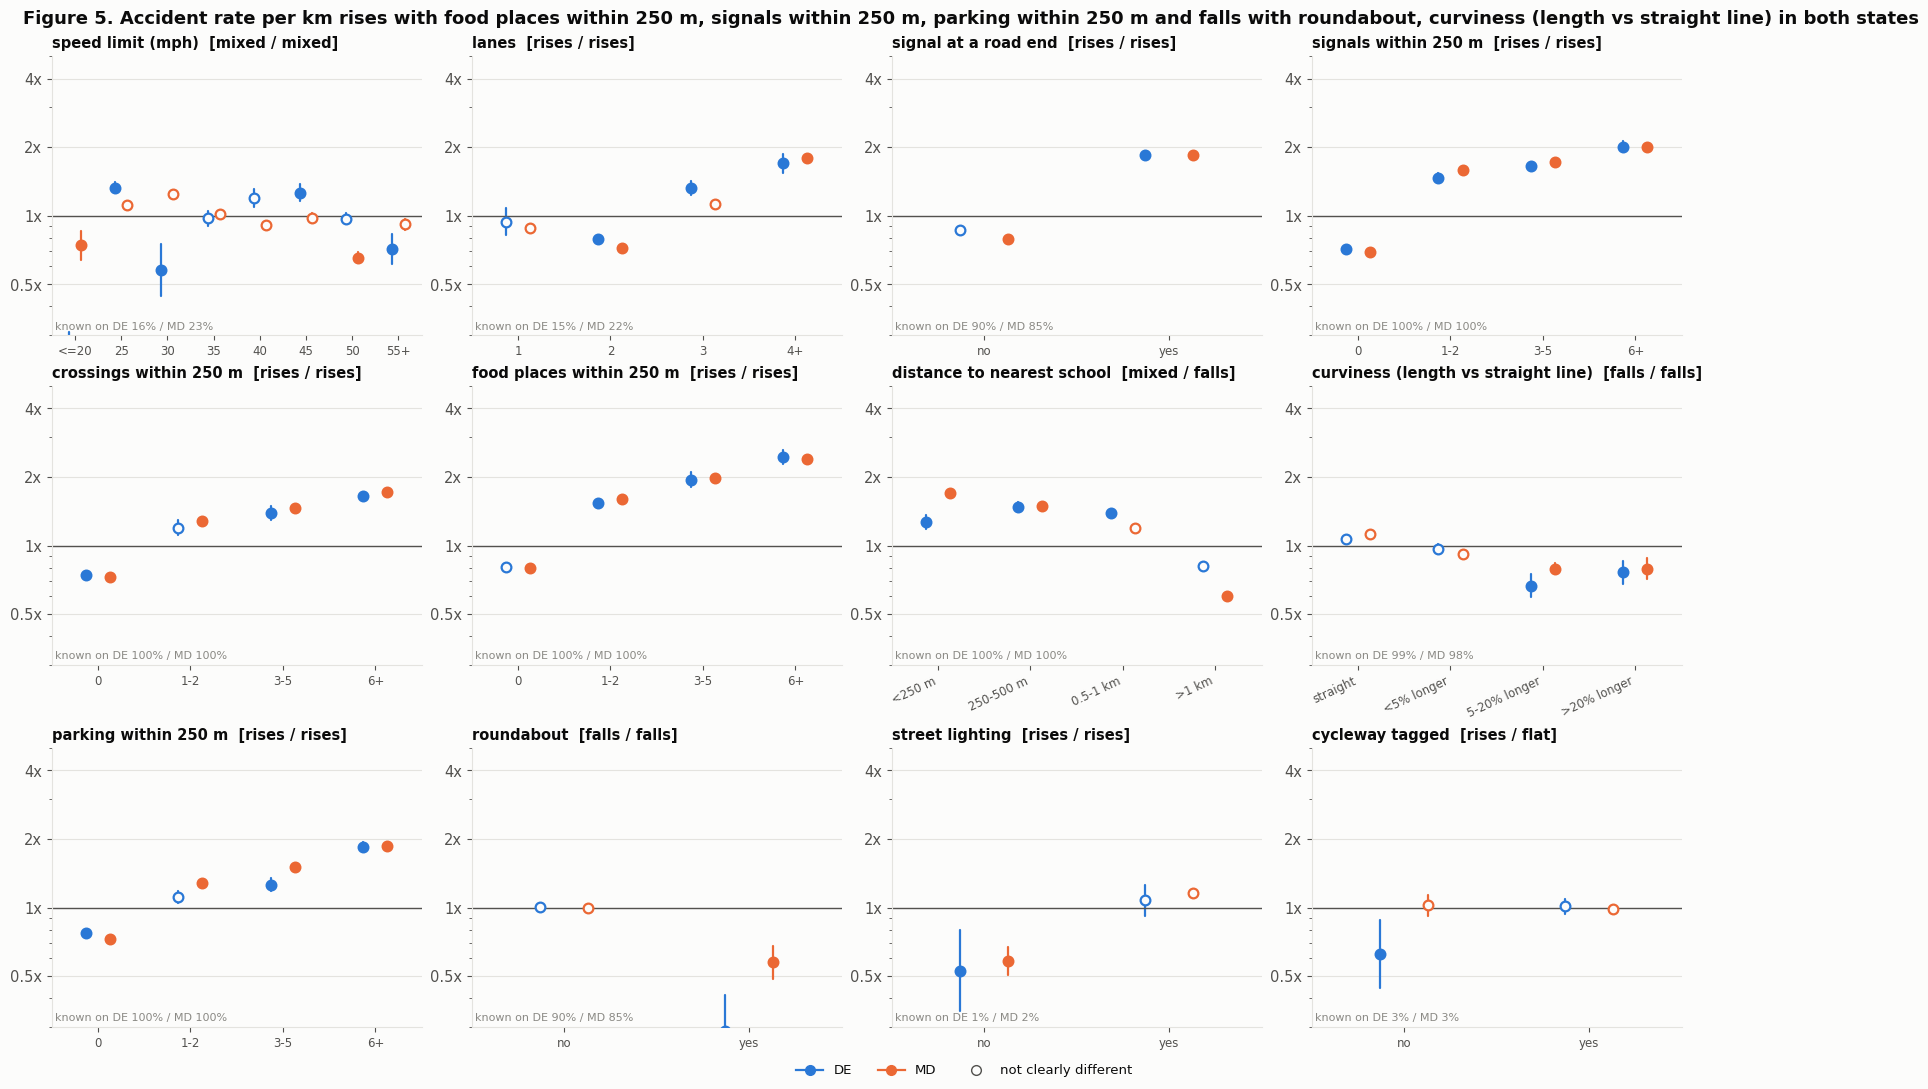

In [36]:
TREND_PANELS = ["speed_limit", "lanes", "signal_at_end", "signals_within_250m", "crossings_within_250m", "food_within_250m",
                "nearest_school", "sinuosity", "parking_within_250m", "roundabout", "lit", "cycleway"]


def trend_headline(analyses_window, panels):
    """A plain-language title from the data: the strongest trends that point the same way in both states."""
    states = list(analyses_window)
    rising, falling = [], []
    for variable in panels:
        trends = [analyses_window[s]["verdict"].get(("trend"), pd.Series(dtype=object)).get(variable) for s in states]
        if all(t == "rises" for t in trends):
            rising.append((variable, np.mean([np.log(analyses_window[s]["verdict"].loc[variable, "to_ratio"] / analyses_window[s]["verdict"].loc[variable, "from_ratio"]) for s in states])))
        elif all(t == "falls" for t in trends):
            falling.append((variable, np.mean([np.log(analyses_window[s]["verdict"].loc[variable, "to_ratio"] / analyses_window[s]["verdict"].loc[variable, "from_ratio"]) for s in states])))
    rising = [VARIABLE_LABELS[v] for v, _ in sorted(rising, key=lambda t: -abs(t[1]))[:3]]
    falling = [VARIABLE_LABELS[v] for v, _ in sorted(falling, key=lambda t: -abs(t[1]))[:3]]
    parts = []
    if rising:
        parts.append("rises with " + ", ".join(rising))
    if falling:
        parts.append("falls with " + ", ".join(falling))
    return "Accident rate per km " + " and ".join(parts) + " in both states" if parts else "Few feature trends point the same way in both states"


def plot_value_trends(analyses_window, panels, name, title_prefix):
    """Figure 5: small multiples of controlled rate ratio against feature value, both states."""
    apply_chart_style()
    states = list(analyses_window)

    def has_values(variable):   # drop panels where no state has any known value (an empty panel says nothing)
        return any(variable in analyses_window[s]["verdict"].index and analyses_window[s]["verdict"].loc[variable, "known_share_of_roads"] > 0 for s in states)
    dropped = [v for v in panels if not has_values(v)]
    panels = [v for v in panels if has_values(v)]
    if dropped:
        print("Not drawn (no known values in any state): " + ", ".join(VARIABLE_LABELS[v] for v in dropped))
    columns = 4
    rows = int(np.ceil(len(panels) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(4.2 * columns, 3.4 * rows + 0.6), layout="constrained")
    for ax, variable in zip(np.ravel(axes), panels):
        order = LEVEL_ORDER[variable]
        for offset, state in zip((-0.13, 0.13), states):
            table = analyses_window[state]["controlled"]
            rows_v = table[table["variable"] == variable].set_index("level")
            for position, level in enumerate(order):
                if level not in rows_v.index or rows_v.loc[level, "accidents"] < MIN_ACCIDENTS_FOR_VERDICT:
                    continue
                r = rows_v.loc[level]
                colour = STATE_COLORS[state]
                ax.plot([position + offset] * 2, [max(r["low_used"], 0.05), r["high_used"]], color=colour, lw=1.6, solid_capstyle="round")
                ax.plot(position + offset, r["ratio_used"], "o", ms=7, mfc=colour if r["differs"] else SURFACE, mec=colour, mew=1.6, zorder=3)
        ax.axhline(1, color=INK_SECONDARY, lw=1)
        ax.set_yscale("log")
        ax.set_yticks([0.5, 1, 2, 4]); ax.get_yaxis().set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}x")); ax.get_yaxis().set_minor_formatter(plt.NullFormatter())
        ax.set_ylim(0.3, 5)
        ax.set_xticks(range(len(order))); ax.set_xticklabels(order, fontsize=8.5, rotation=0 if max(len(o) for o in order) <= 4 else 25, ha="center" if max(len(o) for o in order) <= 4 else "right")
        ax.set_xlim(-0.5, len(order) - 0.5)
        ax.yaxis.grid(True)
        directions = [analyses_window[s]["verdict"].loc[variable, "trend"] if variable in analyses_window[s]["verdict"].index else "n/a" for s in states]
        known = " / ".join("{} {:.0%}".format(s, analyses_window[s]["verdict"].loc[variable, "known_share_of_roads"]) if variable in analyses_window[s]["verdict"].index else s + " n/a" for s in states)
        ax.set_title(VARIABLE_LABELS[variable] + "  [" + " / ".join(directions) + "]", fontsize=10.5)
        ax.text(0.01, 0.02, "known on " + known, transform=ax.transAxes, fontsize=8, color=INK_MUTED)
    for ax in np.ravel(axes)[len(panels):]:
        ax.axis("off")
    handles = [Line2D([], [], color=STATE_COLORS[s], marker="o", ms=7, lw=1.6, label=s) for s in states]
    handles.append(Line2D([], [], color=INK_SECONDARY, marker="o", ms=7, mfc=SURFACE, lw=0, label="not clearly different"))
    fig.legend(handles=handles, loc="outside lower center", ncol=3, fontsize=9.5)
    fig.suptitle(title_prefix + ". " + trend_headline(analyses_window, panels), x=0.01, ha="left", fontsize=13)
    save_figure(fig, name)
    plt.show()


headline_analyses = {s: analyses[s][HEADLINE] for s in STATES}
plot_value_trends(headline_analyses, TREND_PANELS, "fig5_value_trends", "Figure 5")

### 11.3 Figure 6: do speed limit and lanes matter *inside* a road type?
Pooling road types can hide or fake a trend (motorways have high limits and high rates for other reasons). Here the comparison is made inside each of the four road types with most accidents, controlling for length only.

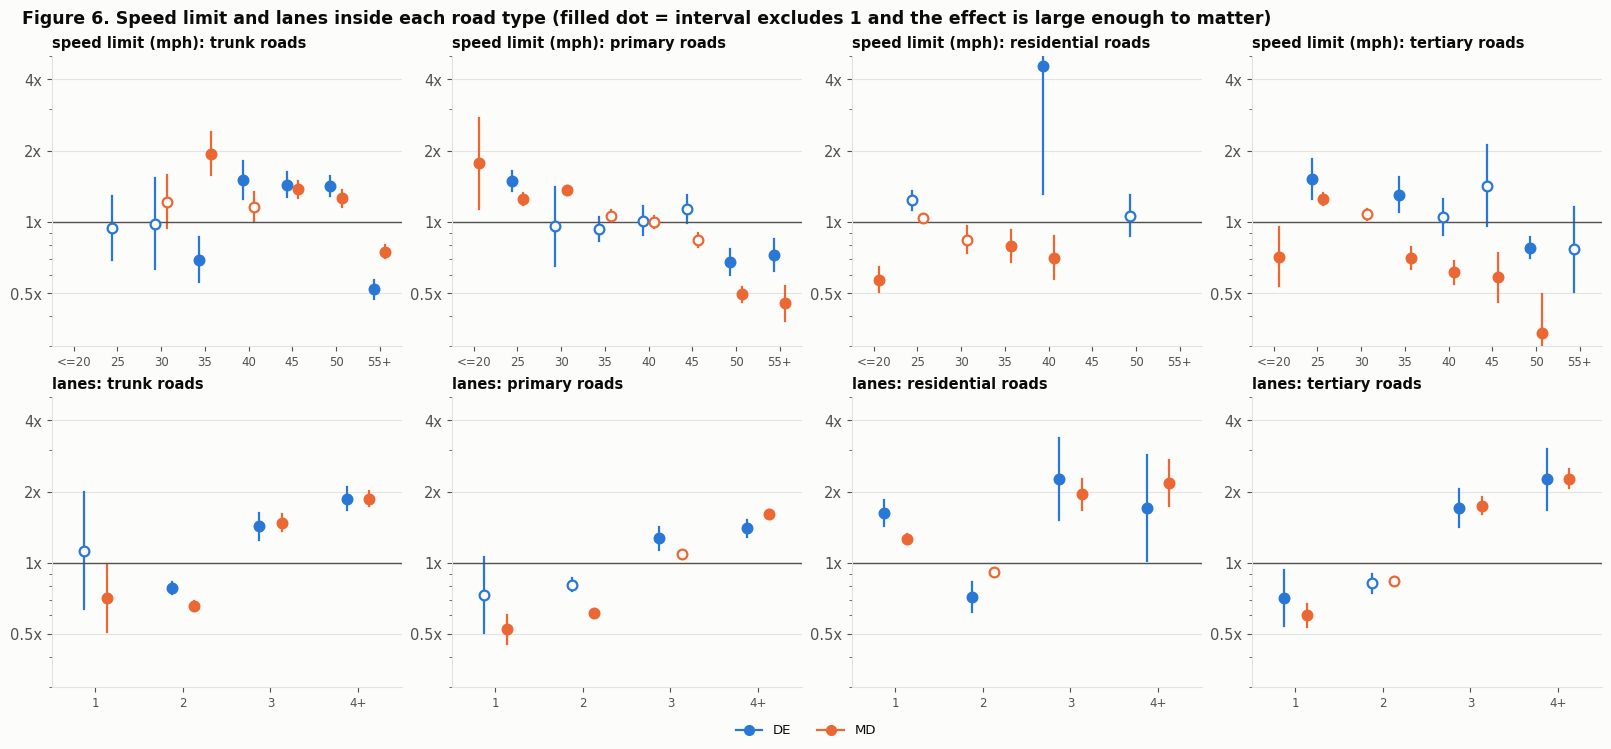

In [37]:
def plot_within_road_type(analyses_window, variables=("speed_limit", "lanes"), top_types=4, name="fig6_within_road_type"):
    """Figure 6: controlled ratio of `variables` by value, separately inside each of the main road types."""
    apply_chart_style()
    states = list(analyses_window)
    reference = analyses_window[states[0]]
    levels0 = reference["levels"]
    types = levels0.groupby("road_type")["accidents"].sum().sort_values(ascending=False).index[:top_types].tolist()
    fig, axes = plt.subplots(len(variables), len(types), figsize=(4.0 * len(types), 3.3 * len(variables) + 0.8), layout="constrained", squeeze=False)
    for row, variable in enumerate(variables):
        order = LEVEL_ORDER[variable]
        for column, road_type in enumerate(types):
            ax = axes[row, column]
            for offset, state in zip((-0.13, 0.13), states):
                levels, years = analyses_window[state]["levels"], analyses_window[state]["years"]
                subset = levels[levels["road_type"] == road_type]
                if subset[variable].nunique() < 2:
                    continue
                table = controlled_ratio_by_level(subset, variable, years, ["length"])
                for position, level in enumerate(order):
                    if level in table.index and table.loc[level, "observed"] >= MIN_ACCIDENTS_FOR_VERDICT:
                        r = table.loc[level]
                        clear = (r["ci_low"] > 1 or r["ci_high"] < 1) and (r["ratio"] > MIN_EFFECT_RATIO or r["ratio"] < 1 / MIN_EFFECT_RATIO)
                        ax.plot([position + offset] * 2, [max(r["ci_low"], 0.05), r["ci_high"]], color=STATE_COLORS[state], lw=1.6)
                        ax.plot(position + offset, r["ratio"], "o", ms=7, mfc=STATE_COLORS[state] if clear else SURFACE, mec=STATE_COLORS[state], mew=1.6, zorder=3)
            ax.axhline(1, color=INK_SECONDARY, lw=1)
            ax.set_yscale("log"); ax.set_ylim(0.3, 5)
            ax.set_yticks([0.5, 1, 2, 4]); ax.get_yaxis().set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}x")); ax.get_yaxis().set_minor_formatter(plt.NullFormatter())
            ax.set_xticks(range(len(order))); ax.set_xticklabels(order, fontsize=8.5); ax.set_xlim(-0.5, len(order) - 0.5)
            ax.yaxis.grid(True)
            ax.set_title(f"{VARIABLE_LABELS[variable]}: {road_type} roads", fontsize=10.5)
            if not ax.lines[1:]:   # nothing plotted besides the reference line
                ax.text(0.5, 0.55, "too few known values\nin this road type", transform=ax.transAxes, ha="center", va="center", fontsize=9.5, color=INK_MUTED)
    handles = [Line2D([], [], color=STATE_COLORS[s], marker="o", ms=7, lw=1.6, label=s) for s in states]
    fig.legend(handles=handles, loc="outside lower center", ncol=2, fontsize=9.5)
    fig.suptitle("Figure 6. Speed limit and lanes inside each road type (filled dot = interval excludes 1 and the effect is large enough to matter)", x=0.01, ha="left", fontsize=12.5)
    save_figure(fig, name)
    plt.show()


plot_within_road_type(headline_analyses)

### 11.4 The trends in words (generated from the tables above)

In [38]:
def trend_sentences(analyses_window, states):
    """One sentence per variable and state, from the verdict tables (no hand-typed numbers)."""
    lines = []
    for variable in list(FEATURE_GROUP_OF_VARIABLE):
        for state in states:
            verdict = analyses_window[state]["verdict"]
            if variable not in verdict.index:
                continue
            v = verdict.loc[variable]
            label = VARIABLE_LABELS[variable]
            known = f"(known on {pct(v['known_share_of_roads'], 0)} of roads, {pct(v['known_share_of_accidents'], 0)} of accidents)"
            if v["trend"] in ("rises", "falls"):
                lines.append((variable, state, f"**{label}, {state}**: the rate per km {v['trend']} with value, from {v['from_ratio']:.2f}x at {v['from_level']} to {v['to_ratio']:.2f}x at {v['to_level']} {known}."))
            elif v["trend"] in ("mixed", "unordered") and v["levels_that_differ"] > 0:
                lines.append((variable, state, f"**{label}, {state}**: levels differ without a steady direction; strongest is {v['strongest_level']} at {v['ratio']:.2f}x {known}."))
            elif v["trend"] in ("flat", "unordered", "mixed"):
                lines.append((variable, state, f"**{label}, {state}**: no level clearly differs from comparable roads {known}."))
    return lines


for state in STATES:
    sentences = [text for variable, s, text in trend_sentences(headline_analyses, STATES) if s == state]
    md(f"#### {state}\n\n" + "\n".join("* " + t for t in sentences))

#### DE

* **speed limit (mph), DE**: levels differ without a steady direction; strongest is <=20 at 0.20x (known on 16% of roads, 45% of accidents).
* **lanes, DE**: the rate per km rises with value, from 0.94x at 1 to 1.70x at 4+ (known on 15% of roads, 50% of accidents).
* **surface, DE**: levels differ without a steady direction; strongest is paved at 0.56x (known on 18% of roads, 27% of accidents).
* **on a bridge, DE**: no level clearly differs from comparable roads (known on 90% of roads, 85% of accidents).
* **signal at a road end, DE**: the rate per km rises with value, from 0.87x at no to 1.85x at yes (known on 90% of roads, 85% of accidents).
* **stop sign at a road end, DE**: the rate per km rises with value, from 0.99x at no to 1.68x at yes (known on 90% of roads, 85% of accidents).
* **crossing at a road end, DE**: no level clearly differs from comparable roads (known on 90% of roads, 85% of accidents).
* **roundabout, DE**: the rate per km falls with value, from 1.00x at no to 0.29x at yes (known on 90% of roads, 85% of accidents).
* **signals mid-block, DE**: the rate per km rises with value, from 0.96x at 0 to 3.41x at 2+ (known on 90% of roads, 85% of accidents).
* **stop signs mid-block, DE**: the rate per km falls with value, from 1.01x at 0 to 0.57x at 2+ (known on 90% of roads, 85% of accidents).
* **crossings mid-block, DE**: the rate per km rises with value, from 0.89x at 0 to 2.63x at 2+ (known on 90% of roads, 85% of accidents).
* **traffic calming mid-block, DE**: no level clearly differs from comparable roads (known on 90% of roads, 85% of accidents).
* **cycleway tagged, DE**: the rate per km rises with value, from 0.63x at no to 1.01x at yes (known on 3% of roads, 9% of accidents).
* **sidewalk tagged, DE**: the rate per km rises with value, from 0.76x at no to 1.22x at yes (known on 2% of roads, 2% of accidents).
* **street lighting, DE**: the rate per km rises with value, from 0.53x at no to 1.08x at yes (known on 1% of roads, 2% of accidents).
* **crossings within 250 m, DE**: the rate per km rises with value, from 0.75x at 0 to 1.65x at 6+ (known on 100% of roads, 100% of accidents).
* **parking within 250 m, DE**: the rate per km rises with value, from 0.77x at 0 to 1.85x at 6+ (known on 100% of roads, 100% of accidents).
* **food places within 250 m, DE**: the rate per km rises with value, from 0.80x at 0 to 2.45x at 6+ (known on 100% of roads, 100% of accidents).
* **signals within 250 m, DE**: the rate per km rises with value, from 0.71x at 0 to 2.01x at 6+ (known on 100% of roads, 100% of accidents).
* **distance to nearest school, DE**: levels differ without a steady direction; strongest is 250-500 m at 1.48x (known on 100% of roads, 100% of accidents).
* **curviness (length vs straight line), DE**: the rate per km falls with value, from 1.07x at straight to 0.76x at >20% longer (known on 99% of roads, 100% of accidents).

#### MD

* **speed limit (mph), MD**: levels differ without a steady direction; strongest is 50 at 0.66x (known on 23% of roads, 60% of accidents).
* **lanes, MD**: the rate per km rises with value, from 0.88x at 1 to 1.79x at 4+ (known on 22% of roads, 66% of accidents).
* **surface, MD**: levels differ without a steady direction; strongest is unpaved at 0.13x (known on 34% of roads, 65% of accidents).
* **on a bridge, MD**: no level clearly differs from comparable roads (known on 85% of roads, 89% of accidents).
* **signal at a road end, MD**: the rate per km rises with value, from 0.79x at no to 1.84x at yes (known on 85% of roads, 89% of accidents).
* **stop sign at a road end, MD**: the rate per km rises with value, from 0.99x at no to 1.93x at yes (known on 85% of roads, 89% of accidents).
* **crossing at a road end, MD**: the rate per km rises with value, from 1.00x at no to 1.75x at yes (known on 85% of roads, 89% of accidents).
* **roundabout, MD**: the rate per km falls with value, from 1.00x at no to 0.57x at yes (known on 85% of roads, 89% of accidents).
* **signals mid-block, MD**: the rate per km rises with value, from 0.97x at 0 to 4.18x at 2+ (known on 85% of roads, 89% of accidents).
* **stop signs mid-block, MD**: the rate per km rises with value, from 0.99x at 0 to 1.74x at 2+ (known on 85% of roads, 89% of accidents).
* **crossings mid-block, MD**: the rate per km rises with value, from 0.85x at 0 to 2.45x at 2+ (known on 85% of roads, 89% of accidents).
* **traffic calming mid-block, MD**: the rate per km rises with value, from 0.99x at 0 to 1.95x at 2+ (known on 85% of roads, 89% of accidents).
* **cycleway tagged, MD**: no level clearly differs from comparable roads (known on 3% of roads, 11% of accidents).
* **sidewalk tagged, MD**: the rate per km rises with value, from 0.72x at no to 1.43x at yes (known on 4% of roads, 5% of accidents).
* **street lighting, MD**: the rate per km rises with value, from 0.58x at no to 1.15x at yes (known on 2% of roads, 6% of accidents).
* **crossings within 250 m, MD**: the rate per km rises with value, from 0.73x at 0 to 1.72x at 6+ (known on 100% of roads, 100% of accidents).
* **parking within 250 m, MD**: the rate per km rises with value, from 0.73x at 0 to 1.86x at 6+ (known on 100% of roads, 100% of accidents).
* **food places within 250 m, MD**: the rate per km rises with value, from 0.80x at 0 to 2.39x at 6+ (known on 100% of roads, 100% of accidents).
* **signals within 250 m, MD**: the rate per km rises with value, from 0.69x at 0 to 2.00x at 6+ (known on 100% of roads, 100% of accidents).
* **distance to nearest school, MD**: the rate per km falls with value, from 1.71x at <250 m to 0.60x at >1 km (known on 100% of roads, 100% of accidents).
* **curviness (length vs straight line), MD**: the rate per km falls with value, from 1.13x at straight to 0.79x at >20% longer (known on 98% of roads, 100% of accidents).

## 12. All features together, and do the findings hold elsewhere?
Features overlap (a road with a signal tends to be near food places and crossings), so one-at-a-time ratios can double-count.
Two further checks:

1. **Joint model.** One Poisson regression with all features at once, controlling for road length and road type (offset = log of km-years, so each coefficient is a ratio of accident rates per km; robust HC1 errors).
   Dense features (nearby places, shape, node flags) go in one model on all matched roads. Each **sparse tag** (speed limit, lanes, surface, cycleway, sidewalk, lighting) gets its own model **on the roads where it is known**, with a small fixed set of controls.
   Putting sparse tags in the same model would force a choice between dropping almost every road and inventing an "untagged" level, which is the artefact we removed in Section 11.
   Each variable uses the **same reference level in both states and both windows** (the level most common across them), so ratios are directly comparable.
2. **Stability.** Does a finding keep its direction (a) in the other state and (b) when the paper's training years replace the full period? A finding that fails either is not reported as a finding.

> **Alternative considered.** One model with "untagged" as a level: rejected (Section 11). Per-state random effects or clustering by neighbourhood: better for the intervals, not done here (see limitations).

In [39]:
DENSE_MODEL_FEATURES = ["bridge", "signal_at_end", "stop_at_end", "crossing_at_end", "roundabout", "signal_midblock", "stop_midblock",
                        "crossing_midblock", "calming_midblock", "crossings_within_250m", "parking_within_250m", "food_within_250m",
                        "signals_within_250m", "nearest_school", "sinuosity"]
TAG_MODEL_FEATURES = ["speed_limit", "lanes", "surface", "cycleway", "sidewalk", "lit"]
TAG_MODEL_CONTROLS = ["signals_within_250m"]   # added to length and road type in each tag model


def common_references(levels_list, variables):
    """For each variable, the level that is most common across all the given tables (known values only)."""
    references = {}
    for variable in variables:
        parts = [levels[variable].value_counts() for levels in levels_list if variable in levels.columns]
        if parts:
            counts = pd.concat(parts).groupby(level=0).sum()
            if len(counts):
                references[variable] = counts.idxmax()
    return references


NOT_ESTIMABLE_INTERVAL_WIDTH = 1000   # upper/lower ends of the 95% interval further apart than this: no usable estimate


def fit_rate_model(levels, n_years, features, references, model_name):
    """One Poisson model of accident counts on the given features plus road length and road type; rows with any missing value are dropped.

    Returns one row per variable level: roads, accidents, rate_ratio against the reference level, 95% interval, p_value, `estimable` (False when the interval is absurdly wide, e.g. a level fully explained by another feature; its estimates are NaN), `clear` (at least
    MIN_ACCIDENTS_FOR_VERDICT accidents, interval excludes 1, and ratio outside 1/MIN_EFFECT_RATIO .. MIN_EFFECT_RATIO), `is_control` and `model`. The table's `.attrs` hold the number of roads and accidents used.
    """
    import statsmodels.api as sm
    import statsmodels.formula.api as smf

    needed = ["length", "road_type"] + list(features)
    data = levels.dropna(subset=needed).copy()
    type_counts = data["road_type"].map(data["road_type"].value_counts())
    data["road_type"] = data["road_type"].where(type_counts >= MIN_ROADS_FOR_ROAD_TYPE, "rare_type")
    km_years = data["length_m"] / 1000 * n_years

    variables = [v for v in needed if data[v].nunique() >= 2]
    reference = {v: (references.get(v) if references.get(v) in set(data[v].unique()) else data[v].value_counts().idxmax()) for v in variables}
    terms = [f"C({v}, Treatment(reference='{reference[v]}'))" for v in variables]
    fit = smf.glm("accidents ~ " + " + ".join(terms), data=data, family=sm.families.Poisson(), offset=np.log(km_years)).fit(cov_type="HC1")

    interval = fit.conf_int()
    rows = []
    for name in fit.params.index:
        match = re.match(r"C\((\w+), Treatment\(reference='(.*?)'\)\)\[T\.(.*)\]$", name)
        if match is None:  # the intercept
            continue
        variable, level = match.group(1), match.group(3)
        rows.append({"variable": variable, "level": level, "reference": match.group(2), "roads": int((data[variable] == level).sum()),
                     "accidents": float(data.loc[data[variable] == level, "accidents"].sum()),
                     "rate_ratio": np.exp(fit.params[name]), "ci_low": np.exp(interval.loc[name, 0]), "ci_high": np.exp(interval.loc[name, 1]),
                     "p_value": fit.pvalues[name], "is_control": variable in ("length", "road_type"), "model": model_name})
    result = pd.DataFrame(rows)
    # A level that is almost perfectly explained by another feature (e.g. every 55 mph road is a motorway) has no usable estimate: the model
    # returns an interval from 0 to infinity. Report those as not estimable (NaN) instead of printing a meaningless number.
    width = result["ci_high"] / result["ci_low"].replace(0, np.nan)
    result["estimable"] = np.isfinite(width) & (width < NOT_ESTIMABLE_INTERVAL_WIDTH)
    result.loc[~result["estimable"], ["rate_ratio", "ci_low", "ci_high", "p_value"]] = np.nan
    result["clear"] = ((result["accidents"] >= MIN_ACCIDENTS_FOR_VERDICT) & ((result["ci_low"] > 1) | (result["ci_high"] < 1))
                       & ((result["rate_ratio"] > MIN_EFFECT_RATIO) | (result["rate_ratio"] < 1 / MIN_EFFECT_RATIO)))
    result.attrs.update({"n_roads": int(len(data)), "n_accidents": float(data["accidents"].sum())})
    return result


def fit_all_models(levels, n_years, references):
    """The dense joint model plus one model per sparse tag (each on the roads where the tag is known). Tag models keep only their own tag's rows."""
    parts = [fit_rate_model(levels, n_years, DENSE_MODEL_FEATURES, references, "dense")]
    sizes = {"dense": (parts[0].attrs["n_roads"], parts[0].attrs["n_accidents"])}
    for tag in TAG_MODEL_FEATURES:
        if levels[tag].notna().sum() < 500 or levels.loc[levels[tag].notna(), tag].nunique() < 2:
            continue
        try:
            table = fit_rate_model(levels, n_years, [tag] + TAG_MODEL_CONTROLS, references, f"tag: {tag}")
        except Exception as error:   # a very small or degenerate subset can fail to fit; say so rather than stopping
            print(f"  tag model for {tag} could not be fitted ({type(error).__name__}: {error})")
            continue
        sizes[tag] = (table.attrs["n_roads"], table.attrs["n_accidents"])
        parts.append(table[table["variable"] == tag])
    result = pd.concat(parts, ignore_index=True)
    result.attrs["model_sizes"] = sizes
    return result

def compare_joint_models(joint_a, joint_b, name_a, name_b):
    """Put two states' joint-model results side by side to see which findings replicate.

    Rate ratios are only comparable when both models used the same reference level for the variable (the most common
    level can differ between states), so rows with different references are marked and left out of the counts.

    Takes: two tables from `fit_joint_rate_model` and the names to label them.
    Returns: one row per variable level with both rate ratios, `same_direction` (both above 1 or both below 1) and
    `clear_in_both`. Prints how many of the levels that are clear in the first state also hold in the second.
    """
    merged = joint_a.merge(joint_b, on=["variable", "level"], suffixes=(f"_{name_a}", f"_{name_b}"))
    merged["same_reference"] = merged[f"reference_{name_a}"] == merged[f"reference_{name_b}"]
    ratio_a, ratio_b = merged[f"rate_ratio_{name_a}"], merged[f"rate_ratio_{name_b}"]
    merged["same_direction"] = (ratio_a - 1) * (ratio_b - 1) > 0
    merged["clear_in_both"] = merged[f"clear_{name_a}"] & merged[f"clear_{name_b}"]

    comparable = merged[merged["same_reference"]]
    clear_a = comparable[comparable[f"clear_{name_a}"]]
    print(f"levels compared: {len(comparable)} ({len(merged) - len(comparable)} skipped: different reference level)")
    print(f"clear in {name_a}: {len(clear_a)}; same direction in {name_b}: {int(clear_a['same_direction'].sum())}; "
          f"also clear in {name_b}: {int(clear_a['clear_in_both'].sum())}")
    columns = ["variable", "level", f"reference_{name_a}", f"rate_ratio_{name_a}", f"rate_ratio_{name_b}",
               f"clear_{name_a}", f"clear_{name_b}", "same_direction", "same_reference"]
    return merged[columns]

In [40]:
FIT_VARIABLES = ["length", "road_type"] + DENSE_MODEL_FEATURES + TAG_MODEL_FEATURES
models, references = {state: {} for state in STATES}, {}
# one set of reference levels for all states and windows, so ratios are comparable everywhere
references = common_references([analyses[s][w]["levels"] for s in STATES for w in ("train", "full")], FIT_VARIABLES)
for state in STATES:
    for window in ("train", "full"):
        started = time.time()
        models[state][window] = fit_all_models(analyses[state][window]["levels"], analyses[state][window]["years"], references)
        sizes = models[state][window].attrs["model_sizes"]
        print(f"{state} {window}: {len(models[state][window])} effects; dense model on {sizes['dense'][0]:,} roads; "
              f"tag models on " + ", ".join(f"{k} {v[0]:,}" for k, v in sizes.items() if k != "dense") + f" ({time.time() - started:.0f} s)")

DE train: 59 effects; dense model on 55,870 roads; tag models on speed_limit 10,321, lanes 9,714, surface 11,374, cycleway 1,810, sidewalk 1,044 (15 s)
DE full: 59 effects; dense model on 55,870 roads; tag models on speed_limit 10,321, lanes 9,714, surface 11,374, cycleway 1,810, sidewalk 1,044 (9 s)
MD train: 60 effects; dense model on 257,982 roads; tag models on speed_limit 69,713, lanes 66,796, surface 105,411, cycleway 10,449, sidewalk 11,159, lit 6,924 (45 s)
MD full: 60 effects; dense model on 257,982 roads; tag models on speed_limit 69,713, lanes 66,796, surface 105,411, cycleway 10,449, sidewalk 11,159, lit 6,924 (43 s)


### 12.1 Figure 7: effect of each feature, grouped, both states
Each row is one feature level compared with its reference level, **other features held fixed**. Filled dot: clearly different (interval excludes 1 and ratio outside 0.8 to 1.25). A tick on the right marks levels that are clear **and in the same direction in both states**.
Only levels that are clear in at least one state are drawn; all of them are in the tables saved in Section 13.

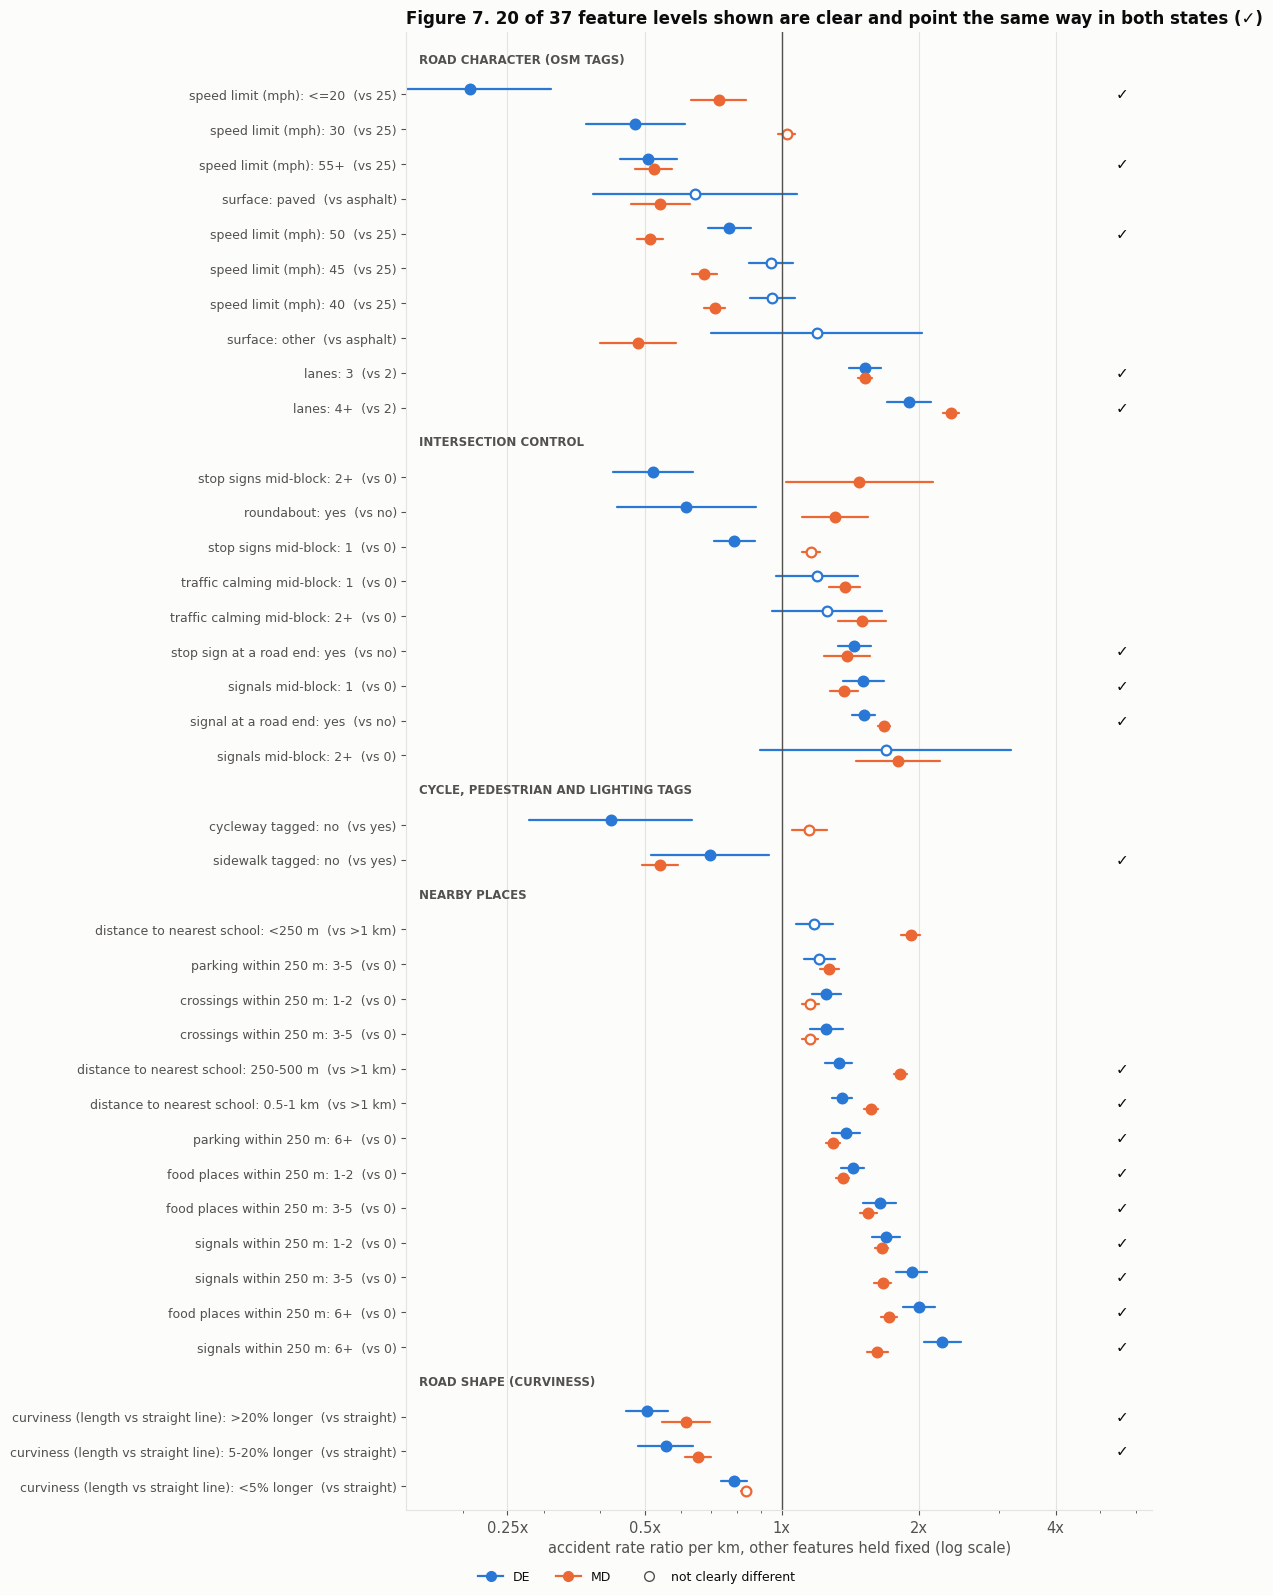

In [41]:
def effect_table(models_window, first, second):
    """Both states' effects side by side for feature levels (not controls) with the same reference level."""
    tables = {s: models_window[s].query("not is_control").set_index(["variable", "level"]) for s in (first, second)}
    both = tables[first].join(tables[second], how="inner", lsuffix=f"_{first}", rsuffix=f"_{second}")
    both = both[both[f"reference_{first}"] == both[f"reference_{second}"]].copy()
    both["group"] = [FEATURE_GROUP_OF_VARIABLE.get(v, "?") for v, _ in both.index]
    both["same_direction"] = (both[f"rate_ratio_{first}"] - 1) * (both[f"rate_ratio_{second}"] - 1) > 0
    both["replicates"] = both[f"clear_{first}"] & both[f"clear_{second}"] & both["same_direction"]
    return both


def plot_effect_summary(models_window, first, second, max_rows=40):
    """Figure 7: grouped forest plot of feature effects in both states."""
    apply_chart_style()
    both = effect_table(models_window, first, second)
    both = both[both[f"clear_{first}"] | both[f"clear_{second}"]]
    both = both.assign(order=both["group"], sort=both[f"rate_ratio_{first}"]).sort_values(["order", "sort"])
    if len(both) > max_rows:   # keep the strongest if there are very many
        strength = np.abs(np.log(both[[f"rate_ratio_{first}", f"rate_ratio_{second}"]])).max(axis=1)
        both = both.loc[strength.sort_values(ascending=False).index[:max_rows]].sort_values(["order", "sort"])
    n_rows = len(both) + both["group"].nunique()
    fig, ax = plt.subplots(figsize=(11.5, 0.33 * n_rows + 2.0), layout="constrained")
    y, ticks, labels, current = 0, [], [], None
    for (variable, level), line in both.iterrows():
        if line["group"] != current:
            current = line["group"]
            ax.text(0.16, y, FEATURE_GROUP_NAMES.get(current, current).upper(), fontsize=8.5, fontweight="bold", color=INK_SECONDARY, va="center")
            y += 1
        for offset, state in zip((-0.15, 0.15), (first, second)):
            ratio, low, high = line[f"rate_ratio_{state}"], line[f"ci_low_{state}"], line[f"ci_high_{state}"]
            colour, filled = STATE_COLORS[state], line[f"clear_{state}"]
            ax.plot([low, high], [y + offset] * 2, color=colour, lw=1.6, solid_capstyle="round")
            ax.plot(ratio, y + offset, "o", ms=7, mfc=colour if filled else SURFACE, mec=colour, mew=1.6)
        if line["replicates"]:
            ax.text(5.6, y, "✓", fontsize=11, color=INK, va="center", ha="center")
        ticks.append(y); labels.append(f"{VARIABLE_LABELS.get(variable, variable)}: {level}  (vs {line[f'reference_{first}']})")
        y += 1
    ax.axvline(1, color=INK_SECONDARY, lw=1)
    ax.set_xscale("log"); ax.set_xlim(0.15, 6.5)
    ax.set_xticks([0.25, 0.5, 1, 2, 4]); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}x")); ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_yticks(ticks); ax.set_yticklabels(labels, fontsize=9); ax.set_ylim(y - 0.3, -0.8)
    ax.xaxis.grid(True)
    ax.set_xlabel("accident rate ratio per km, other features held fixed (log scale)")
    n_rep = int(both["replicates"].sum())
    ax.set_title(f"Figure 7. {n_rep} of {len(both)} feature levels shown are clear and point the same way in both states (✓)")
    handles = [Line2D([], [], color=STATE_COLORS[s], marker="o", ms=7, lw=1.6, label=s) for s in (first, second)]
    handles.append(Line2D([], [], color=INK_SECONDARY, marker="o", ms=7, mfc=SURFACE, lw=0, label="not clearly different"))
    fig.legend(handles=handles, loc="outside lower center", ncol=3, fontsize=9)
    save_figure(fig, "fig7_effect_summary")
    plt.show()
    return both


first, second = STATES[0], STATES[1]
effects_shown = plot_effect_summary({s: models[s][HEADLINE] for s in STATES}, first, second)

### 12.2 Figure 8: do the findings hold in the other state, and in the other time window?
Each dot is a feature level. **Left:** its rate ratio in one state against the other (full period). **Right:** the paper's training years against the full period, within each state.
Dots near the dashed diagonal agree. Black dots are clear in both and point the same way; labelled dots are clear somewhere and point **opposite ways**.

levels compared: 46 (0 skipped: different reference level)
clear in DE: 28; same direction in MD: 23; also clear in MD: 22
levels compared: 47 (0 skipped: different reference level)
clear in train: 26; same direction in full: 26; also clear in full: 23
levels compared: 48 (0 skipped: different reference level)
clear in train: 34; same direction in full: 34; also clear in full: 32


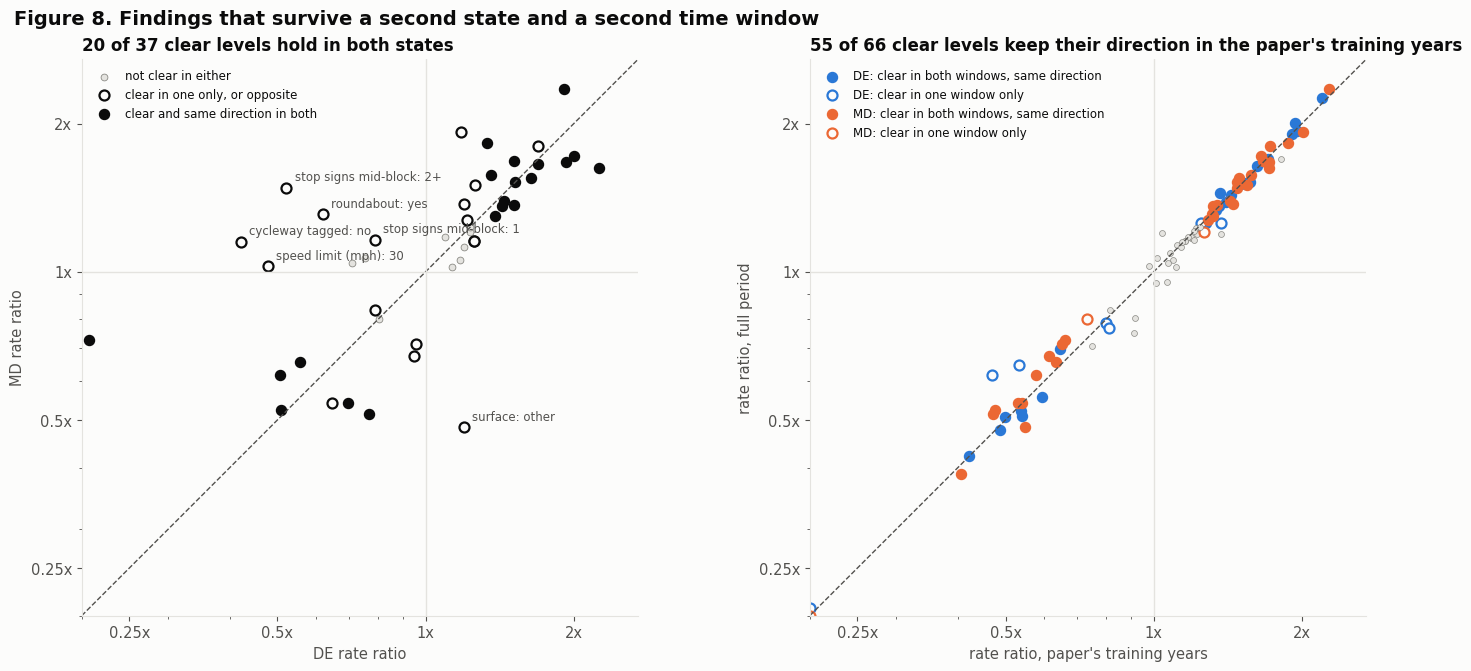

In [42]:
def plot_stability(rep_states, rep_windows, first, second):
    """Figure 8: cross-state agreement (left) and training-years-vs-full-period agreement (right). Returns the two tables used."""
    apply_chart_style()
    fig, (ax_state, ax_window) = plt.subplots(1, 2, figsize=(14.5, 6.6), layout="constrained")

    def prepare(table, a, b):
        table = table[table["same_reference"] & ~table["variable"].isin(["length", "road_type"])].copy()
        table["either_clear"] = table[f"clear_{a}"] | table[f"clear_{b}"]
        table["replicated"] = table[f"clear_{a}"] & table[f"clear_{b}"] & table["same_direction"]
        table["opposite"] = table["either_clear"] & ~table["same_direction"]
        return table

    def axis_limits(*series, floor=0.2, ceiling=5.0):
        values = pd.concat(series)
        return max(floor, values.min() / 1.15), min(ceiling, values.max() * 1.15)

    def scatter(ax, table, a, b, colour):
        x, y = table[f"rate_ratio_{a}"], table[f"rate_ratio_{b}"]
        low, high = axis_limits(x, y)
        x, y = x.clip(low, high), y.clip(low, high)   # an extreme level is drawn on the frame instead of stretching the axes
        ax.plot([low, high], [low, high], color=INK_SECONDARY, lw=1, ls="--")
        ax.axhline(1, color=GRID_COLOR, lw=1); ax.axvline(1, color=GRID_COLOR, lw=1)
        none = ~table["either_clear"]
        ax.scatter(x[none], y[none], s=24, color=GRID_COLOR, edgecolor=INK_MUTED, linewidth=0.6, label="not clear in either")
        some = table["either_clear"] & ~table["replicated"]
        ax.scatter(x[some], y[some], s=52, facecolor=SURFACE, edgecolor=colour, linewidth=1.6, label="clear in one only, or opposite")
        ax.scatter(x[table["replicated"]], y[table["replicated"]], s=52, color=colour, label="clear and same direction in both")
        for _, line in table[table["opposite"]].iterrows():
            ax.annotate(f"{VARIABLE_LABELS.get(line['variable'], line['variable'])}: {line['level']}", (line[f"rate_ratio_{a}"], line[f"rate_ratio_{b}"]),
                        xytext=(6, 5), textcoords="offset points", fontsize=8.5, color=INK_SECONDARY)
        ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(low, high); ax.set_ylim(low, high)
        ticks = [t for t in (0.25, 0.5, 1, 2, 4) if low <= t <= high]
        for axis in (ax.xaxis, ax.yaxis):
            axis.set_major_locator(plt.FixedLocator(ticks)); axis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}x")); axis.set_minor_formatter(plt.NullFormatter())
        ax.set_aspect("equal")

    across_states = prepare(rep_states, first, second)
    scatter(ax_state, across_states, first, second, INK)
    ax_state.set_xlabel(f"{first} rate ratio"); ax_state.set_ylabel(f"{second} rate ratio")
    ax_state.legend(loc="upper left", fontsize=8.5)
    n1 = int(across_states["either_clear"].sum())
    ax_state.set_title(f"{int(across_states['replicated'].sum())} of {n1} clear levels hold in both states")

    # right: training vs full period, both states in their own colour
    parts = []
    for state, table in rep_windows.items():
        prepared = prepare(table, "train", "full")
        prepared["state"] = state
        parts.append(prepared)
        prepared = prepared.assign(rate_ratio_train=prepared["rate_ratio_train"].clip(0.2, 5.0), rate_ratio_full=prepared["rate_ratio_full"].clip(0.2, 5.0))
        parts[-1] = prepared
        ax_window.scatter(prepared[prepared["replicated"]]["rate_ratio_train"], prepared[prepared["replicated"]]["rate_ratio_full"], s=52, color=STATE_COLORS[state], label=f"{state}: clear in both windows, same direction")
        some = prepared["either_clear"] & ~prepared["replicated"]
        ax_window.scatter(prepared[some]["rate_ratio_train"], prepared[some]["rate_ratio_full"], s=52, facecolor=SURFACE, edgecolor=STATE_COLORS[state], linewidth=1.6, label=f"{state}: clear in one window only")
        ax_window.scatter(prepared[~prepared["either_clear"]]["rate_ratio_train"], prepared[~prepared["either_clear"]]["rate_ratio_full"], s=18, color=GRID_COLOR, edgecolor=INK_MUTED, linewidth=0.5)
    window_table = pd.concat(parts)
    low, high = axis_limits(window_table["rate_ratio_train"], window_table["rate_ratio_full"])
    ax_window.plot([low, high], [low, high], color=INK_SECONDARY, lw=1, ls="--")
    ax_window.axhline(1, color=GRID_COLOR, lw=1); ax_window.axvline(1, color=GRID_COLOR, lw=1)
    ax_window.set_xscale("log"); ax_window.set_yscale("log"); ax_window.set_xlim(low, high); ax_window.set_ylim(low, high)
    ticks = [t for t in (0.25, 0.5, 1, 2, 4) if low <= t <= high]
    for axis in (ax_window.xaxis, ax_window.yaxis):
        axis.set_major_locator(plt.FixedLocator(ticks)); axis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}x")); axis.set_minor_formatter(plt.NullFormatter())
    ax_window.set_aspect("equal")
    ax_window.set_xlabel("rate ratio, paper's training years"); ax_window.set_ylabel("rate ratio, full period")
    ax_window.legend(loc="upper left", fontsize=8.5)
    n2 = int(window_table["either_clear"].sum())
    ax_window.set_title(f"{int(window_table['replicated'].sum())} of {n2} clear levels keep their direction in the paper's training years")
    fig.suptitle("Figure 8. Findings that survive a second state and a second time window", x=0.01, ha="left")
    save_figure(fig, "fig8_stability")
    plt.show()
    return across_states, window_table


replication_states = compare_joint_models(models[first][HEADLINE].query("not is_control"), models[second][HEADLINE].query("not is_control"), first, second)
replication_windows = {state: compare_joint_models(models[state]["train"].query("not is_control"), models[state]["full"].query("not is_control"), "train", "full") for state in STATES}
stability_states, stability_windows = plot_stability(replication_states, replication_windows, first, second)

### 12.3 Summary by feature group
How many feature levels were tested in each group, how many are clear in each state, and how many hold in both states **and** in the paper's training years.

In [43]:
def summarise_feature_groups(models_window, stability_states, stability_windows, first, second):
    """One row per feature group: levels tested, clear in each state, clear in both with the same direction, and also stable in the paper's training years."""
    rows = {}
    for state in (first, second):
        table = models_window[state].query("not is_control")
        table = table[table["variable"].isin(FEATURE_GROUP_OF_VARIABLE)].assign(group=lambda t: t["variable"].map(FEATURE_GROUP_OF_VARIABLE))
        rows[f"levels_tested_{state}"] = table.groupby("group").size()
        rows[f"clear_{state}"] = table.groupby("group")["clear"].sum()
    both = stability_states[stability_states["variable"].isin(FEATURE_GROUP_OF_VARIABLE)].copy()
    both["group"] = both["variable"].map(FEATURE_GROUP_OF_VARIABLE)
    rows["clear_in_both_states"] = both["replicated"].groupby(both["group"]).sum()
    stable = set()
    for state, table in stability_windows.groupby("state"):
        stable |= {(state, v, l) for v, l, r in zip(table["variable"], table["level"], table["replicated"]) if r}
    both["stable_over_time"] = [all(((s, v, l) in stable) for s in (first, second)) for v, l in zip(both["variable"], both["level"])]
    rows["also_hold_in_training_years"] = (both["replicated"] & both["stable_over_time"]).groupby(both["group"]).sum()
    summary = pd.DataFrame(rows).fillna(0).astype(int)
    summary.insert(0, "what", [FEATURE_GROUP_NAMES[g] for g in summary.index])
    return summary


group_summary = summarise_feature_groups({s: models[s][HEADLINE] for s in STATES}, stability_states, stability_windows, first, second)
md(df_to_markdown(group_summary))

| group | what | levels_tested_DE | clear_DE | levels_tested_MD | clear_MD | clear_in_both_states | also_hold_in_training_years |
|---|---|---|---|---|---|---|---|
| g1 | road character (OSM tags) | 15 | 6 | 15 | 10 | 5 | 3 |
| g2 | intersection control | 12 | 6 | 12 | 8 | 3 | 3 |
| g3 | cycle, pedestrian and lighting tags | 2 | 2 | 3 | 2 | 1 | 1 |
| g4 | nearby places | 15 | 11 | 15 | 11 | 9 | 9 |
| g5 | road shape (curviness) | 3 | 3 | 3 | 2 | 2 | 2 |

## 13. Hand-off for the modelling code
What the person building the models receives, and how to use it:

1. **`{STATE}_osm_model_features.parquet`**: one row per directed road, in the dataset's adjacency order (`node_1_idx`, `node_2_idx` are the keys). Raw features, unscaled, missing kept as NaN, plus `*_filled` and `*_is_est` for the three gap-filled tags.
2. **`{STATE}_osm_model_features_meta.json`**: feature-group definitions for ablations, a written preprocessing recipe, gate decisions, thresholds, versions.
3. **`osm_data_dictionary.csv`**: every column with group, meaning, unit, missing-value rule and fill rate in each state.
4. Result tables (`osm_value_trends_*`, `osm_effects_*`, `osm_gap_filling_validation.csv`) for the report.
5. **`{STATE}_osm_enriched.npz`** with the loader cell in Section 13.5 (all code stays in this notebook): the benchmark as loaded by `utils.read_data`, with the features attached as `data[state]["osm"]`. Section 13.6 shows what the data looks like.

> **What and why of "raw and unscaled".** Scaling, encoding and missing-value handling depend on the model (a GNN, an MLP, a tree model) and on the training years, so they belong in the modelling code, fitted on the training period only.
> We supply the recipe below instead of baking one choice in. **Alternative:** deliver a ready-to-use scaled matrix (convenient, but it would hide choices and could leak test-period statistics).

In [44]:
# One entry per column family: (group, kind, unit, meaning, missing rule). {k} is filled per column.
def data_dictionary_entries():
    """Return {column: (group, kind, unit, meaning, missing_rule)} for every column the pipeline can write."""
    entries = {}
    add = lambda column, *info: entries.__setitem__(column, info)

    for column, meaning in (("node_1_idx", "start node of the directed road (row position in the dataset's node table)"),
                            ("node_2_idx", "end node of the directed road"), ("road_u", "smaller of the two node indices (key of the physical road)"),
                            ("road_v", "larger of the two node indices"), ("length_m", "road length recorded in the dataset")):
        add(column, "id", "id" if column != "length_m" else "numeric", "m" if column == "length_m" else "", meaning, "never missing")
    add("has_reverse", "id", "binary", "", "the opposite direction also exists (two-way road)", "never missing")
    add("u_lt_v", "id", "binary", "", "start node has the lower index (accidents are recorded mostly on this direction)", "never missing")
    add("match_type", "diagnostic", "category", "", "how the road was matched to OSM: exact, reverse, nearest, unmatched", "never missing")
    add("match_dist_m", "diagnostic", "numeric", "m", "distance to the OSM road for nearest matches (0 for exact and reverse)", "NaN for unmatched")
    add("len_ratio", "diagnostic", "numeric", "", "OSM road length / dataset road length", "NaN for unmatched")
    add("osm_highway", "diagnostic", "category", "", "the matched OSM road's own highway tag", "NaN for unmatched")
    add("cand_dist_m", "diagnostic", "numeric", "m", "distance of the nearest OSM candidate for roads that reached the nearest tier (also when rejected)", "NaN if exact/reverse matched")
    add("cand_len_ratio", "diagnostic", "numeric", "", "length ratio of that candidate", "NaN if exact/reverse matched")
    add("has_osm_match", "diagnostic", "binary", "", "1 if the road matched an OSM road (any tier)", "never missing")

    add("g1_maxspeed_mph", "g1", "numeric", "mph", "speed limit from the OSM road's maxspeed (highest if several; km/h converted)", "NaN: no parsable maxspeed tag, or road unmatched (unknown, not zero)")
    add("g1_lanes", "g1", "count", "lanes", "number of lanes from the OSM lanes tag (highest if several)", "NaN: no lanes tag, or unmatched")
    add("g1_surface", "g1", "category", "", "surface type; categories on fewer than %d roads are folded into 'other'" % RARE_CATEGORY_MIN_ROADS, "NaN: no surface tag, or unmatched")
    add("g1_bridge", "g1", "binary", "", "1 if the OSM road is tagged as a bridge", "0 = not tagged as bridge; NaN only for unmatched")
    add("g1_tunnel", "g1", "binary", "", "1 if the OSM road is tagged as a tunnel", "0 = not tagged as tunnel; NaN only for unmatched")
    for kind, name in (("signal", "traffic signals"), ("stop", "a stop sign"), ("give_way", "a give-way sign"), ("crossing", "a pedestrian crossing")):
        for end in ("start", "end"):
            add(f"g2_{kind}_{end}", "g2", "binary", "", f"1 if the OSM node at the road's {end} carries {name}", "0 = not mapped there (not necessarily absent in reality); NaN for unmatched")
    add("g2_roundabout", "g2", "binary", "", "1 if the OSM road is part of a roundabout", "0 = not tagged; NaN for unmatched")
    for kind in TAGGED_NODE_KINDS:
        add(f"g2_{kind}_midblock", "g2", "count", "points", f"{kind.replace('_', ' ')} points in the middle of the road, recovered from the XML after simplification removed them (within {MIDBLOCK_NODE_MAX_M} m of the road)", "0 = none found; NaN for unmatched")
    add("g3_cycleway_any", "g3", "binary", "", "any cycleway tag (cycleway, :left, :right, :both) says a cycle lane exists", "NaN = not tagged (unknown), or unmatched; 0 = tagged 'no'")
    add("g3_sidewalk_any", "g3", "binary", "", "the sidewalk tag says there is a sidewalk (includes 'separate')", "NaN = not tagged, or unmatched; 0 = tagged 'no'")
    add("g3_lit", "g3", "binary", "", "the lit tag says the road is lit", "NaN = not tagged, or unmatched; 0 = tagged 'no'")
    place_text = {"school": "schools", "bar_pub": "bars and pubs", "food": "restaurants and fast food", "parking": "parking places", "bus_stop": "bus stops",
                  "crossing": "pedestrian crossings", "signal": "traffic signals"}
    for kind, text in place_text.items():
        for radius in PLACE_RADII_M:
            add(f"g4_{kind}_{radius}m", "g4", "count", "places", f"number of {text} within {radius} m of the road's midpoint", "never missing")
        add(f"g4_{kind}_nearest_m", "g4", "distance", "m", f"distance from the road's midpoint to the nearest of {text}", "NaN only if the state has none at all")
    add("g5_sinuosity", "g5", "numeric", "ratio", "road length / straight-line distance between its ends (1 = straight)", "NaN if the two ends coincide")
    for column, text in (("g1_maxspeed_mph", "speed limit"), ("g1_lanes", "lane count"), ("g1_surface", "surface")):
        add(f"{column}_filled", "g1_filled", "numeric" if column != "g1_surface" else "category", "mph" if column == "g1_maxspeed_mph" else "",
            f"{text}: the real OSM value where known, otherwise a validated estimate (see {column}_is_est)", "NaN if the estimate method failed the gate (Section 10) for this state")
        add(f"{column}_is_est", "g1_filled", "binary", "", f"1 if the {text} in {column}_filled is an estimate, 0 if it is the real OSM value", "never missing")
        add(f"{column}_est_source", "diagnostic", "category", "", "known / neighbour / neighbour2 / road_type / state_value / none: where the estimate came from", "never missing")
    return entries

### 13.1 Build the model-ready table and the data dictionary

In [45]:
MODEL_READY_ID_COLUMNS = ["node_1_idx", "node_2_idx", "road_u", "road_v", "has_reverse", "u_lt_v", "length_m", "match_type", "has_osm_match"]


def build_model_ready_table(state, result, state_fill):
    """Keys, raw features (unscaled, missing kept) and the filled columns with their flags, in the dataset's adjacency order."""
    roads, features = result["roads"], result["road_features"]
    ids = roads[["node_1_idx", "node_2_idx", "road_u", "road_v", "has_reverse", "u_lt_v", "length_m", "match_type"]].copy().reset_index(drop=True)
    ids["has_osm_match"] = (ids["match_type"] != "unmatched").astype(float)
    raw = features.drop(columns=["node_1_idx", "node_2_idx"]).reset_index(drop=True)
    filled = state_fill["filled"].reset_index(drop=True)
    table = pd.concat([ids, raw, filled], axis=1)
    assert len(table) == len(roads) and not table.columns.duplicated().any()
    assert not any("accident" in c.lower() for c in table.columns), "a label-derived column slipped into the feature table"
    return table


def redundant_pairs(table, threshold=0.9, sample=100_000, seed=RANDOM_SEED):
    """Pairs of numeric feature columns that move together (Spearman |rho| at or above the threshold), strongest first, on a random sample of roads."""
    numeric = table.select_dtypes("number").drop(columns=[c for c in table.columns if c in MODEL_READY_ID_COLUMNS or c.endswith("_is_est")], errors="ignore")
    numeric = numeric.loc[:, numeric.nunique() > 1]
    if len(numeric) > sample:
        numeric = numeric.sample(sample, random_state=seed)
    corr = numeric.corr(method="spearman")
    pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().rename("spearman").reset_index()
    pairs.columns = ["feature_a", "feature_b", "spearman"]
    return pairs[pairs["spearman"].abs() >= threshold].sort_values("spearman", key=abs, ascending=False).reset_index(drop=True)


PREPROCESSING_RECIPE = [
    "Features are RAW. Fit every scaler, encoder and imputer on the TRAINING years' roads only (SPLIT in the config), then apply to validation and test.",
    "Directed rows: OSM-derived values are identical in both directions of a road; the start/end columns swap meaning between the two directions.",
    "Counts and distances (g4_*_{100,250,500,1000}m, g4_*_nearest_m, g2_*_midblock, length_m): apply log1p, then standardise. g4_*_nearest_m is NaN only if a state has no place of that kind; fill with the maximum plus a flag.",
    "Road length, node degree and road type are NOT repeated here: take them from the benchmark's own features. g5 holds only curviness (g5_sinuosity).",
    "Binary flags in g2: NaN means the road was not matched (check has_osm_match). Fill with 0 and keep has_osm_match as an input. A 0 means 'not mapped there', which is weaker than 'absent'.",
    "g3 flags are three-state: 1 yes, 0 tagged 'no', NaN not tagged. Encode as three categories (yes / no / not tagged) rather than filling; they are too sparse to fill.",
    "g1 speed limit, lanes, surface: use the *_filled columns (with *_is_est) for models, or the raw columns with a missing indicator. Encode surface one-hot (categories include 'other'). Never mix: an estimate is not a measurement.",
    "A feature group is defined by its prefix (g1 raw, g1_filled, g2, g3, g4, g5). Suggested ablation order: dataset features only, +g5, +g4, +g2, +g1 (raw), +g1 (filled), +g3, all.",
    "Many g4 columns are near-duplicates across radii (see redundant_pairs in the meta file). Choose one or two radii per place type, or reduce them, before comparing group importance.",
    "Load with read_enriched_data(DATA_DIR, LOCAL_DATA_DIR) (the loader cell in Section 13.5): the benchmark unchanged plus data[state][\"osm\"] (features, names, groups, matched mask). Roads that did not match OSM stay in, with NaN g1/g2/g3 features; drop them with osm[\"matched\"] if wanted. g4 and g5 exist for every road.",
    "No feature uses accident counts. No feature was selected, dropped or filled using accident counts; trends in this notebook describe each state's full usable period.",
]


def write_hand_off(state, result, state_fill, fill_validation, data_dir):
    """Write the model-ready parquet and its metadata for one state; returns the table and the metadata dict."""
    table = build_model_ready_table(state, result, state_fill)
    pairs = redundant_pairs(table)
    parquet_path = data_dir / f"{state}_osm_model_features.parquet"
    table.to_parquet(parquet_path, index=False)

    feature_columns = [c for c in table.columns if c not in MODEL_READY_ID_COLUMNS and not c.endswith("_est_source")]
    groups = {"g1": [c for c in feature_columns if c.startswith("g1_") and not c.endswith(("_filled", "_is_est"))],
              "g1_filled": [c for c in feature_columns if c.startswith("g1_") and c.endswith(("_filled", "_is_est"))]}
    for group in ("g2", "g3", "g4", "g5"):
        groups[group] = [c for c in feature_columns if c.startswith(group + "_")]
    metadata = {
        "state": state, "pipeline_version": PIPELINE_VERSION, "rows": len(table), "row_order": "same as adj.coalesce().indices() of the dataset",
        "keys": ["node_1_idx", "node_2_idx"], "id_columns": MODEL_READY_ID_COLUMNS,
        "feature_groups_for_ablation": groups,
        "diagnostic_columns_not_features": [c for c in table.columns if c.endswith("_est_source")],
        "gap_filling": {FEATURE_LABELS[c]: {"decision": e["decision"], "reason": e["reason"]} for c, e in fill_validation.items()},
        "preprocessing_recipe": PREPROCESSING_RECIPE,
        "redundant_pairs_spearman_0.9": pairs.head(40).round(3).to_dict(orient="records"),
        "split": SPLIT[state], "split_note": "DE split is NOT CONFIRMED with the team; it mirrors MD." if state == "DE" else "paper's split",
        "thresholds": configured_thresholds(), "environment": ENVIRONMENT,
        "fill_rate": table[feature_columns].notna().mean().round(4).to_dict(),
    }
    meta_path = data_dir / f"{state}_osm_model_features_meta.json"
    with open(meta_path, "w") as file:
        json.dump(metadata, file, indent=2, default=str)
    return table, metadata


model_ready, model_ready_meta = {}, {}
for state in STATES:
    model_ready[state], model_ready_meta[state] = write_hand_off(state, results[state], fills[state], fills[state]["validation"], DATA_DIR)
    print(f"{state}: wrote {len(model_ready[state]):,} rows x {model_ready[state].shape[1]} columns; groups: " +
          ", ".join(f"{g} {len(c)}" for g, c in model_ready_meta[state]["feature_groups_for_ablation"].items()))

entries = data_dictionary_entries()
all_columns = list(dict.fromkeys(c for s in STATES for c in model_ready[s].columns))
undocumented = [c for c in all_columns if c not in entries]
assert not undocumented, f"columns without a data dictionary entry: {undocumented}"
dictionary = pd.DataFrame([{"column": c, "group": entries[c][0], "type": entries[c][1], "unit": entries[c][2], "meaning": entries[c][3], "missing_rule": entries[c][4],
                            **{f"fill_{s}": model_ready[s][c].notna().mean() if c in model_ready[s].columns else np.nan for s in STATES}} for c in all_columns]).set_index("column")
dictionary.round(4).to_csv(DATA_DIR / "osm_data_dictionary.csv")
print(f"data dictionary: {len(dictionary)} columns, all documented; saved to osm_data_dictionary.csv")

DE: wrote 116,196 rows x 76 columns; groups: g1 5, g1_filled 6, g2 14, g3 3, g4 35, g5 1
MD: wrote 580,526 rows x 76 columns; groups: g1 5, g1_filled 6, g2 14, g3 3, g4 35, g5 1
data dictionary: 76 columns, all documented; saved to osm_data_dictionary.csv


### 13.2 The data dictionary (first rows of each group)
The full table is in `osm_data_dictionary.csv`. Fill rate = share of directed roads with a value (unmatched roads count as missing).

In [46]:
for group in ["g1", "g1_filled", "g2", "g3", "g4", "g5"]:
    part = dictionary[dictionary["group"] == group]
    shown = part.head(8) if group in ("g2", "g4", "g5") else part
    md(f"**{group}** ({len(part)} columns{'; first 8 shown' if len(part) > len(shown) else ''})\n\n" + df_to_markdown(shown[["type", "unit", "meaning", "missing_rule"] + [f"fill_{s}" for s in STATES]].round(3)))

**g1** (5 columns)

| column | type | unit | meaning | missing_rule | fill_DE | fill_MD |
|---|---|---|---|---|---|---|
| g1_maxspeed_mph | numeric | mph | speed limit from the OSM road's maxspeed (highest if several; km/h converted) | NaN: no parsable maxspeed tag, or road unmatched (unknown, not zero) | 0.139 | 0.203 |
| g1_lanes | count | lanes | number of lanes from the OSM lanes tag (highest if several) | NaN: no lanes tag, or unmatched | 0.126 | 0.196 |
| g1_surface | category |  | surface type; categories on fewer than 50 roads are folded into 'other' | NaN: no surface tag, or unmatched | 0.173 | 0.327 |
| g1_bridge | binary |  | 1 if the OSM road is tagged as a bridge | 0 = not tagged as bridge; NaN only for unmatched | 0.896 | 0.847 |
| g1_tunnel | binary |  | 1 if the OSM road is tagged as a tunnel | 0 = not tagged as tunnel; NaN only for unmatched | 0.896 | 0.847 |

**g1_filled** (6 columns)

| column | type | unit | meaning | missing_rule | fill_DE | fill_MD |
|---|---|---|---|---|---|---|
| g1_maxspeed_mph_filled | numeric | mph | speed limit: the real OSM value where known, otherwise a validated estimate (see g1_maxspeed_mph_is_est) | NaN if the estimate method failed the gate (Section 10) for this state | 1 | 1 |
| g1_maxspeed_mph_is_est | binary |  | 1 if the speed limit in g1_maxspeed_mph_filled is an estimate, 0 if it is the real OSM value | never missing | 1 | 1 |
| g1_lanes_filled | numeric |  | lane count: the real OSM value where known, otherwise a validated estimate (see g1_lanes_is_est) | NaN if the estimate method failed the gate (Section 10) for this state | 0.126 | 1 |
| g1_lanes_is_est | binary |  | 1 if the lane count in g1_lanes_filled is an estimate, 0 if it is the real OSM value | never missing | 1 | 1 |
| g1_surface_filled | category |  | surface: the real OSM value where known, otherwise a validated estimate (see g1_surface_is_est) | NaN if the estimate method failed the gate (Section 10) for this state | 0.174 | 0.327 |
| g1_surface_is_est | binary |  | 1 if the surface in g1_surface_filled is an estimate, 0 if it is the real OSM value | never missing | 1 | 1 |

**g2** (14 columns; first 8 shown)

| column | type | unit | meaning | missing_rule | fill_DE | fill_MD |
|---|---|---|---|---|---|---|
| g2_signal_start | binary |  | 1 if the OSM node at the road's start carries traffic signals | 0 = not mapped there (not necessarily absent in reality); NaN for unmatched | 0.896 | 0.847 |
| g2_signal_end | binary |  | 1 if the OSM node at the road's end carries traffic signals | 0 = not mapped there (not necessarily absent in reality); NaN for unmatched | 0.896 | 0.847 |
| g2_stop_start | binary |  | 1 if the OSM node at the road's start carries a stop sign | 0 = not mapped there (not necessarily absent in reality); NaN for unmatched | 0.896 | 0.847 |
| g2_stop_end | binary |  | 1 if the OSM node at the road's end carries a stop sign | 0 = not mapped there (not necessarily absent in reality); NaN for unmatched | 0.896 | 0.847 |
| g2_give_way_start | binary |  | 1 if the OSM node at the road's start carries a give-way sign | 0 = not mapped there (not necessarily absent in reality); NaN for unmatched | 0.896 | 0.847 |
| g2_give_way_end | binary |  | 1 if the OSM node at the road's end carries a give-way sign | 0 = not mapped there (not necessarily absent in reality); NaN for unmatched | 0.896 | 0.847 |
| g2_crossing_start | binary |  | 1 if the OSM node at the road's start carries a pedestrian crossing | 0 = not mapped there (not necessarily absent in reality); NaN for unmatched | 0.896 | 0.847 |
| g2_crossing_end | binary |  | 1 if the OSM node at the road's end carries a pedestrian crossing | 0 = not mapped there (not necessarily absent in reality); NaN for unmatched | 0.896 | 0.847 |

**g3** (3 columns)

| column | type | unit | meaning | missing_rule | fill_DE | fill_MD |
|---|---|---|---|---|---|---|
| g3_cycleway_any | binary |  | any cycleway tag (cycleway, :left, :right, :both) says a cycle lane exists | NaN = not tagged (unknown), or unmatched; 0 = tagged 'no' | 0.024 | 0.03 |
| g3_sidewalk_any | binary |  | the sidewalk tag says there is a sidewalk (includes 'separate') | NaN = not tagged, or unmatched; 0 = tagged 'no' | 0.015 | 0.036 |
| g3_lit | binary |  | the lit tag says the road is lit | NaN = not tagged, or unmatched; 0 = tagged 'no' | 0.006 | 0.021 |

**g4** (35 columns; first 8 shown)

| column | type | unit | meaning | missing_rule | fill_DE | fill_MD |
|---|---|---|---|---|---|---|
| g4_school_100m | count | places | number of schools within 100 m of the road's midpoint | never missing | 1 | 1 |
| g4_school_250m | count | places | number of schools within 250 m of the road's midpoint | never missing | 1 | 1 |
| g4_school_500m | count | places | number of schools within 500 m of the road's midpoint | never missing | 1 | 1 |
| g4_school_1000m | count | places | number of schools within 1000 m of the road's midpoint | never missing | 1 | 1 |
| g4_school_nearest_m | distance | m | distance from the road's midpoint to the nearest of schools | NaN only if the state has none at all | 1 | 1 |
| g4_bus_stop_100m | count | places | number of bus stops within 100 m of the road's midpoint | never missing | 1 | 1 |
| g4_bus_stop_250m | count | places | number of bus stops within 250 m of the road's midpoint | never missing | 1 | 1 |
| g4_bus_stop_500m | count | places | number of bus stops within 500 m of the road's midpoint | never missing | 1 | 1 |

**g5** (1 columns)

| column | type | unit | meaning | missing_rule | fill_DE | fill_MD |
|---|---|---|---|---|---|---|
| g5_sinuosity | numeric | ratio | road length / straight-line distance between its ends (1 = straight) | NaN if the two ends coincide | 0.994 | 0.991 |

### 13.3 Preprocessing recipe and redundant features

In [47]:
md("**Preprocessing recipe (also saved in the meta file)**\n\n" + "\n".join(f"{i}. {line}" for i, line in enumerate(PREPROCESSING_RECIPE, 1)))
for state in STATES:
    pairs = pd.DataFrame(model_ready_meta[state]["redundant_pairs_spearman_0.9"])
    md(f"**{state}: {len(pairs)} feature pairs with |Spearman| >= 0.9** (strongest 10)\n\n" + (df_to_markdown(pairs.head(10).set_index("feature_a")) if len(pairs) else "none"))

**Preprocessing recipe (also saved in the meta file)**

1. Features are RAW. Fit every scaler, encoder and imputer on the TRAINING years' roads only (SPLIT in the config), then apply to validation and test.
2. Directed rows: OSM-derived values are identical in both directions of a road; the start/end columns swap meaning between the two directions.
3. Counts and distances (g4_*_{100,250,500,1000}m, g4_*_nearest_m, g2_*_midblock, length_m): apply log1p, then standardise. g4_*_nearest_m is NaN only if a state has no place of that kind; fill with the maximum plus a flag.
4. Road length, node degree and road type are NOT repeated here: take them from the benchmark's own features. g5 holds only curviness (g5_sinuosity).
5. Binary flags in g2: NaN means the road was not matched (check has_osm_match). Fill with 0 and keep has_osm_match as an input. A 0 means 'not mapped there', which is weaker than 'absent'.
6. g3 flags are three-state: 1 yes, 0 tagged 'no', NaN not tagged. Encode as three categories (yes / no / not tagged) rather than filling; they are too sparse to fill.
7. g1 speed limit, lanes, surface: use the *_filled columns (with *_is_est) for models, or the raw columns with a missing indicator. Encode surface one-hot (categories include 'other'). Never mix: an estimate is not a measurement.
8. A feature group is defined by its prefix (g1 raw, g1_filled, g2, g3, g4, g5). Suggested ablation order: dataset features only, +g5, +g4, +g2, +g1 (raw), +g1 (filled), +g3, all.
9. Many g4 columns are near-duplicates across radii (see redundant_pairs in the meta file). Choose one or two radii per place type, or reduce them, before comparing group importance.
10. Load with read_enriched_data(DATA_DIR, LOCAL_DATA_DIR) (the loader cell in Section 13.5): the benchmark unchanged plus data[state]["osm"] (features, names, groups, matched mask). Roads that did not match OSM stay in, with NaN g1/g2/g3 features; drop them with osm["matched"] if wanted. g4 and g5 exist for every road.
11. No feature uses accident counts. No feature was selected, dropped or filled using accident counts; trends in this notebook describe each state's full usable period.

**DE: 2 feature pairs with |Spearman| >= 0.9** (strongest 10)

| feature_a | feature_b | spearman |
|---|---|---|
| g1_maxspeed_mph | g1_maxspeed_mph_filled | 1 |
| g1_lanes | g1_lanes_filled | 1 |

**MD: 2 feature pairs with |Spearman| >= 0.9** (strongest 10)

| feature_a | feature_b | spearman |
|---|---|---|
| g1_lanes | g1_lanes_filled | 1 |
| g1_maxspeed_mph | g1_maxspeed_mph_filled | 1 |

### 13.4 Save the result tables for the report and check the saved files

In [48]:
for state in STATES:
    for window in ("train", "full"):
        analyses[state][window]["controlled"].round(4).to_csv(DATA_DIR / f"osm_value_trends_{state}_{window}.csv", index=False)
        models[state][window].round(4).to_csv(DATA_DIR / f"osm_effects_{state}_{window}.csv", index=False)
gate_table.round(4).to_csv(DATA_DIR / "osm_gap_filling_validation.csv")

# Read the hand-off files back and check them against the dataset: same order, same keys, nothing label-derived.
for state in STATES:
    saved = pd.read_parquet(DATA_DIR / f"{state}_osm_model_features.parquet")
    expected = dataset_tables[state]["roads"]
    assert len(saved) == len(expected)
    assert (saved["node_1_idx"].to_numpy() == expected["node_1_idx"].to_numpy()).all() and (saved["node_2_idx"].to_numpy() == expected["node_2_idx"].to_numpy()).all()
    assert not any("accident" in c.lower() for c in saved.columns)
    print(f"{state}: hand-off file re-read OK ({len(saved):,} rows, order matches the dataset, no label columns)")

DE: hand-off file re-read OK (116,196 rows, order matches the dataset, no label columns)
MD: hand-off file re-read OK (580,526 rows, order matches the dataset, no label columns)


### 13.5 The enriched benchmark: one file per state and a loader

> **What.** For each state, one file `{STATE}_osm_enriched.npz` (in `data/`) holds the OSM features as an array with **one row per directed road, in the benchmark's own adjacency order**,
> with column names, feature groups and a match flag. The loader in the next cell calls the team's `utils.read_data` unchanged and attaches the features to each state: `data["DE"]["osm"]`.
> The benchmark itself is not altered: same graph, same accident data, same order. **All code is in this notebook**: the loader is one self-contained cell that can be copied into the modelling notebook.
>
> **Why.** The modelling code should receive the benchmark it already knows, plus the new features, without having to merge anything. The loader checks that the saved rows line up with the benchmark's roads and stops if they do not.
>
> **Roads that did not match OSM stay in** (the graph and the labels stay identical to the benchmark). Their speed limit, lanes, surface, intersection and pedestrian features are `NaN`; the modelling code can drop them with `osm["matched"]`.
> Nearby places (g4) and curviness (g5) come from coordinates, so they exist for every road. Gap-filled estimates, where the gate allowed them, are in the `*_filled` columns with an `*_is_est` flag.
>
> **Evidence.** The checks below reload each saved file through the loader and compare shape, order, groups and values with the table it was written from. Section 13.6 shows what the data looks like.
>
> **Alternative.** Adding each feature as another sparse matrix inside the benchmark's edge matrices (a sparse matrix cannot tell an unknown value from zero).

In [49]:
# ===== THE LOADER: copy this cell into the modelling notebook (needs numpy; uses torch if it is installed; `utils` is the team's loader) =====
import json
from pathlib import Path
import numpy as np

ENRICHED_FILE = "{state}_osm_enriched.npz"


def attach_osm_features(data, osm_dir, states=None):
    """Add data[state]["osm"] to each state of an already loaded benchmark (the dict returned by utils.read_data). Returns `data`.

    data[state]["osm"] is a dict with:
        features           [n_roads, n_features] float array (torch tensor if torch is installed); NaN = unknown; rows follow adj.coalesce().indices()
        names              one name per column
        groups             {"g1": [...], "g1_filled": [...], "g2": [...], "g3": [...], "g4": [...], "g5": [...]}: column names per feature group
        matched            bool [n_roads]: the road was matched to an OSM road
        match_type, match_dist_m, len_ratio   how each road was matched (exact / reverse / nearest / unmatched) and how closely
        surface_categories names behind the surface codes in g1_surface and g1_surface_filled (the code is the position in this list)
    The graph, the accident data and the road order are not changed. Features are raw and unscaled: fit scalers and encoders on the training years only.
    """
    for state in (states or list(data)):
        path = Path(osm_dir) / ENRICHED_FILE.format(state=state)
        if not path.exists():
            raise FileNotFoundError(f"{path} not found: run the feature notebook (Section 13.5) or copy the file there")
        with np.load(path, allow_pickle=False) as saved:
            keys_u, keys_v = saved["node_1_idx"], saved["node_2_idx"]
            src, dst = data[state]["adj"].coalesce().indices().numpy()
            if len(src) != len(keys_u) or not (np.array_equal(src, keys_u) and np.array_equal(dst, keys_v)):
                raise ValueError(f"{state}: the saved OSM features do not line up with the benchmark's roads; rebuild them with the notebook")
            features = saved["features"]
            osm = {"names": [str(n) for n in saved["feature_names"]], "groups": json.loads(str(saved["groups_json"])),
                   "surface_categories": [str(c) for c in saved["surface_categories"]],
                   "matched": saved["has_osm_match"].copy(), "match_type": saved["match_type"].copy(),
                   "match_dist_m": saved["match_dist_m"].copy(), "len_ratio": saved["len_ratio"].copy(),
                   "pipeline_version": str(saved["pipeline_version"])}
        try:
            import torch
            features, osm["matched"] = torch.from_numpy(features), torch.from_numpy(osm["matched"])
        except ImportError:
            pass
        osm["features"] = features
        data[state]["osm"] = osm
    return data


def read_enriched_data(data_dir, local_data_dir, osm_dir=None, states=None):
    """The benchmark (utils.read_data, unchanged) with the OSM features attached. `osm_dir` defaults to `data_dir`."""
    import utils
    data = utils.read_data(data_dir, local_data_dir)
    return attach_osm_features(data, osm_dir or data_dir, states)


def select_features(osm, groups):
    """The columns of the given feature groups (for example ["g4", "g5"]) as (array [n_roads, k], column names)."""
    names = [c for g in groups for c in osm["groups"][g]]
    index = [osm["names"].index(c) for c in names]
    return osm["features"][:, index], names
# ===== end of the loader =====

In [50]:
CATEGORICAL_FEATURES = ("g1_surface", "g1_surface_filled")   # stored as category codes; the names are saved in the file


def write_enriched_file(state, table, metadata, roads, data_dir):
    """Save one state's features as a plain NumPy file (no pickle), rows in the benchmark's adjacency order.

    Takes the model-ready table and its metadata (from `write_hand_off`) and the road table with the matching diagnostics
    (`results[state]["roads"]`, same row order). Writes `{state}_osm_enriched.npz` with: node_1_idx, node_2_idx (keys, int32);
    features (float32, roads x features, NaN = unknown); feature_names; groups_json (feature groups for ablations); surface_categories
    (the names behind the surface codes); has_osm_match, match_type, match_dist_m, len_ratio (how each road was matched); pipeline_version.
    Returns the path.
    """
    assert len(roads) == len(table), "road table and feature table differ in length"
    groups = metadata["feature_groups_for_ablation"]
    columns = [c for group in groups.values() for c in group]                       # grouped columns only: no ids, no diagnostics
    surface_names = sorted(set(table["g1_surface"].dropna().unique()) | set(table["g1_surface_filled"].dropna().unique()))
    code = {name: float(i) for i, name in enumerate(surface_names)}

    matrix = np.full((len(table), len(columns)), np.nan, dtype=np.float32)
    for j, column in enumerate(columns):
        values = table[column]
        matrix[:, j] = (values.map(code) if column in CATEGORICAL_FEATURES else values).astype(float).to_numpy()

    path = data_dir / ENRICHED_FILE.format(state=state)
    np.savez_compressed(
        path,
        node_1_idx=table["node_1_idx"].to_numpy().astype(np.int32), node_2_idx=table["node_2_idx"].to_numpy().astype(np.int32),
        features=matrix, feature_names=np.array(columns), groups_json=np.array(json.dumps(groups)),
        surface_categories=np.array(surface_names, dtype="U40") if surface_names else np.array([], dtype="U1"),
        has_osm_match=table["has_osm_match"].to_numpy() > 0, match_type=table["match_type"].to_numpy().astype("U10"),
        match_dist_m=roads["match_dist_m"].to_numpy().astype(np.float32), len_ratio=roads["len_ratio"].to_numpy().astype(np.float32),
        pipeline_version=np.array(PIPELINE_VERSION))
    return path


for state in STATES:
    path = write_enriched_file(state, model_ready[state], model_ready_meta[state], results[state]["roads"], DATA_DIR)
    print(f"{state}: wrote {path.name} ({path.stat().st_size / 1e6:.1f} MB)")

# Reload through the loader (on the data already in memory, so nothing is read twice) and check it against the table it came from.
reloaded = attach_osm_features({s: dict(data[s]) for s in STATES}, DATA_DIR)
for state in STATES:
    osm, table = reloaded[state]["osm"], model_ready[state]
    n_roads = len(dataset_tables[state]["roads"])
    features = np.asarray(osm["features"])
    assert features.shape == (n_roads, len(osm["names"])), "wrong shape"
    assert sorted(osm["names"]) == sorted(c for cols in osm["groups"].values() for c in cols), "groups do not cover the columns"
    assert not any("accident" in c.lower() for c in osm["names"])
    for j, column in enumerate(osm["names"]):
        if column not in CATEGORICAL_FEATURES:
            np.testing.assert_allclose(features[:, j], table[column].astype(float).to_numpy(), rtol=1e-5, equal_nan=True, err_msg=column)
    matched = np.asarray(osm["matched"])
    speed = features[:, osm["names"].index("g1_maxspeed_mph")]
    assert np.isnan(speed[~matched]).all(), "an unmatched road has a raw speed limit"
    print(f"{state}: reloaded OK: {features.shape[0]:,} roads x {features.shape[1]} features in order; {matched.mean():.1%} matched; unmatched roads have NaN g1/g2/g3 and still have g4/g5")

DE: wrote DE_osm_enriched.npz (5.0 MB)
MD: wrote MD_osm_enriched.npz (26.6 MB)
DE: reloaded OK: 116,196 roads x 64 features in order; 89.6% matched; unmatched roads have NaN g1/g2/g3 and still have g4/g5
MD: reloaded OK: 580,526 roads x 64 features in order; 84.7% matched; unmatched roads have NaN g1/g2/g3 and still have g4/g5


### 13.6 Guide: what the enriched data looks like and how to load it
The cells below show the file for the first state. Everything is printed from the saved file, so the guide always matches the data.

In [51]:
guide_state = STATES[0]
guide_data = attach_osm_features({guide_state: dict(data[guide_state])}, DATA_DIR)
guide_osm = guide_data[guide_state]["osm"]
guide_features = np.asarray(guide_osm["features"])
guide_matched = np.asarray(guide_osm["matched"])
guide_src, guide_dst = (np.asarray(a) for a in data[guide_state]["adj"].coalesce().indices().numpy())

md(f"**What `data['{guide_state}']['osm']` contains** (first state shown; both states have the same layout)\n\n" + df_to_markdown(pd.DataFrame([
    ("features", f"{' x '.join(str(n) for n in guide_features.shape)}, float32, NaN = unknown", "one row per directed road, one column per feature"),
    ("names", f"{len(guide_osm['names'])} names", "the name of each column of `features`"),
    ("groups", f"{len(guide_osm['groups'])} groups", "column names per feature group: " + ", ".join(f"{g} ({len(c)})" for g, c in guide_osm["groups"].items())),
    ("matched", f"{len(guide_matched):,} true/false values", "the road was matched to an OSM road (False: g1, g2, g3 features are NaN)"),
    ("match_type, match_dist_m, len_ratio", f"{len(guide_matched):,} values each", "how the road was matched (exact, reverse, nearest, unmatched) and how closely; exclude `nearest` matches if wanted"),
    ("surface_categories", f"{guide_osm['surface_categories']}", "names behind the surface codes (the code is the position in the list)"),
], columns=["key", "type and size", "meaning"]).set_index("key")))

md("**The feature groups**\n\n" + df_to_markdown(pd.DataFrame([
    ("g1", "road character", "speed limit, lanes, surface, bridge, tunnel (raw OSM values; NaN = not recorded)"),
    ("g1_filled", "road character, filled", "speed limit, lanes, surface with validated estimates where the recorded value is missing, plus `*_is_est` flags (1 = estimate)"),
    ("g2", "intersection control", "signals, stop and give-way signs, crossings at each road end and mid-block, roundabout, traffic calming (0 = not mapped, NaN = unmatched road)"),
    ("g3", "pedestrian and cyclist provision", "cycleway, sidewalk, lighting (1 yes, 0 recorded as no, NaN not recorded)"),
    ("g4", "nearby places", "counts within 100, 250, 500 and 1,000 m and distance to the nearest, for 7 kinds of place (every road has a value)"),
    ("g5", "road shape", "curviness: length divided by the straight-line distance between the road's ends (every road has a value)"),
], columns=["group", "name", "columns"]).set_index("group")))

# What a few roads look like: three matched roads and three that did not match.
pick = np.concatenate([np.flatnonzero(guide_matched)[:3], np.flatnonzero(~guide_matched)[:3]])
columns_shown = ["g1_maxspeed_mph", "g1_maxspeed_mph_filled", "g1_maxspeed_mph_is_est", "g1_lanes", "g1_surface", "g2_signal_end", "g3_lit", "g4_signal_250m", "g4_food_250m", "g5_sinuosity"]
sample = pd.DataFrame({"road (benchmark row)": pick, "from node": guide_src[pick], "to node": guide_dst[pick],
                       "matched": guide_matched[pick], "match_type": np.asarray(guide_osm["match_type"])[pick]})
for column in columns_shown:
    values = guide_features[pick, guide_osm["names"].index(column)]
    if column == "g1_surface":
        names_of = np.array(guide_osm["surface_categories"] + [None], dtype=object)
        values = names_of[np.where(np.isnan(values), -1, values).astype(int)]
    sample[column] = values
md("**Example rows**: three matched roads, then three that did not match (NaN = unknown).\n\n" + df_to_markdown(sample.set_index("road (benchmark row)").round(2)))

**What `data['DE']['osm']` contains** (first state shown; both states have the same layout)

| key | type and size | meaning |
|---|---|---|
| features | 116196 x 64, float32, NaN = unknown | one row per directed road, one column per feature |
| names | 64 names | the name of each column of `features` |
| groups | 6 groups | column names per feature group: g1 (5), g1_filled (6), g2 (14), g3 (3), g4 (35), g5 (1) |
| matched | 116,196 true/false values | the road was matched to an OSM road (False: g1, g2, g3 features are NaN) |
| match_type, match_dist_m, len_ratio | 116,196 values each | how the road was matched (exact, reverse, nearest, unmatched) and how closely; exclude `nearest` matches if wanted |
| surface_categories | ['asphalt', 'concrete', 'gravel', 'other', 'paved', 'unpaved'] | names behind the surface codes (the code is the position in the list) |

**The feature groups**

| group | name | columns |
|---|---|---|
| g1 | road character | speed limit, lanes, surface, bridge, tunnel (raw OSM values; NaN = not recorded) |
| g1_filled | road character, filled | speed limit, lanes, surface with validated estimates where the recorded value is missing, plus `*_is_est` flags (1 = estimate) |
| g2 | intersection control | signals, stop and give-way signs, crossings at each road end and mid-block, roundabout, traffic calming (0 = not mapped, NaN = unmatched road) |
| g3 | pedestrian and cyclist provision | cycleway, sidewalk, lighting (1 yes, 0 recorded as no, NaN not recorded) |
| g4 | nearby places | counts within 100, 250, 500 and 1,000 m and distance to the nearest, for 7 kinds of place (every road has a value) |
| g5 | road shape | curviness: length divided by the straight-line distance between the road's ends (every road has a value) |

**Example rows**: three matched roads, then three that did not match (NaN = unknown).

| road (benchmark row) | from node | to node | matched | match_type | g1_maxspeed_mph | g1_maxspeed_mph_filled | g1_maxspeed_mph_is_est | g1_lanes | g1_surface | g2_signal_end | g3_lit | g4_signal_250m | g4_food_250m | g5_sinuosity |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 0 | 0 | 10 | True | exact |  | 25 | 1 |  | None | 0 |  | 1 | 0 | 1 |
| 1 | 0 | 31 | True | exact |  | 25 | 1 |  | None | 0 |  | 1 | 0 | 1 |
| 2 | 0 | 36 | True | exact |  | 25 | 1 |  | None | 0 |  | 1 | 0 | 1 |
| 5 | 2 | 47 | False | unmatched |  | 25 | 1 |  | None |  |  | 1 | 2 | 1 |
| 6 | 2 | 48 | False | unmatched |  | 25 | 1 |  | None |  |  | 1 | 2 | 1 |
| 33 | 12 | 2 | False | unmatched |  | 25 | 1 |  | None |  |  | 1 | 2 | 1 |

In [52]:
# How to use it. This cell runs on the data above; in the modelling notebook, start with the loader cell from Section 13.5 and
#   data = read_enriched_data(DATA_DIR, LOCAL_DATA_DIR)          # the benchmark exactly as before, plus data[state]["osm"]
osm = guide_data[guide_state]["osm"]

# 1. Row i of the features is the i-th directed road of the benchmark's adjacency matrix: src[i] -> dst[i]. The rows can be used as edge features (edge_attr).
src, dst = data[guide_state]["adj"].coalesce().indices().numpy()
assert len(src) == osm["features"].shape[0]

# 2. Pick feature groups, for example for an ablation: the benchmark's own features, then add g5, g4, g2, g1 (raw or filled), g3 in turn.
x, names = select_features(osm, ["g4", "g5"])

# 3. Unmatched roads have NaN g1/g2/g3. Keep them (the graph stays identical to the benchmark) or drop them with the mask.
keep = osm["matched"]
x_matched = x[keep]

# 4. The features are raw and unscaled. Fit scalers, encoders and imputers on the TRAINING years only (see the preprocessing recipe in Section 13).
print(f"{guide_state}: {len(src):,} roads; g4 + g5 give {tuple(x.shape)}; {int(keep.sum()):,} matched roads remain after dropping unmatched ones: {tuple(x_matched.shape)}")
print("surface codes:", dict(enumerate(osm["surface_categories"])))

DE: 116,196 roads; g4 + g5 give (116196, 36); 104,075 matched roads remain after dropping unmatched ones: (104075, 36)
surface codes: {0: 'asphalt', 1: 'concrete', 2: 'gravel', 3: 'other', 4: 'paved', 5: 'unpaved'}


## 14. Findings, limitations and next steps
Every number in this section is **computed by the run above**; nothing is typed in. If the data or thresholds change, re-run the notebook and the text updates.

### 14.1 Findings (generated)

In [53]:
def first_value(table, variable, column, default=np.nan):
    """table.loc[variable, column] or `default` if the variable is not there."""
    return table.loc[variable, column] if variable in table.index else default


def consistent_trends(verdicts, states):
    """Variables whose trend is 'rises' (or 'falls') in every state, strongest first, with their from/to ratios per state."""
    found = []
    for variable in FEATURE_GROUP_OF_VARIABLE:
        if not all(variable in verdicts[s].index for s in states):
            continue
        directions = {verdicts[s].loc[variable, "trend"] for s in states}
        if len(directions) == 1 and directions <= {"rises", "falls"}:
            strength = np.mean([abs(np.log(verdicts[s].loc[variable, "to_ratio"] / verdicts[s].loc[variable, "from_ratio"])) for s in states])
            found.append((strength, variable, directions.pop()))
    return [(v, d) for _, v, d in sorted(found, reverse=True)]


def build_findings():
    """The findings as Markdown, written entirely from the computed tables."""
    states = STATES
    verdicts = {s: analyses[s][HEADLINE]["verdict"] for s in states}
    lines = []
    snapshot = {}
    for s in states:
        meta_path = DATA_DIR / f"{s}_osm_meta.json"
        snapshot[s] = json.load(open(meta_path)).get("osm_snapshot_date") if meta_path.exists() else None
    n_features = sum(len(v) for g, v in model_ready_meta[states[0]]["feature_groups_for_ablation"].items() if g != "g1_filled")

    lines.append("#### What we built")
    lines.append(f"* For each state, {n_features} OpenStreetMap-derived features per directed road in five groups (g1 road character, g2 intersection control, g3 cycle/pedestrian/lighting tags, g4 nearby places, g5 curviness), "
                 + ", ".join(f"{len(model_ready[s]):,} roads in {s}" for s in states) + ". "
                 f"OSM snapshot: {', '.join(f'{s} {snapshot[s]}' for s in states if snapshot[s]) or 'see metadata'}; accident years: "
                 + ", ".join(f"{s} {analyses[s]['full']['first']} to {analyses[s]['full']['last']}" for s in states) + ".")
    lines.append("* The hand-off files (model-ready table, data dictionary, preprocessing recipe, group definitions) are in Section 13, and the benchmark with the features attached (`*_osm_enriched.npz`, loaded with `read_enriched_data`) is in Section 13.5, with a guide to the data in Section 13.6.")

    lines.append("\n#### Matching and coverage")
    for s in states:
        shares = results[s]["roads"]["match_type"].value_counts(normalize=True)
        c = coverage[s]
        lines.append(f"* **{s}**: {pct(1 - shares.get('unmatched', 0))} of roads matched to OSM (exact {pct(shares.get('exact', 0))}). "
                     f"Speed limit is known on {pct(c['overall'].loc['speed limit', 'all roads'])} of roads but on {pct(c['overall'].loc['speed limit', 'weighted by accidents'])} of accidents "
                     f"(major roads {pct(c['overall'].loc['speed limit', 'major roads'])}); lanes {pct(c['overall'].loc['lanes', 'all roads'])} / {pct(c['overall'].loc['lanes', 'weighted by accidents'])}; "
                     f"surface {pct(c['overall'].loc['surface', 'all roads'])} / {pct(c['overall'].loc['surface', 'weighted by accidents'])}; "
                     f"cycleway, sidewalk and lighting are known on {pct(c['overall'].loc['cycleway', 'all roads'])}, {pct(c['overall'].loc['sidewalk', 'all roads'])} and {pct(c['overall'].loc['lit', 'all roads'])} of roads.")
    lines.append("* **Low fill comes mostly from tags that were never mapped, not from failed matching**: even if every unmatched road were matched, speed-limit fill would rise by at most "
                 + ", ".join(f"{100 * coverage[s]['ceiling'].loc['speed limit', 'most extra from matching (points of roads)']:.1f} points ({s})" for s in states) + ".")

    lines.append("\n#### Gap-filling (speed limit, lanes, surface)")
    for s in states:
        for column in IMPUTE_FEATURES:
            entry = fills[s]["validation"][column]
            label = FEATURE_LABELS[column]
            if entry["decision"] == "none":
                lines.append(f"* {s} {label}: **not filled**; {entry['reason']}.")
            else:
                known = fill_coverage[s].loc[(column, 'roads'), 'known']
                est = fill_coverage[s].loc[(column, 'roads'), 'estimated']
                lines.append(f"* {s} {label}: **filled** ({'neighbours + road type' if entry['decision'] == 'full' else 'road type'}); {entry['reason']}. "
                             f"Coverage rises from {pct(known)} to {pct(known + est)} of roads; expected accuracy on the roads that were missing {pct(entry.get('expected_accuracy_on_missing', np.nan), 0)}.")

    lines.append("\n#### What goes with more or fewer accidents per km (known values, full period)")
    trends = consistent_trends(verdicts, states)
    for variable, direction in trends[:8]:
        parts = []
        for s in states:
            v = verdicts[s].loc[variable]
            parts.append(f"{v['from_ratio']:.2f}x to {v['to_ratio']:.2f}x ({s}, {v['from_level']} to {v['to_level']})")
        lines.append(f"* **{VARIABLE_LABELS[variable]}**: the rate per km {direction} with value: " + "; ".join(parts) + f"; known on {pct(np.mean([verdicts[s].loc[variable, 'known_share_of_roads'] for s in states]), 0)} of roads.")
    if not trends:
        lines.append("* No ordered feature shows a clear trend in the same direction in both states.")
    disagree = [v for v in FEATURE_GROUP_OF_VARIABLE if all(v in verdicts[s].index for s in states) and verdicts[states[0]].loc[v, "trend"] in ("rises", "falls") and verdicts[states[1]].loc[v, "trend"] in ("rises", "falls") and verdicts[states[0]].loc[v, "trend"] != verdicts[states[1]].loc[v, "trend"]]
    if disagree:
        lines.append("* Trends that point **opposite ways** in the two states, so are not findings: " + ", ".join(VARIABLE_LABELS[v] for v in disagree) + ".")

    lines.append("\n#### With all features held fixed, and do they hold up?")
    n_clear = int(stability_states["either_clear"].sum()) if "either_clear" in stability_states else int((stability_states[f"clear_{states[0]}"] | stability_states[f"clear_{states[1]}"]).sum())
    n_both = int(group_summary["clear_in_both_states"].sum())
    n_stable = int(group_summary["also_hold_in_training_years"].sum())
    lines.append(f"* {n_clear} feature levels are clearly different from their reference in at least one state; **{n_both} are clear in both states in the same direction, and {n_stable} of those also keep their direction in the paper's training years**.")
    replicated = effects_shown[effects_shown["replicates"]].copy()
    if len(replicated):
        replicated["strength"] = np.abs(np.log(replicated[[f"rate_ratio_{states[0]}", f"rate_ratio_{states[1]}"]])).min(axis=1)
        for (variable, level), r in replicated.sort_values("strength", ascending=False).head(6).iterrows():
            lines.append(f"  * {VARIABLE_LABELS.get(variable, variable)} = {level} (vs {r[f'reference_{states[0]}']}): {r[f'rate_ratio_{states[0]}']:.2f}x in {states[0]}, {r[f'rate_ratio_{states[1]}']:.2f}x in {states[1]}.")
    opposite = stability_states[stability_states["opposite"]] if "opposite" in stability_states else pd.DataFrame()
    if len(opposite):
        lines.append("* Clear in at least one state but **pointing opposite ways** (not treated as findings): " + "; ".join(f"{VARIABLE_LABELS.get(r['variable'], r['variable'])} = {r['level']}" for _, r in opposite.iterrows()) + ".")

    lines.append("\n#### How to read these results")
    lines.append("* Associations, not causes: signals, food places and parking mark busy built-up areas, and traffic volume (known for only a small share of roads) is not used.")
    lines.append("* Sparse tags (speed limit, lanes, cycleway, sidewalk, lighting) describe the roads that are tagged, usually the better-mapped ones; the coverage numbers above say how far each reaches.")
    lines.append("* The full list of limitations, each with its evidence, is in 14.2.")
    return "\n".join(lines)


findings_text = build_findings()
md(findings_text)
with open(DATA_DIR / "osm_findings.md", "w") as file:
    file.write("# OSM road features: generated findings\n\n" + findings_text + "\n")

#### What we built
* For each state, 58 OpenStreetMap-derived features per directed road in five groups (g1 road character, g2 intersection control, g3 cycle/pedestrian/lighting tags, g4 nearby places, g5 curviness), 116,196 roads in DE, 580,526 roads in MD. OSM snapshot: DE 2026-10-18, MD 2026-10-18; accident years: DE 2009-01 to 2022-09, MD 2015-01 to 2022-12.
* The hand-off files (model-ready table, data dictionary, preprocessing recipe, group definitions) are in Section 13, and the benchmark with the features attached (`*_osm_enriched.npz`, loaded with `read_enriched_data`) is in Section 13.5, with a guide to the data in Section 13.6.

#### Matching and coverage
* **DE**: 89.6% of roads matched to OSM (exact 85.1%). Speed limit is known on 13.9% of roads but on 43.8% of accidents (major roads 47.2%); lanes 12.6% / 49.8%; surface 17.3% / 26.8%; cycleway, sidewalk and lighting are known on 2.4%, 1.5% and 0.6% of roads.
* **MD**: 84.7% of roads matched to OSM (exact 80.7%). Speed limit is known on 20.3% of roads but on 57.7% of accidents (major roads 54.2%); lanes 19.6% / 65.8%; surface 32.7% / 64.5%; cycleway, sidewalk and lighting are known on 3.0%, 3.6% and 2.1% of roads.
* **Low fill comes mostly from tags that were never mapped, not from failed matching**: even if every unmatched road were matched, speed-limit fill would rise by at most 2.0 points (DE), 3.5 points (MD).

#### Gap-filling (speed limit, lanes, surface)
* DE speed limit: **filled** (neighbours + road type); neighbours + road type reaches 96% against 29% for the state-wide value. Coverage rises from 13.9% to 100.0% of roads; expected accuracy on the roads that were missing 63%.
* DE lanes: **not filled**; neighbours + road type reaches 73% against 64% for the state-wide value; but the expected accuracy on the roads that are really missing is 55%, below the required 60%, so it is not filled.
* DE surface: **not filled**; best method reaches 97%; needs +5% over the state-wide value (95%) and at least 60%.
* MD speed limit: **filled** (neighbours + road type); neighbours + road type reaches 97% against 66% for the state-wide value. Coverage rises from 20.3% to 100.0% of roads; expected accuracy on the roads that were missing 81%.
* MD lanes: **filled** (neighbours + road type); neighbours + road type reaches 73% against 63% for the state-wide value. Coverage rises from 19.6% to 100.0% of roads; expected accuracy on the roads that were missing 67%.
* MD surface: **not filled**; best method reaches 98%; needs +5% over the state-wide value (97%) and at least 60%.

#### What goes with more or fewer accidents per km (known values, full period)
* **signals mid-block**: the rate per km rises with value: 0.96x to 3.41x (DE, 0 to 2+); 0.97x to 4.18x (MD, 0 to 2+); known on 87% of roads.
* **food places within 250 m**: the rate per km rises with value: 0.80x to 2.45x (DE, 0 to 6+); 0.80x to 2.39x (MD, 0 to 6+); known on 100% of roads.
* **crossings mid-block**: the rate per km rises with value: 0.89x to 2.63x (DE, 0 to 2+); 0.85x to 2.45x (MD, 0 to 2+); known on 87% of roads.
* **signals within 250 m**: the rate per km rises with value: 0.71x to 2.01x (DE, 0 to 6+); 0.69x to 2.00x (MD, 0 to 6+); known on 100% of roads.
* **parking within 250 m**: the rate per km rises with value: 0.77x to 1.85x (DE, 0 to 6+); 0.73x to 1.86x (MD, 0 to 6+); known on 100% of roads.
* **roundabout**: the rate per km falls with value: 1.00x to 0.29x (DE, no to yes); 1.00x to 0.57x (MD, no to yes); known on 87% of roads.
* **crossings within 250 m**: the rate per km rises with value: 0.75x to 1.65x (DE, 0 to 6+); 0.73x to 1.72x (MD, 0 to 6+); known on 100% of roads.
* **signal at a road end**: the rate per km rises with value: 0.87x to 1.85x (DE, no to yes); 0.79x to 1.84x (MD, no to yes); known on 87% of roads.
* Trends that point **opposite ways** in the two states, so are not findings: stop signs mid-block.

#### With all features held fixed, and do they hold up?
* 37 feature levels are clearly different from their reference in at least one state; **20 are clear in both states in the same direction, and 18 of those also keep their direction in the paper's training years**.
  * speed limit (mph) = 55+ (vs 25): 0.51x in DE, 0.52x in MD.
  * lanes = 4+ (vs 2): 1.91x in DE, 2.35x in MD.
  * food places within 250 m = 6+ (vs 0): 2.00x in DE, 1.72x in MD.
  * signals within 250 m = 3-5 (vs 0): 1.93x in DE, 1.67x in MD.
  * signals within 250 m = 1-2 (vs 0): 1.69x in DE, 1.66x in MD.
  * curviness (length vs straight line) = >20% longer (vs straight): 0.51x in DE, 0.62x in MD.
* Clear in at least one state but **pointing opposite ways** (not treated as findings): roundabout = yes; stop signs mid-block = 1; stop signs mid-block = 2+; speed limit (mph) = 30; surface = other; cycleway tagged = no.

#### How to read these results
* Associations, not causes: signals, food places and parking mark busy built-up areas, and traffic volume (known for only a small share of roads) is not used.
* Sparse tags (speed limit, lanes, cycleway, sidewalk, lighting) describe the roads that are tagged, usually the better-mapped ones; the coverage numbers above say how far each reaches.
* The full list of limitations, each with its evidence, is in 14.2.

### 14.2 Limitations register
Each limitation has live evidence from this run, what it does to the conclusions, and what we did or would do about it.

In [54]:
def build_limitations():
    """The limitations register as a table. Evidence cells use numbers from this run."""
    states = STATES
    def per_state(function):
        try:
            return "; ".join(f"{s}: {function(s)}" for s in states)
        except Exception:
            return "(see the sections referenced)"

    snapshot = {}
    for s in states:
        meta_path = DATA_DIR / f"{s}_osm_meta.json"
        snapshot[s] = json.load(open(meta_path)).get("osm_snapshot_date") if meta_path.exists() else None
    id_found = lambda s: pct(results[s]["diagnostics"]["dataset_node_id_found_in_osm"]) if results[s]["diagnostics"] else "n/a (older file)"
    agree = lambda s: pct(agreement[s].loc["exact", "agree"]) if agreement[s] is not None and "exact" in agreement[s].index else "n/a (needs the new diagnostic columns)"
    one_sided = lambda s: pct(direction_evidence(dataset_tables[s]["roads"], accident_totals_in_period(data[s], dataset_tables[s]["roads"], *full_window(s, data[s]))[0])["one_sided_share"])
    fill_roads = lambda s: pct(coverage[s]["overall"].loc["speed limit", "all roads"])
    fill_acc = lambda s: pct(coverage[s]["overall"].loc["speed limit", "weighted by accidents"])
    gate = lambda s: ", ".join(f"{FEATURE_LABELS[c]} {'kept' if e['decision'] != 'none' else 'not filled'}" for c, e in fills[s]["validation"].items())
    small = lambda s: ", ".join(f"{FEATURE_LABELS[c]} {pct(e['missing_share_in_types_with_few_validation_cases'], 0)}" for c, e in fills[s]["validation"].items() if "missing_share_in_types_with_few_validation_cases" in e)
    removed = lambda s: ("signals " + pct(results[s]["diagnostics"]["midblock_recovery"]["signal"]["share_removed"], 0) + ", crossings " + pct(results[s]["diagnostics"]["midblock_recovery"]["crossing"]["share_removed"], 0)) if results[s]["diagnostics"] and "midblock_recovery" in results[s]["diagnostics"] else "n/a (older file)"

    rows = [
        ("L1", "Data age", "The OSM snapshot is newer than the accident years, so roads, tags and signals may not match what existed when accidents happened.",
         f"OSM snapshot {snapshot}; accidents {per_state(lambda s: analyses[s]['full']['first'] + ' to ' + analyses[s]['full']['last'])}. Dataset node ids still found in OSM: {per_state(id_found)}.",
         "Features describe today's road, applied to past accidents; effect sizes may be blurred.", "Recorded in the metadata. A snapshot matching the accident years (OSM history extracts) would fix it; not done."),
        ("L2", "Matching", "A match is a best guess; tier shares say how many matched, not how many matched correctly.",
         f"Road type agrees with the matched OSM road for exact matches: {per_state(agree)}. Match tiers in Section 8.",
         "Wrong matches add noise and bias features towards zero.", "Length and road-type checks (Section 8); threshold sensitivity table; exact matches dominate."),
        ("L3", "Coverage", "Speed limit, lanes, surface and especially cycleway, sidewalk and lighting are sparsely tagged in OSM.",
         f"Speed limit known on roads / accidents: {per_state(lambda s: fill_roads(s) + ' / ' + fill_acc(s))}.",
         "Trends for sparse tags describe only tagged roads.", "Coverage is reported beside every trend; gap-filling for three tags (Section 10); g3 not filled."),
        ("L4", "Mapping bias", "Tags exist mostly on better-mapped, busier roads, so tagged roads are not a random sample.",
         f"Share of roads vs accidents with a known speed limit differ (above); other tags in Section 9.", "A trend among tagged roads may not hold for untagged ones.",
         "Controls for road type and length; within-road-type view (Figure 6); coverage shown."),
        ("L5", "Gap-filling", "Estimates are validated only on roads that have a tag (mostly major roads) and by random hiding, which finds neighbours more easily than real gaps do. They describe OSM today.",
         f"Gate outcome: {per_state(gate)}. Share of missing roads in road types with fewer than 30 validation cases: {per_state(small)}.",
         "Accuracy on the typical untagged residential road is less certain than reported.", "Estimates are flagged and never used in trend analysis; the gate can switch a feature off; thresholds are in the config."),
        ("L6", "Causation", "All trends are associations. Signals, food places and parking mark busy areas, and traffic volume (known for only a small share of roads) and population exposure are not used.",
         "No exposure variable is used; traffic volume is available for only a small share of roads.", "Effects of signals, places and similar features are probably confounded by traffic.", "Wording in all figures and text; traffic volume or population density is a next step."),
        ("L7", "Statistical", "Intervals treat roads as independent, but neighbouring roads share traffic and risk.", "Robust (HC1 / residual-based) intervals are used; no spatial clustering.",
         "Intervals are probably somewhat too narrow.", "A difference is called clear only if the interval excludes 1 and the ratio is outside 0.8 to 1.25. Clustered errors would be the next refinement."),
        ("L8", "Two states", "Only Delaware and Maryland; different years of data, mapping quality and road mix.", f"Headline window: {per_state(lambda s: analyses[s][HEADLINE]['first'] + ' to ' + analyses[s][HEADLINE]['last'])}.",
         "Effect sizes differ by state; direction is what replicates. Other states untested.", "Findings are reported as findings only if they hold in both states and in both windows (full period and the paper's training years)."),
        ("L9", "Split", "The robustness window uses the paper's training years; the Delaware split is taken from the paper's Table 7 and still has to be verified.", f"SPLIT in the config; DE train = {SPLIT['DE']['train'][0]} to {SPLIT['DE']['train'][1]}.",
         "If the true DE split differs, the DE robustness check uses different years from the model.", "Change SPLIT in one place and re-run."),
        ("L10", "Accident records", "Accidents are recorded on one direction of a two-way road, so directions are merged for analysis.", f"Two-way roads with accidents on one direction only: {per_state(one_sided)}.",
         "Direction-specific effects cannot be studied.", "Physical roads used throughout; both directions share OSM values in the hand-off."),
        ("L11", "Lost tags", "Simplifying the OSM graph removes tagged points that are not junctions.", f"Share of tagged points removed: {per_state(removed)}.",
         "Mid-block signals and crossings are partly recovered by position, not perfectly.", "Recovery within 15 m (Section 6); counts shown in Section 8.1."),
        ("L12", "Places", "Nearby-place counts use the road midpoint and straight-line distance, not walking or driving distance; places come from the same snapshot.", "Definition of g4 in Section 6.",
         "Coarse for long roads.", "Four radii kept so a model can pick the scale."),
        ("L13", "Tags not used", "Only plain sidewalk tags were read, and tunnels are built but not analysed; many other tags (parking lanes, turn lanes, cycle infrastructure details) were not read.", "OSM tag list in Section 3.",
         "Some real structure is missing.", "Easy to extend: add the tag to the config list and rebuild."),
        ("L14", "Thresholds", "Match, gap-filling and verdict thresholds are judgement calls.", "All values in the config cell (Section 1.2).", "Different thresholds change counts, rarely directions.", "Sensitivity shown for the matching thresholds (Section 8) and the analysis window (Section 12)."),
        ("L15", "Other sources", "Official speed-zone or road-inventory files, or street imagery, could fill gaps better than estimation. Not tried here.", "Not tested; no claim is made about their availability or quality for DE and MD.",
         "Fill rate stays limited by OSM tagging.", "Listed as a possible next step if estimation is judged not good enough."),
    ]
    return pd.DataFrame(rows, columns=["id", "area", "limitation", "evidence from this run", "effect on conclusions", "what we did / next step"]).set_index("id")


limitations = build_limitations()
limitations.to_csv(DATA_DIR / "osm_limitations.csv")
md(df_to_markdown(limitations))

| id | area | limitation | evidence from this run | effect on conclusions | what we did / next step |
|---|---|---|---|---|---|
| L1 | Data age | The OSM snapshot is newer than the accident years, so roads, tags and signals may not match what existed when accidents happened. | OSM snapshot {'DE': '2026-10-18', 'MD': '2026-10-18'}; accidents DE: 2009-01 to 2022-09; MD: 2015-01 to 2022-12. Dataset node ids still found in OSM: DE: 88.8%; MD: 83.9%. | Features describe today's road, applied to past accidents; effect sizes may be blurred. | Recorded in the metadata. A snapshot matching the accident years (OSM history extracts) would fix it; not done. |
| L2 | Matching | A match is a best guess; tier shares say how many matched, not how many matched correctly. | Road type agrees with the matched OSM road for exact matches: DE: 94.6%; MD: 94.3%. Match tiers in Section 8. | Wrong matches add noise and bias features towards zero. | Length and road-type checks (Section 8); threshold sensitivity table; exact matches dominate. |
| L3 | Coverage | Speed limit, lanes, surface and especially cycleway, sidewalk and lighting are sparsely tagged in OSM. | Speed limit known on roads / accidents: DE: 13.9% / 43.8%; MD: 20.3% / 57.7%. | Trends for sparse tags describe only tagged roads. | Coverage is reported beside every trend; gap-filling for three tags (Section 10); g3 not filled. |
| L4 | Mapping bias | Tags exist mostly on better-mapped, busier roads, so tagged roads are not a random sample. | Share of roads vs accidents with a known speed limit differ (above); other tags in Section 9. | A trend among tagged roads may not hold for untagged ones. | Controls for road type and length; within-road-type view (Figure 6); coverage shown. |
| L5 | Gap-filling | Estimates are validated only on roads that have a tag (mostly major roads) and by random hiding, which finds neighbours more easily than real gaps do. They describe OSM today. | Gate outcome: DE: speed limit kept, lanes not filled, surface not filled; MD: speed limit kept, lanes kept, surface not filled. Share of missing roads in road types with fewer than 30 validation cases: DE: speed limit 0%, lanes 0%; MD: speed limit 0%, lanes 0%. | Accuracy on the typical untagged residential road is less certain than reported. | Estimates are flagged and never used in trend analysis; the gate can switch a feature off; thresholds are in the config. |
| L6 | Causation | All trends are associations. Signals, food places and parking mark busy areas, and traffic volume (known for only a small share of roads) and population exposure are not used. | No exposure variable is used; traffic volume is available for only a small share of roads. | Effects of signals, places and similar features are probably confounded by traffic. | Wording in all figures and text; traffic volume or population density is a next step. |
| L7 | Statistical | Intervals treat roads as independent, but neighbouring roads share traffic and risk. | Robust (HC1 / residual-based) intervals are used; no spatial clustering. | Intervals are probably somewhat too narrow. | A difference is called clear only if the interval excludes 1 and the ratio is outside 0.8 to 1.25. Clustered errors would be the next refinement. |
| L8 | Two states | Only Delaware and Maryland; different years of data, mapping quality and road mix. | Headline window: DE: 2009-01 to 2022-09; MD: 2015-01 to 2022-12. | Effect sizes differ by state; direction is what replicates. Other states untested. | Findings are reported as findings only if they hold in both states and in both windows (full period and the paper's training years). |
| L9 | Split | The robustness window uses the paper's training years; the Delaware split is taken from the paper's Table 7 and still has to be verified. | SPLIT in the config; DE train = 2009-01 to 2012-12. | If the true DE split differs, the DE robustness check uses different years from the model. | Change SPLIT in one place and re-run. |
| L10 | Accident records | Accidents are recorded on one direction of a two-way road, so directions are merged for analysis. | Two-way roads with accidents on one direction only: DE: 100.0%; MD: 100.0%. | Direction-specific effects cannot be studied. | Physical roads used throughout; both directions share OSM values in the hand-off. |
| L11 | Lost tags | Simplifying the OSM graph removes tagged points that are not junctions. | Share of tagged points removed: DE: signals 39%, crossings 100%; MD: signals 22%, crossings 100%. | Mid-block signals and crossings are partly recovered by position, not perfectly. | Recovery within 15 m (Section 6); counts shown in Section 8.1. |
| L12 | Places | Nearby-place counts use the road midpoint and straight-line distance, not walking or driving distance; places come from the same snapshot. | Definition of g4 in Section 6. | Coarse for long roads. | Four radii kept so a model can pick the scale. |
| L13 | Tags not used | Only plain sidewalk tags were read, and tunnels are built but not analysed; many other tags (parking lanes, turn lanes, cycle infrastructure details) were not read. | OSM tag list in Section 3. | Some real structure is missing. | Easy to extend: add the tag to the config list and rebuild. |
| L14 | Thresholds | Match, gap-filling and verdict thresholds are judgement calls. | All values in the config cell (Section 1.2). | Different thresholds change counts, rarely directions. | Sensitivity shown for the matching thresholds (Section 8) and the analysis window (Section 12). |
| L15 | Other sources | Official speed-zone or road-inventory files, or street imagery, could fill gaps better than estimation. Not tried here. | Not tested; no claim is made about their availability or quality for DE and MD. | Fill rate stays limited by OSM tagging. | Listed as a possible next step if estimation is judged not good enough. |

### 14.3 Open decisions and next steps
* **Verify the Delaware split** against the paper's Table 7 (L9); change `SPLIT` and re-run if it differs.
* **Upgrade older saved files** by setting `FORCE_REBUILD = True` once: it adds the matching diagnostics and the threshold sensitivity (the rest of the notebook works without it). Needs the `.pbf` files and about 10 GB of memory for Maryland.
* **Modelling stage:** load the benchmark with the features through `read_enriched_data` (the loader cell in Section 13.5; guide in 13.6), follow the recipe in Section 13, and run the feature-group ablation with the groups in the meta file.
* **If speed limit and lanes still look too sparse:** test an external source (L15) against the gap-filling accuracy reported here.
* **Possible extensions:** traffic volume or population density as exposure; clustered standard errors; more states.

## Appendix A. Maps
Each dot is the midpoint of one physical road (a random sample for large states; the highest values are drawn last so they are not hidden).

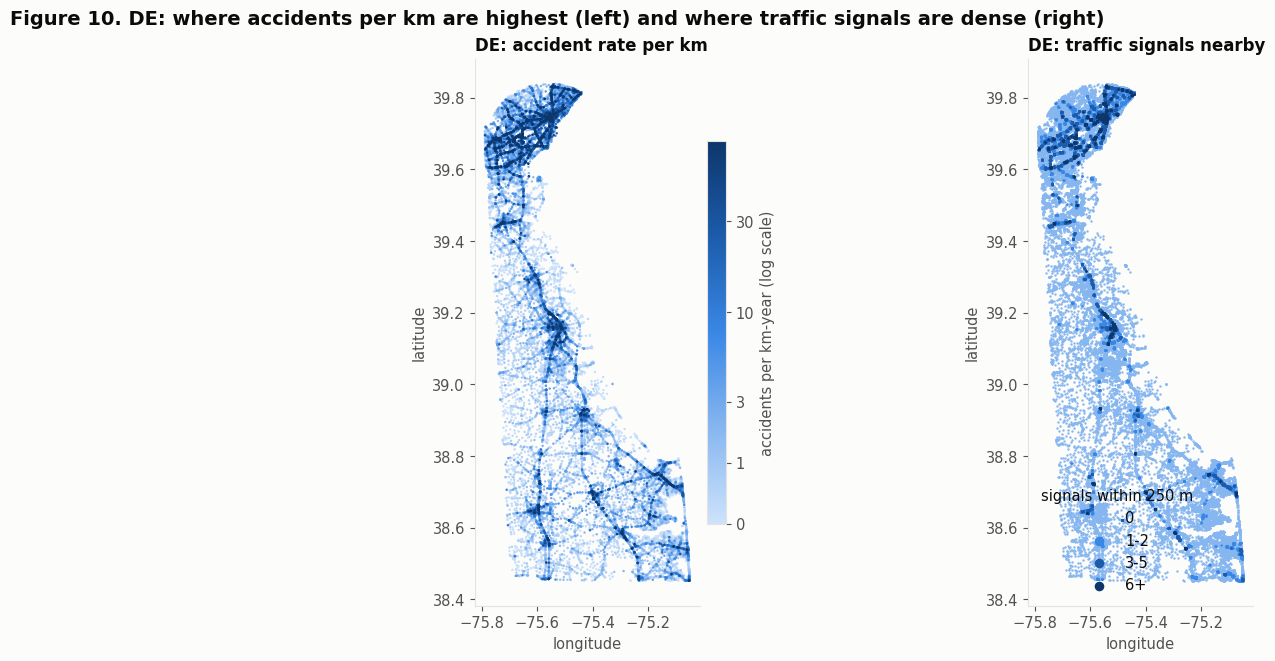

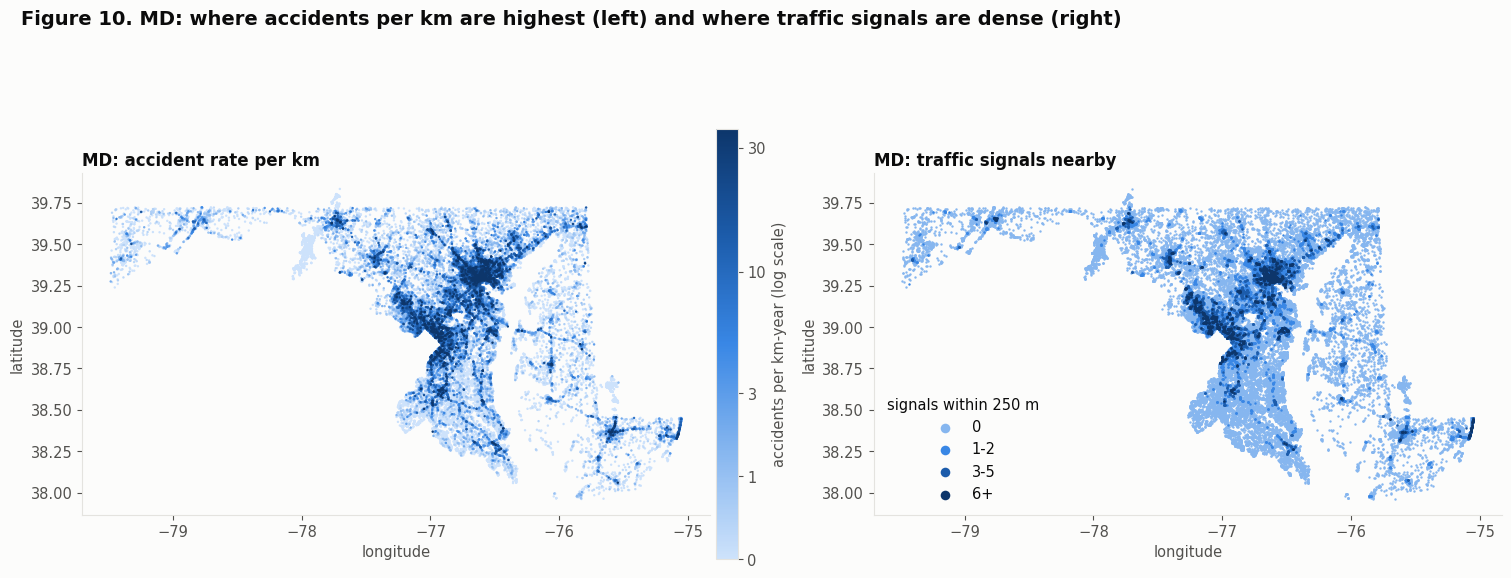

In [55]:
def plot_risk_map(state, info, analysis, max_points=60000):
    """Figure 10: a map of the state's roads. Left: accident rate per km-year. Right: traffic signals within 250 m."""
    apply_chart_style()
    levels, years = analysis["levels"], analysis["years"]
    nodes = pd.read_csv(next((info["filepath"] / "Nodes").glob("node_features_*.csv")))[["lat", "lon"]]
    nodes = nodes.rename(columns={"lat": "lon", "lon": "lat"})  # the release has the two columns swapped
    road_u = levels.index.get_level_values("road_u").to_numpy()
    road_v = levels.index.get_level_values("road_v").to_numpy()
    lat = (nodes["lat"].to_numpy()[road_u] + nodes["lat"].to_numpy()[road_v]) / 2
    lon = (nodes["lon"].to_numpy()[road_u] + nodes["lon"].to_numpy()[road_v]) / 2
    rate = levels["accidents"].to_numpy() / (levels["length_m"].to_numpy() / 1000 * years)
    value = np.log10(1 + rate)

    keep = np.arange(len(levels))
    if len(keep) > max_points:
        keep = np.random.default_rng(RANDOM_SEED).choice(keep, size=max_points, replace=False)
    keep = keep[np.argsort(value[keep])]  # low first, high last

    fig, (ax_rate, ax_signals) = plt.subplots(1, 2, figsize=(15, 6.5), layout="constrained")
    drawn = ax_rate.scatter(lon[keep], lat[keep], c=value[keep], cmap=SEQ_CMAP, vmin=0, vmax=np.percentile(value, 99), s=3, linewidths=0, rasterized=True)
    colorbar = fig.colorbar(drawn, ax=ax_rate, shrink=0.7, pad=0.01)
    ticks = np.array([t for t in (0, 1, 3, 10, 30, 100, 300) if np.log10(1 + t) <= np.percentile(value, 99)])
    colorbar.set_ticks(np.log10(1 + ticks))
    colorbar.set_ticklabels([str(t) for t in ticks])
    colorbar.set_label("accidents per km-year (log scale)")
    ax_rate.set_title(f"{state}: accident rate per km")

    order = LEVEL_ORDER["signals_within_250m"]
    signal_level = levels["signals_within_250m"].to_numpy()
    for level, colour in zip(order, [BLUE_RAMP[1], BLUE_RAMP[2], BLUE_RAMP[3], BLUE_RAMP[4]]):
        mask = np.zeros(len(levels), dtype=bool)
        mask[keep] = signal_level[keep] == level
        ax_signals.scatter(lon[mask], lat[mask], color=colour, s=3, linewidths=0, rasterized=True, label=level)
    ax_signals.legend(title="signals within 250 m", markerscale=4, loc="lower left")
    ax_signals.set_title(f"{state}: traffic signals nearby")
    for ax in (ax_rate, ax_signals):
        ax.set_aspect(1 / np.cos(np.radians(lat.mean())))
        ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
    fig.suptitle(f"Figure 10. {state}: where accidents per km are highest (left) and where traffic signals are dense (right)", x=0.01, ha="left")
    save_figure(fig, f"fig10_map_{state}")
    plt.show()


for state in STATES:
    plot_risk_map(state, data[state], analyses[state][HEADLINE])

## Appendix B. Reproducibility check for Delaware (optional)
Set `RUN_DELAWARE_CHECK = True` in the config. It rebuilds Delaware with the memory-saving pipeline **without saving** and compares every column with the saved file; this takes a while and needs the OSM tables.

In [56]:
def compare_with_saved(state, result, data_dir):
    """Check a freshly built feature table against the one saved on Drive, column by column.

    Why: to confirm that a change to the pipeline (here, lookups that no longer use the graph) did not change the results.

    Takes: the state, the dict from `build_state_features`, and the Drive data folder.
    Returns: only the columns that are not identical, with the share of equal values and the largest difference.
    Also prints how many columns match exactly and how often the road match type agrees.
    """
    saved = pd.read_parquet(data_dir / f"{state}_osm_edge_features.parquet")
    new = result["road_features"]
    assert len(saved) == len(new), "different number of roads"
    print(f"match_type agrees on {(saved['match_type'].to_numpy() == result['roads']['match_type'].to_numpy()).mean():.4f} of roads")

    rows = []
    for column in [c for c in saved.columns if re.match(r"g\d_", c)]:
        old_values, new_values = saved[column], new[column]
        if old_values.dtype == object:
            same = ((old_values == new_values) | (old_values.isna() & new_values.isna())).mean()
            difference = np.nan
        else:
            same = np.isclose(old_values.to_numpy(dtype=float), new_values.to_numpy(dtype=float), equal_nan=True).mean()
            difference = np.nanmax(np.abs(old_values.to_numpy(dtype=float) - new_values.to_numpy(dtype=float)))
        rows.append({"column": column, "share_equal": same, "max_abs_difference": difference})
    table = pd.DataFrame(rows)
    print(f"columns identical: {(table['share_equal'] == 1).sum()} of {len(table)}")
    return table[table["share_equal"] < 1]

In [57]:
if RUN_DELAWARE_CHECK:
    build_osm_tables("DE", DATA_DIR, LOCAL_DATA_DIR)
    de_check = build_state_features("DE", data, DATA_DIR, LOCAL_DATA_DIR, save=False)
    display(compare_with_saved("DE", de_check, DATA_DIR))
else:
    print("skipped (RUN_DELAWARE_CHECK is False)")

skipped (RUN_DELAWARE_CHECK is False)
